In [ ]:
import subprocess, sys
packages = ["pymannkendall", "ruptures", "statsmodels", "scikit-learn",
            "scipy", "seaborn", "openpyxl", "matplotlib"]
for pkg in packages:
    subprocess.check_call([sys.executable, "-m", "pip", "install", pkg, "-q"])
print("✓ All libraries installed.")
!winget install Microsoft.Pandoc

✓ All libraries installed.


In [3]:
import os, warnings
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import matplotlib.patches as mpatches
import matplotlib.ticker as mticker
import matplotlib.dates as mdates
from matplotlib.colors import LinearSegmentedColormap, TwoSlopeNorm
import seaborn as sns
from scipy import stats
from scipy.cluster import hierarchy
from scipy.spatial.distance import pdist
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
import pymannkendall as mk
from statsmodels.tsa.seasonal import STL
import ruptures as rpt

warnings.filterwarnings("ignore")

# ── Color Palettes ─────────────────────────────────────────────────────────────
CITY_COLORS = {
    "Delhi"   : "#C0392B",
    "Lahore"  : "#2471A3",
    "Dhaka"   : "#1E8449",
    "Karachi" : "#D4830D",
    "Mumbai"  : "#7D3C98",
}
CITY_LIGHT = {
    "Delhi"   : "#FADBD8",
    "Lahore"  : "#D6EAF8",
    "Dhaka"   : "#D5F5E3",
    "Karachi" : "#FDEBD0",
    "Mumbai"  : "#E8DAEF",
}
GAS_COLORS = {
    "NO2"  : "#E74C3C",
    "SO2"  : "#F39C12",
    "O3"   : "#2980B9",
    "HCHO" : "#27AE60",
    "CO"   : "#8E44AD",
}
SEASON_COLORS = {
    "Winter(DJF)"       : "#3498DB",
    "Pre-Monsoon(MAM)"  : "#F39C12",
    "Monsoon(JJA)"      : "#27AE60",
    "Post-Monsoon(SON)" : "#E67E22",
}
SEASON_ORDER = ["Winter(DJF)", "Pre-Monsoon(MAM)", "Monsoon(JJA)", "Post-Monsoon(SON)"]
GAS_UNITS    = {g: "mol/m²" for g in ["NO2","SO2","O3","HCHO","CO"]}
GAS_FULL     = {
    "NO2"  : "Nitrogen Dioxide (NO₂)",
    "SO2"  : "Sulfur Dioxide (SO₂)",
    "O3"   : "Ozone (O₃)",
    "HCHO" : "Formaldehyde (HCHO)",
    "CO"   : "Carbon Monoxide (CO)",
}
CITIES = ["Delhi", "Lahore", "Dhaka", "Karachi", "Mumbai"]
GASES  = ["NO2", "SO2", "O3", "HCHO", "CO"]

# ── Custom Colormaps ───────────────────────────────────────────────────────────
POLLUTION_CMAP = LinearSegmentedColormap.from_list(
    "pollution", ["#EAF4FB","#AED6F1","#F9E79F","#F0B27A","#C0392B","#6E2C00"], N=256)
DIVERGE_CMAP = LinearSegmentedColormap.from_list(
    "diverge", ["#2471A3","#FFFFFF","#C0392B"], N=256)
ANOMALY_CMAP = LinearSegmentedColormap.from_list(
    "anomaly", ["#1A5276","#2E86C1","#FFFFFF","#E74C3C","#922B21"], N=256)

# ── Figure Style ───────────────────────────────────────────────────────────────
plt.rcParams.update({
    "font.family"       : "serif",
    "font.serif"        : ["Georgia", "Times New Roman", "DejaVu Serif"],
    "axes.spines.top"   : False,
    "axes.spines.right" : False,
    "axes.linewidth"    : 0.8,
    "axes.labelsize"    : 11,
    "axes.titlesize"    : 13,
    "axes.titleweight"  : "bold",
    "xtick.labelsize"   : 9,
    "ytick.labelsize"   : 9,
    "legend.fontsize"   : 9,
    "legend.framealpha" : 0.9,
    "legend.edgecolor"  : "#CCCCCC",
    "figure.facecolor"  : "white",
    "axes.facecolor"    : "#FAFAFA",
    "grid.color"        : "#E5E5E5",
    "grid.linewidth"    : 0.6,
    "savefig.dpi"       : 300,
    "savefig.bbox"      : "tight",
    "savefig.facecolor" : "white",
})

# ── Helper Functions ───────────────────────────────────────────────────────────
def add_watermark(fig, text="Sentinel-5P TROPOMI  |  2019–2025  |  South Asian Megacities"):
    fig.text(0.5, 0.005, text, ha="center", va="bottom",
             fontsize=7, color="#AAAAAA", style="italic")

def save_fig(fig, path):
    fig.savefig(path, dpi=600, bbox_inches="tight", facecolor="white", edgecolor="none")
    plt.show()
    print(f"  ✓ Saved → {os.path.basename(path)}")

def sci_fmt(ax, axis="y"):
    ax.ticklabel_format(style="sci", axis=axis, scilimits=(0,0), useMathText=True)

print("✓ Imports and design system ready.")

✓ Imports and design system ready.


In [5]:

DATA_PATH   = r"S:\R & P\Research\All Data.xlsx"
OUTPUT_ROOT = r"S:\R & P\Research\ALL RESEARCH"

FOLDERS = {
    "stats"      : "01_Descriptive_Statistics",
    "temporal"   : "02_Temporal_Analysis",
    "seasonal"   : "03_Seasonal_Analysis",
    "trend"      : "04_Trend_Analysis",
    "covid"      : "05_COVID_Impact",
    "corr"       : "06_Correlation_Analysis",
    "pca"        : "07_Multivariate_PCA_HCA",
    "crosscity"  : "08_Cross_City_Comparison",
    "changepoint": "09_Change_Point_Detection",
    "stl"        : "10_STL_Decomposition",
    "tables"     : "11_Summary_Tables",
}

for folder in FOLDERS.values():
    full_path = os.path.join(OUTPUT_ROOT, folder)
    os.makedirs(full_path, exist_ok=True)

def out(key, filename):
    """Return full output path for a given folder key and filename."""
    return os.path.join(OUTPUT_ROOT, FOLDERS[key], filename)

print("✓ Output folders created:")
for k, v in FOLDERS.items():
    print(f"   📁 {v}")

✓ Output folders created:
   📁 01_Descriptive_Statistics
   📁 02_Temporal_Analysis
   📁 03_Seasonal_Analysis
   📁 04_Trend_Analysis
   📁 05_COVID_Impact
   📁 06_Correlation_Analysis
   📁 07_Multivariate_PCA_HCA
   📁 08_Cross_City_Comparison
   📁 09_Change_Point_Detection
   📁 10_STL_Decomposition
   📁 11_Summary_Tables


In [7]:
sheets = pd.read_excel(DATA_PATH, sheet_name=None)
dfs    = {}

for city in CITIES:
    df = sheets[city].copy()
    df.columns = df.columns.str.strip()

    # Auto-rename columns to standard names
    rename = {}
    for col in df.columns:
        cl = col.lower().replace(" ","").replace("(mol/m2)","").replace("(mol/m²)","")
        if "date"   in cl:       rename[col] = "Date"
        elif "year" in cl:       rename[col] = "Year"
        elif col.lower() == "month": rename[col] = "Month"
        elif "season" in cl:     rename[col] = "Season"
        elif "no2"  in cl:       rename[col] = "NO2"
        elif "so2"  in cl:       rename[col] = "SO2"
        elif cl.startswith("o3") or cl == "o3": rename[col] = "O3"
        elif "hcho" in cl:       rename[col] = "HCHO"
        elif "co"   == cl:       rename[col] = "CO"

    df.rename(columns=rename, inplace=True)
    df["Date"]   = pd.to_datetime(df["Date"])
    df["City"]   = city
    df["Season"] = df["Season"].str.strip()
    dfs[city]    = df.sort_values("Date").reset_index(drop=True)

# Combined long-format dataframe
all_df = pd.concat(dfs.values(), ignore_index=True)
all_df.sort_values(["City", "Date"], inplace=True)
all_df.reset_index(drop=True, inplace=True)

COVID_START = pd.Timestamp("2020-03-01")
COVID_END   = pd.Timestamp("2020-06-30")

print(f"✓ Data loaded successfully")
print(f"   Cities  : {list(dfs.keys())}")
print(f"   Rows    : {len(all_df)}")
print(f"   Period  : {all_df['Date'].min().date()} → {all_df['Date'].max().date()}")
print(f"\n   Columns per city sheet:")
for city in CITIES:
    print(f"   {city:8s}: {list(dfs[city].columns)}")

✓ Data loaded successfully
   Cities  : ['Delhi', 'Lahore', 'Dhaka', 'Karachi', 'Mumbai']
   Rows    : 420
   Period  : 2019-01-01 → 2025-12-01

   Columns per city sheet:
   Delhi   : ['Date', 'Year', 'Month', 'Season', 'NO2', 'SO2', 'O3', 'HCHO', 'CO', 'City']
   Lahore  : ['Date', 'Year', 'Month', 'Season', 'NO2', 'SO2', 'O3', 'HCHO', 'CO', 'City']
   Dhaka   : ['Date', 'Year', 'Month', 'Season', 'NO2', 'SO2', 'O3', 'HCHO', 'CO', 'City']
   Karachi : ['Date', 'Year', 'Month', 'Season', 'NO2', 'SO2', 'O3', 'HCHO', 'CO', 'City']
   Mumbai  : ['Date', 'Year', 'Month', 'Season', 'NO2', 'SO2', 'O3', 'HCHO', 'CO', 'City']


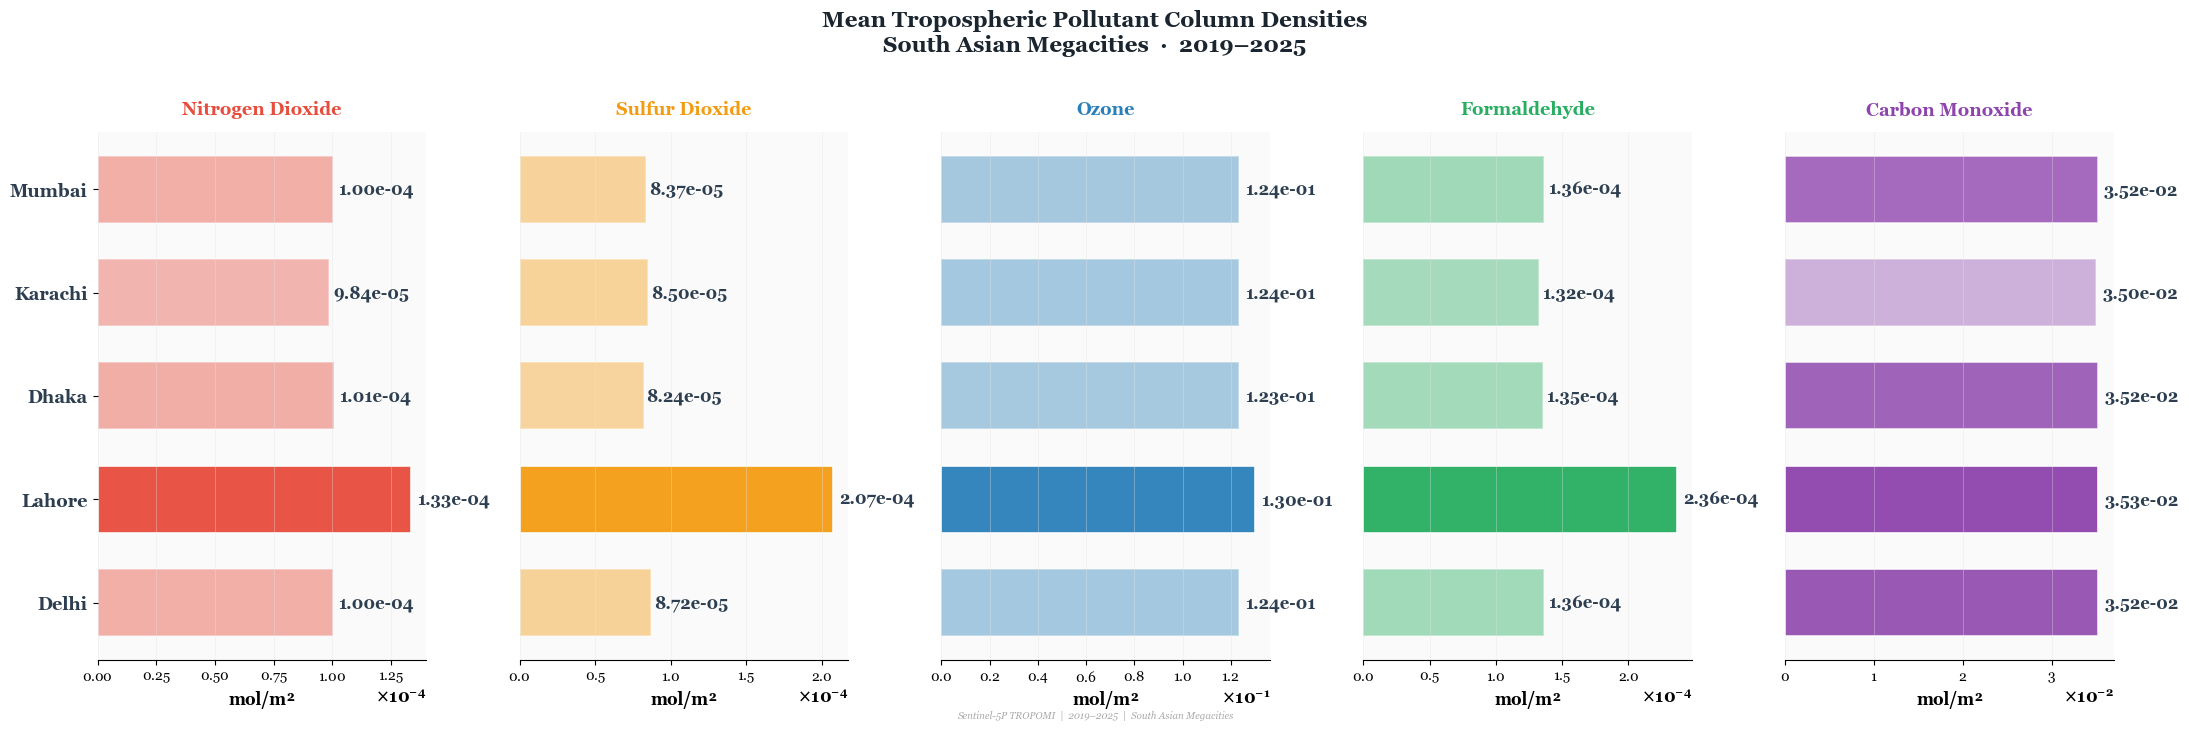

  ✓ Saved → Fig1_Descriptive_Stats_Mean_Bars.png


In [9]:
# ── STEP 1: Generate stats_df DataFrame ──────────────────────────────────────
stat_rows = []
for city in CITIES:
    for gas in GASES:
        s = dfs[city][gas].dropna()
        stat_rows.append(
            {
                "City": city,
                "Gas": gas,
                "N": len(s),
                "Mean": s.mean(),
                "Median": s.median(),
                "Std Dev": s.std(),
                "Min": s.min(),
                "Max": s.max(),
                "Range": s.max() - s.min(),
                "CV (%)": (
                    s.std() / abs(s.mean()) * 100 if s.mean() != 0 else np.nan
                ),
                "Skewness": s.skew(),
                "Kurtosis": s.kurtosis(),
                "Q25": s.quantile(0.25),
                "Q75": s.quantile(0.75),
                "IQR": s.quantile(0.75) - s.quantile(0.25),
            }
        )

stats_df = pd.DataFrame(stat_rows)
stats_df.to_csv(out("tables", "Table2_Descriptive_Statistics.csv"), index=False)

# ── STEP 2: Plot Mean Concentration Bar Chart ────────────────────────────────
fig, axes = plt.subplots(1, 5, figsize=(22, 7))
fig.suptitle(
    "Mean Tropospheric Pollutant Column Densities\nSouth Asian Megacities  ·  2019–2025",
    fontsize=16,
    fontweight="bold",
    y=1.02,
    color="#1A252F",
)

for ax_i, gas in enumerate(GASES):
    ax = axes[ax_i]
    vals = stats_df[stats_df["Gas"] == gas].set_index("City")["Mean"]
    norm = (vals - vals.min()) / (vals.max() - vals.min() + 1e-30)

    # 1. BAR THICKNESS CONTROL
    BAR_HEIGHT = 0.65

    for c_i, city in enumerate(CITIES):
        alpha_val = float(0.4 + 0.55 * norm[city])
        ax.barh(
            city,
            vals[city],
            color=GAS_COLORS[gas],
            alpha=alpha_val,
            edgecolor="white",
            linewidth=1.2,
            height=BAR_HEIGHT,
        )

        # Values next to bars
        ax.text(
            vals[city] * 1.02,
            c_i,
            f"{vals[city]:.2e}",
            va="center",
            ha="left",
            fontsize=12,
            color="#2C3E50",
            fontweight="bold",
        )

    # Clean Gas Title
    clean_title = (
        GAS_FULL[gas]
        .replace(" (NO₂)", "")
        .replace(" (SO₂)", "")
        .replace(" (O₃)", "")
        .replace(" (HCHO)", "")
        .replace(" (CO)", "")
    )
    ax.set_title(
        clean_title,
        fontsize=13,
        fontweight="bold",
        color=GAS_COLORS[gas],
        pad=12,
    )
    ax.set_xlabel("mol/m²", fontsize=12, fontweight="bold")

    # Format axis into scientific notation
    sci_fmt(ax, axis="x")

    # 2. SCIENTIFIC NOTATION (10^-4) SIZE CONTROL
    ax.xaxis.get_offset_text().set_fontsize(12)
    ax.xaxis.get_offset_text().set_fontweight("bold")

    # 3. TICKS & CITY LABELS SIZE CONTROL
    ax.tick_params(axis="x", labelsize=10)
    ax.tick_params(axis="y", labelsize=14)

    ax.grid(axis="x", alpha=0.4)
    ax.spines["left"].set_visible(False)

    # Formatting city labels on y-axis
    if ax_i == 0:
        ax.set_yticklabels(
            CITIES, fontsize=13, fontweight="bold", color="#2C3E50"
        )
    else:
        ax.set_yticklabels([])
        ax.tick_params(left=False)

add_watermark(fig)
plt.tight_layout()
save_fig(fig, out("stats", "Fig1_Descriptive_Stats_Mean_Bars.png"))

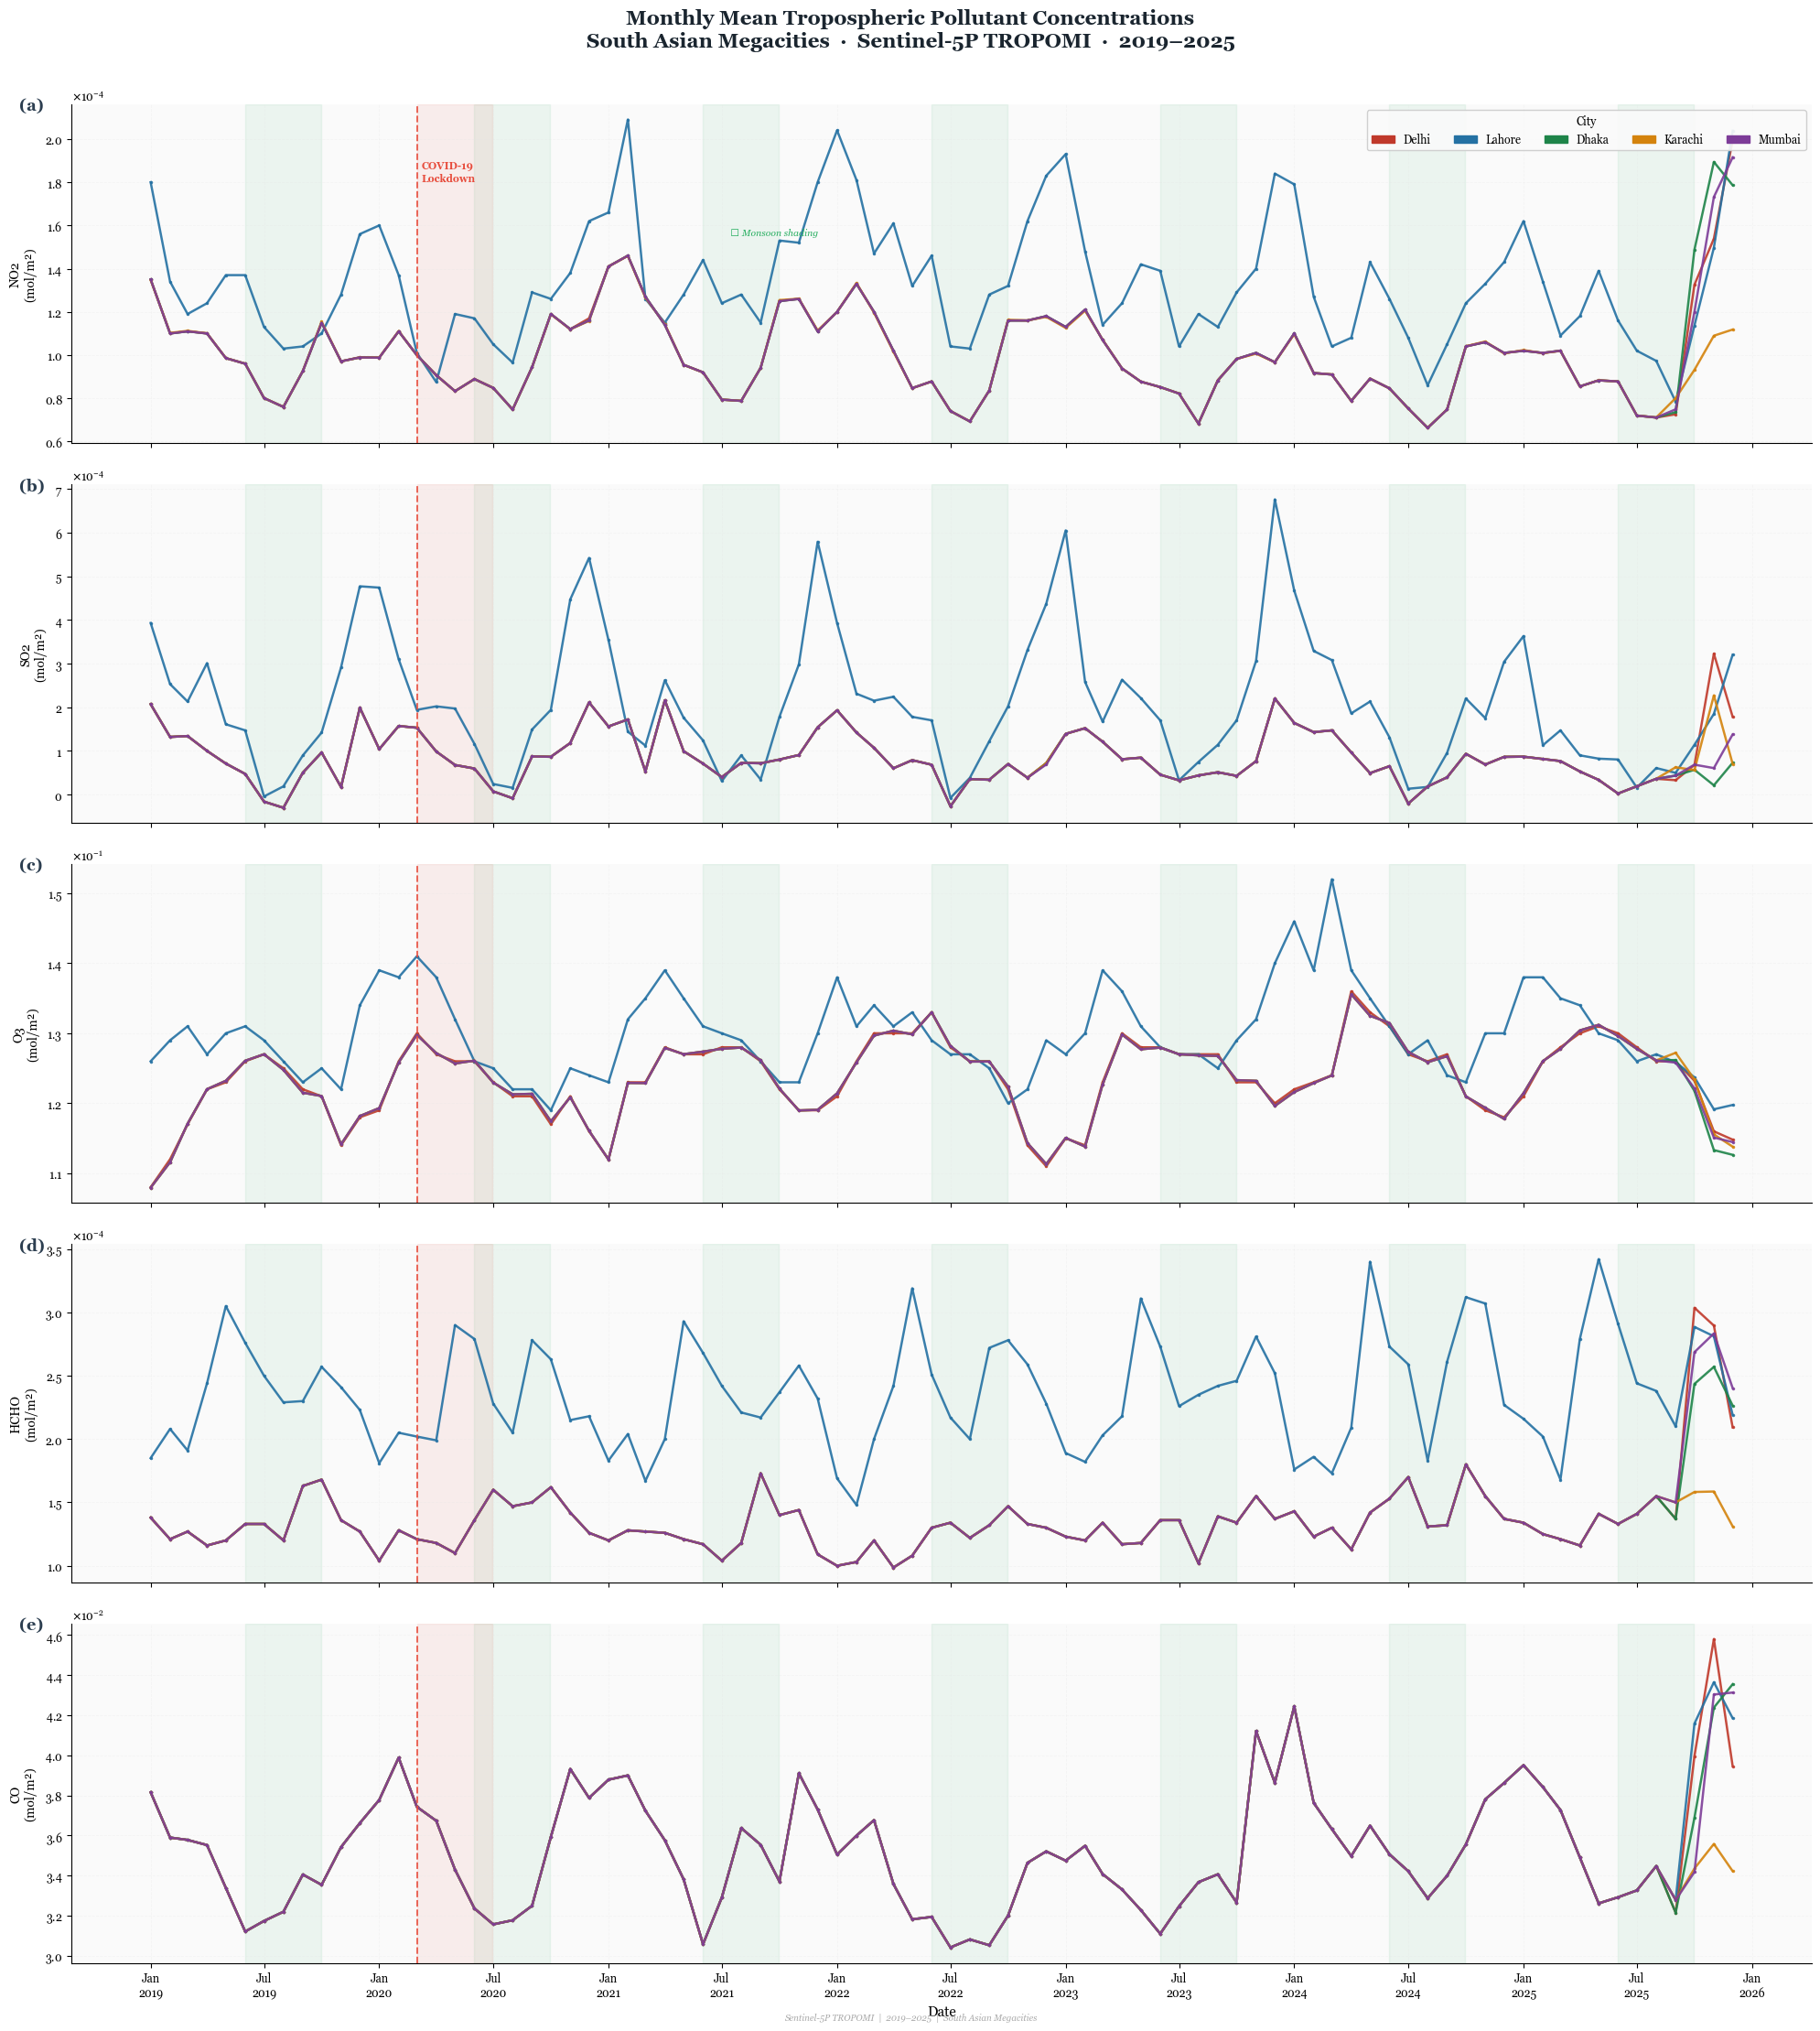

  ✓ Saved → Fig2_Time_Series_All_Gases_Cities.png
✓ Figure 2 — Time Series saved.


In [11]:
fig, axes = plt.subplots(5, 1, figsize=(20, 22), sharex=True)
fig.suptitle("Monthly Mean Tropospheric Pollutant Concentrations\n"
             "South Asian Megacities  ·  Sentinel-5P TROPOMI  ·  2019–2025",
             fontsize=16, fontweight="bold", y=1.005, color="#1A252F")

monsoon_spans = [(f"{y}-06-01", f"{y}-09-30") for y in range(2019, 2026)]

for ax_i, gas in enumerate(GASES):
    ax = axes[ax_i]

    # Monsoon shading
    for ms, me in monsoon_spans:
        ax.axvspan(pd.Timestamp(ms), pd.Timestamp(me),
                   alpha=0.07, color="#27AE60", zorder=0)

    # COVID shading
    ax.axvspan(COVID_START, COVID_END, alpha=0.08, color="#E74C3C", zorder=0)
    ax.axvline(COVID_START, color="#E74C3C", linewidth=1.4,
               linestyle="--", alpha=0.85, zorder=5)

    # Plot each city
    for city in CITIES:
        df_city = dfs[city].set_index("Date")[gas].dropna()
        ax.plot(df_city.index, df_city.values,
                color=CITY_COLORS[city], linewidth=1.8, alpha=0.9,
                label=city, marker="o", markersize=2.5, markeredgewidth=0)

    ax.set_ylabel(f"{gas}\n(mol/m²)", fontsize=10, labelpad=6)
    sci_fmt(ax, axis="y")
    ax.grid(True, alpha=0.3, linestyle="--")

    # Panel label
    ax.text(-0.03, 1.02, f"({chr(97+ax_i)})", transform=ax.transAxes,
            fontsize=13, fontweight="bold", va="top", color="#2C3E50")

    if ax_i == 0:
        handles = [mpatches.Patch(color=CITY_COLORS[c], label=c) for c in CITIES]
        ax.legend(handles=handles, loc="upper right", ncol=5,
                  framealpha=0.92, fontsize=9, title="City", title_fontsize=9)
        ylim_top = ax.get_ylim()[1]
        ax.text(COVID_START + pd.Timedelta(days=8), ylim_top * 0.88,
                "COVID-19\nLockdown", color="#E74C3C",
                fontsize=8, fontweight="bold", va="top")
        ax.text(pd.Timestamp("2021-07-15"), ylim_top * 0.72,
                "◀ Monsoon shading", color="#27AE60", fontsize=7.5, style="italic")

axes[-1].xaxis.set_major_locator(mdates.MonthLocator(interval=6))
axes[-1].xaxis.set_major_formatter(mdates.DateFormatter("%b\n%Y"))
axes[-1].set_xlabel("Date", fontsize=11)

plt.tight_layout()                    # ← no arguments
fig.subplots_adjust(hspace=0.12)      # ← hspace goes here
add_watermark(fig)
save_fig(fig, out("temporal","Fig2_Time_Series_All_Gases_Cities.png"))
print("✓ Figure 2 — Time Series saved.")

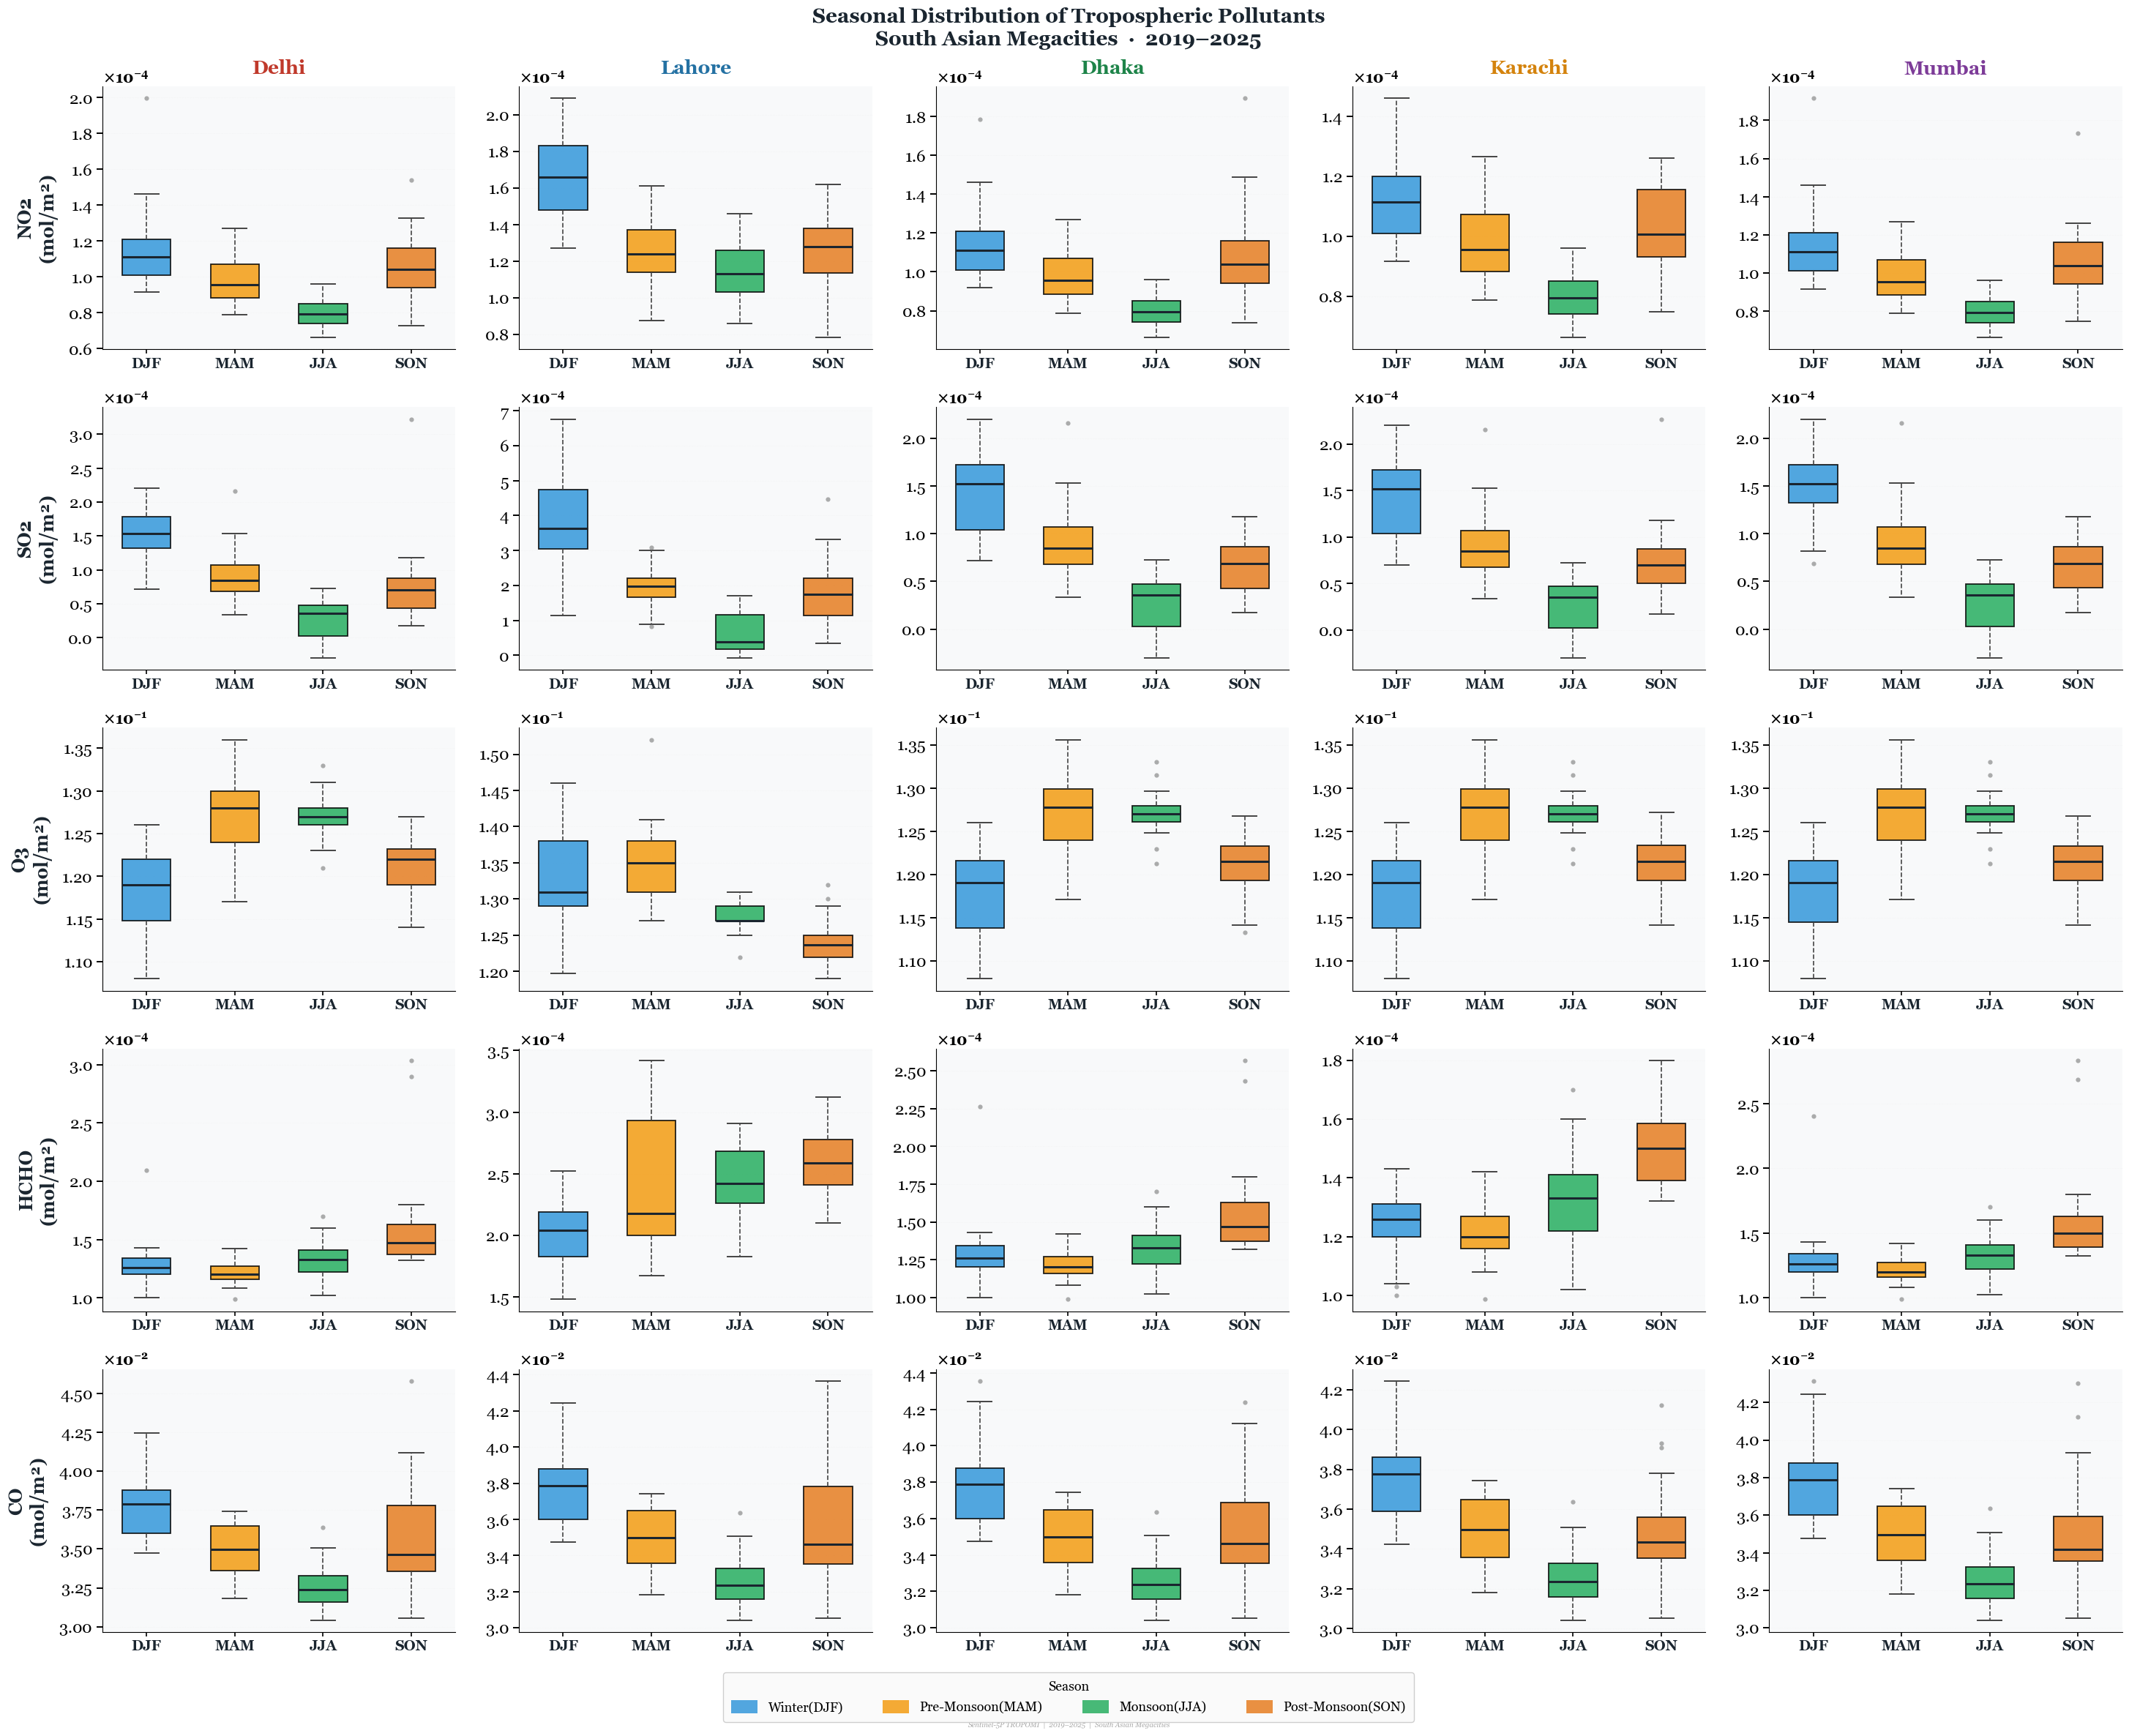

✓ Figure 3 saved: Plots expanded, gaps reduced, Y-axis numbers enlarged.


In [13]:
# ── CELL 7 — Seasonal Box Plots (Expanded Plots & Large Y-Axis Labels) ────────

fig, axes = plt.subplots(5, 5, figsize=(30, 24))

# Set clean white background
fig.patch.set_facecolor("white")

# Main Figure Title
fig.suptitle(
    "Seasonal Distribution of Tropospheric Pollutants\n"
    "South Asian Megacities  ·  2019–2025",
    fontsize=20,
    fontweight="bold",
    y=0.985,
    color="#1A252F",
)

for row_i, gas in enumerate(GASES):
    for col_i, city in enumerate(CITIES):
        ax = axes[row_i][col_i]
        df = dfs[city].copy()
        df["Season"] = pd.Categorical(
            df["Season"], categories=SEASON_ORDER, ordered=True
        )
        groups = [
            df[df["Season"] == s][gas].dropna().values for s in SEASON_ORDER
        ]

        # Boxplot styling
        bplot = ax.boxplot(
            groups,
            patch_artist=True,
            notch=False,
            widths=0.55,
            flierprops=dict(
                marker="o",
                markersize=4.5,
                markerfacecolor="#777777",
                markeredgecolor="none",
                alpha=0.6,
            ),
            medianprops=dict(color="#1A252F", linewidth=2.2),
            whiskerprops=dict(linewidth=1.2, linestyle="--", color="#444444"),
            capprops=dict(linewidth=1.4, color="#444444"),
            boxprops=dict(linewidth=1.3),
        )

        for patch, season in zip(bplot["boxes"], SEASON_ORDER):
            patch.set_facecolor(SEASON_COLORS[season])
            patch.set_alpha(0.85)

        # ── 1. EXTRA-LARGE Y-AXIS NUMERICAL VALUES & MULTIPLIER ────────────────
        ax.ticklabel_format(
            style="sci", axis="y", scilimits=(0, 0), useMathText=True
        )

        # Scientific notation size (e.g. 10^-4 at top left of each box)
        ax.yaxis.get_offset_text().set_fontsize(15)  # ◄── BIGGER 10^-4 exponent
        ax.yaxis.get_offset_text().set_fontweight("bold")

        # Y-Axis numbers (e.g., 0.5, 1.0, 1.5...)
        ax.tick_params(
            axis="y", labelsize=16, length=6, width=1.4
        )  # ◄── MUCH BIGGER Y-axis values

        # ── 2. X-AXIS SEASON LABELS ───────────────────────────────────────────
        ax.set_xticks([1, 2, 3, 4])
        ax.set_xticklabels(
            ["DJF", "MAM", "JJA", "SON"],
            fontsize=14,
            fontweight="bold",
            color="#1A252F",
        )
        ax.tick_params(axis="x", length=4, width=1.2)

        ax.grid(axis="y", alpha=0.35, linestyle=":")
        ax.set_facecolor("#F8F9FA")

        # ── CITY NAMES (COLUMN TITLES) ────────────────────────────────────────
        if row_i == 0:
            ax.set_title(
                city,
                fontsize=19,
                fontweight="bold",
                color=CITY_COLORS[city],
                pad=12,
            )

        # ── ROW LABELS (GAS NAMES & UNITS) ────────────────────────────────────
        if col_i == 0:
            ax.set_ylabel(
                f"{gas}\n(mol/m²)",
                fontsize=18,  # ◄── BIGGER Gas labels
                fontweight="bold",
                labelpad=10,
                color="#1A252F",
            )

# ── 3. REDUCE GAP BETWEEN PLOTS & EXPAND PLOT SIZES ───────────────────────────
fig.subplots_adjust(
    wspace=0.18,  # ◄── REDUCED HORIZONTAL GAP (Brings columns closer)
    hspace=0.22,  # ◄── REDUCED VERTICAL GAP (Brings rows closer & makes plots taller)
    top=0.94,  # ◄── EXPANDS GRID UPWARDS
    bottom=0.06,  # ◄── EXPANDS GRID DOWNWARDS
    left=0.06,  # ◄── EXPANDS GRID LEFT
    right=0.98,  # ◄── EXPANDS GRID RIGHT
)

# ── LEGEND CONFIGURATION ──────────────────────────────────────────────────────
legend_patches = [
    mpatches.Patch(facecolor=SEASON_COLORS[s], label=s, alpha=0.85)
    for s in SEASON_ORDER
]

fig.legend(
    handles=legend_patches,
    loc="lower center",
    ncol=4,
    fontsize=13,
    title="Season",
    title_fontsize=13,
    handlelength=2.0,
    handleheight=1.2,
    borderpad=0.6,
    columnspacing=3.0,
    bbox_to_anchor=(0.5, 0.005),  # Positioned tightly at the bottom
    framealpha=0.95,
    edgecolor="#CCCCCC",
    fancybox=True,
)

# Save image
add_watermark(fig)
fig.savefig(
    out("seasonal", "Fig3_Seasonal_BoxPlots_5x5.png"),
    dpi=600,
    bbox_inches="tight",
    facecolor="white",
    edgecolor="none",
)
plt.show()
print("✓ Figure 3 saved: Plots expanded, gaps reduced, Y-axis numbers enlarged.")

In [15]:
# Kruskal-Wallis test
kw_rows = []
for city in CITIES:
    for gas in GASES:
        df = dfs[city].copy()
        df["Season"] = pd.Categorical(df["Season"], categories=SEASON_ORDER, ordered=True)
        groups = [df[df["Season"] == s][gas].dropna().values for s in SEASON_ORDER]
        valid  = [g for g in groups if len(g) > 0]
        try:
            H, p = stats.kruskal(*valid)
            sig  = "***" if p<0.001 else "**" if p<0.01 else "*" if p<0.05 else "ns"
            kw_rows.append({"City":city,"Gas":gas,
                            "H-stat":round(H,3),"p-value":round(p,5),"Sig":sig})
        except Exception as e:
            kw_rows.append({"City":city,"Gas":gas,"H-stat":np.nan,"p-value":np.nan,"Sig":"—"})

kw_df = pd.DataFrame(kw_rows)
kw_df.to_csv(out("tables","Table6_KruskalWallis_Seasonal.csv"), index=False)

# Seasonal mean summary
seas_rows = []
for city in CITIES:
    for gas in GASES:
        df  = dfs[city].copy()
        row = {"City": city, "Gas": gas}
        for s in SEASON_ORDER:
            vals = df[df["Season"] == s][gas].dropna()
            row[s] = vals.mean()
        all_seas_vals = [row[s] for s in SEASON_ORDER]
        row["Dominant Season"] = SEASON_ORDER[int(np.argmax(all_seas_vals))]
        row["Amplitude"]       = max(all_seas_vals) - min(all_seas_vals)
        pos_vals = [v for v in all_seas_vals if v > 0]
        row["SAR"] = max(all_seas_vals) / min(pos_vals) if pos_vals else np.nan
        seas_rows.append(row)

seas_df = pd.DataFrame(seas_rows)
seas_df.to_csv(out("tables","Table4_Seasonal_Mean_Summary.csv"), index=False)

print("✓ Kruskal-Wallis Test Results:")
print(kw_df.to_string(index=False))
print("\n✓ Tables saved: Table4_Seasonal_Mean_Summary.csv, Table6_KruskalWallis_Seasonal.csv")

✓ Kruskal-Wallis Test Results:
   City  Gas  H-stat  p-value Sig
  Delhi  NO2  41.900  0.00000 ***
  Delhi  SO2  49.200  0.00000 ***
  Delhi   O3  43.586  0.00000 ***
  Delhi HCHO  33.022  0.00000 ***
  Delhi   CO  37.625  0.00000 ***
 Lahore  NO2  38.496  0.00000 ***
 Lahore  SO2  50.185  0.00000 ***
 Lahore   O3  44.414  0.00000 ***
 Lahore HCHO  22.766  0.00005 ***
 Lahore   CO  38.035  0.00000 ***
  Dhaka  NO2  41.668  0.00000 ***
  Dhaka  SO2  50.018  0.00000 ***
  Dhaka   O3  44.016  0.00000 ***
  Dhaka HCHO  33.022  0.00000 ***
  Dhaka   CO  38.771  0.00000 ***
Karachi  NO2  42.853  0.00000 ***
Karachi  SO2  47.304  0.00000 ***
Karachi   O3  43.179  0.00000 ***
Karachi HCHO  36.048  0.00000 ***
Karachi   CO  38.107  0.00000 ***
 Mumbai  NO2  42.119  0.00000 ***
 Mumbai  SO2  51.443  0.00000 ***
 Mumbai   O3  44.307  0.00000 ***
 Mumbai HCHO  33.767  0.00000 ***
 Mumbai   CO  39.142  0.00000 ***

✓ Tables saved: Table4_Seasonal_Mean_Summary.csv, Table6_KruskalWallis_Seasonal.csv


# CELL 9 — SECTION 3 (cont.): SEASONAL HEATMAP

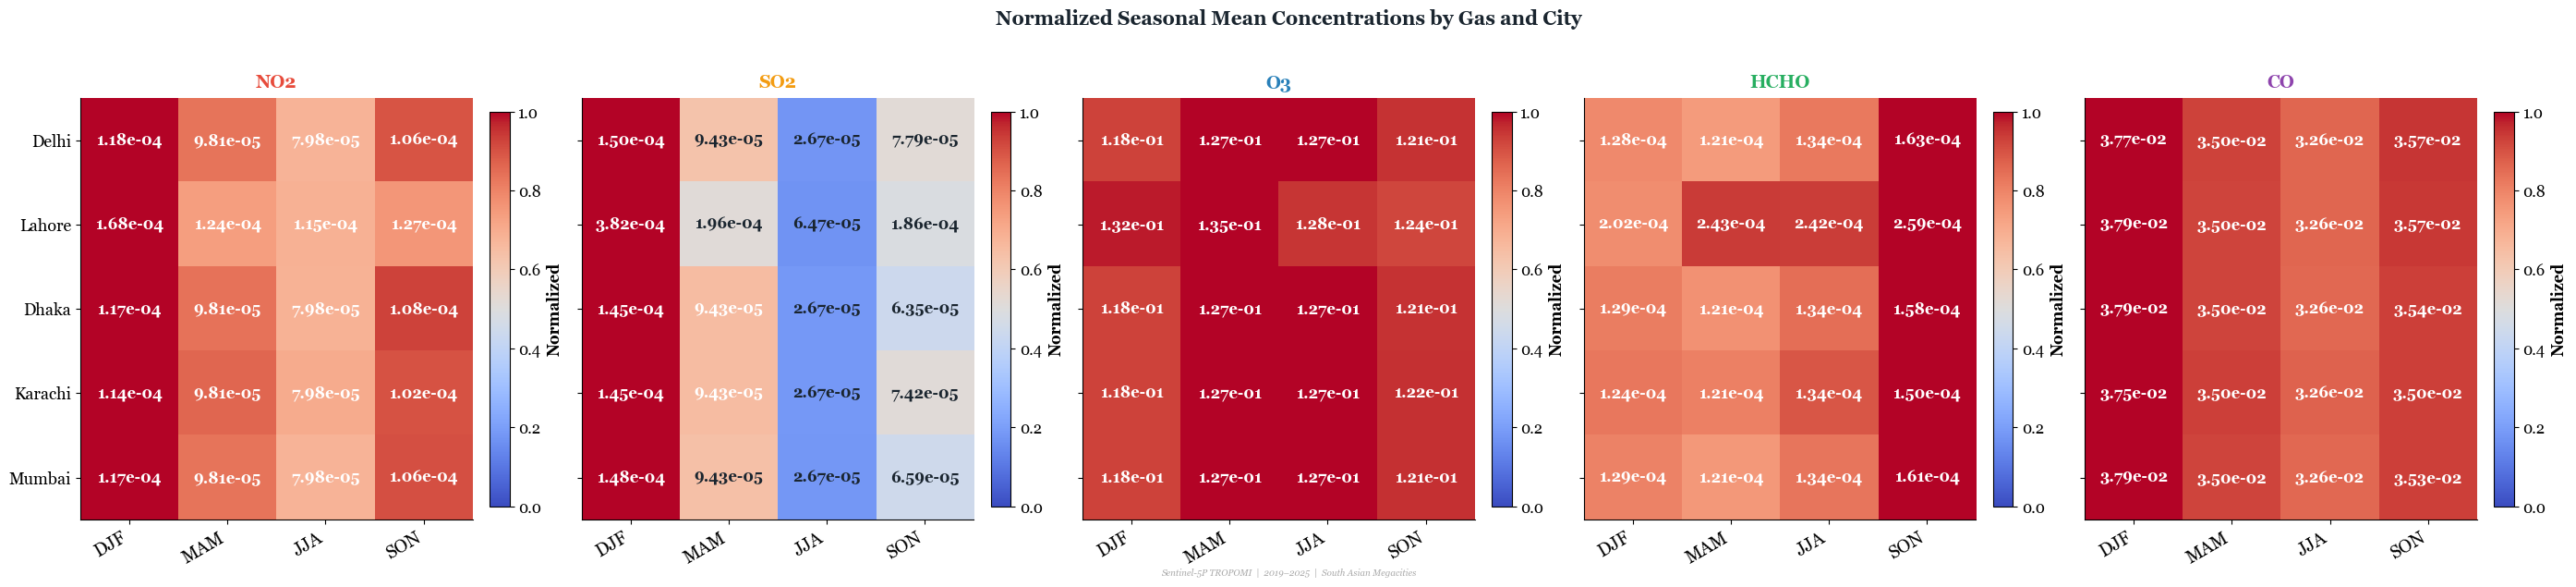

  ✓ Saved → Fig_Seasonal_Heatmap_Normalized.png
✓ Seasonal Heatmap saved.


In [17]:
# ── CELL 9 — Seasonal Heatmap (Self-contained, safe to run independently) ────

# Rebuild seas_df if it was not created by Cell 8
if 'seas_df' not in dir():
    seas_rows = []
    for city in CITIES:
        for gas in GASES:
            df  = dfs[city].copy()
            row = {"City": city, "Gas": gas}
            for s in SEASON_ORDER:
                vals = df[df["Season"] == s][gas].dropna()
                row[s] = vals.mean()
            all_seas_vals = [row[s] for s in SEASON_ORDER]
            row["Dominant Season"] = SEASON_ORDER[int(np.argmax(all_seas_vals))]
            row["Amplitude"]       = max(all_seas_vals) - min(all_seas_vals)
            pos_vals = [v for v in all_seas_vals if v > 0]
            row["SAR"] = max(all_seas_vals) / min(pos_vals) if pos_vals else np.nan
            seas_rows.append(row)
    seas_df = pd.DataFrame(seas_rows)
    print("  ⚠ seas_df was rebuilt — run Cell 8 first next time.")

# ── Plot ──────────────────────────────────────────────────────────────────────
fig, axes = plt.subplots(1, 5, figsize=(28, 6))
fig.suptitle("Normalized Seasonal Mean Concentrations by Gas and City",
             fontsize=15, fontweight="bold", y=1.03, color="#1A252F")

for ax_i, gas in enumerate(GASES):
    data_s = seas_df[seas_df["Gas"] == gas].set_index("City")[SEASON_ORDER]
    norm_s = data_s.div(data_s.max(axis=1), axis=0)
    ax     = axes[ax_i]

    im = ax.imshow(norm_s.values, aspect="auto", cmap = "coolwarm",
                   vmin=0, vmax=1, interpolation="nearest")

    ax.set_xticks(range(4))
    ax.set_xticklabels(["DJF","MAM","JJA","SON"], fontsize=14, rotation=30, ha="right")
    ax.set_yticks(range(5))
    ax.set_yticklabels(CITIES if ax_i == 0 else [], fontsize=13)
    ax.set_title(gas, fontsize=14, fontweight="bold", color=GAS_COLORS[gas], pad=8)

    for i, city in enumerate(CITIES):
        for j, s in enumerate(SEASON_ORDER):
            val  = data_s.loc[city, s]
            nval = norm_s.loc[city, s]
            ax.text(j, i, f"{val:.2e}",
                    ha="center", va="center", fontsize=12,
                    color="white" if nval > 0.65 else "#1A252F",
                    fontweight="bold")

# ── Colorbar Block ────────────────────────────────────────────────────────
    cb = plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
    cb.set_label("Normalized", fontsize=12, fontweight="bold")
    
    # CONTROL COLORBAR NUMERICAL VALUES HERE:
    cb.set_ticks([0.0, 0.2, 0.4, 0.6, 0.8, 1.0])  # Optional: set exact tick values
    cb.ax.tick_params(labelsize=12)                # Controls size of numbers (e.g., 10pt)
    
    # Optional: Make colorbar numbers bold
     #for label in cb.ax.get_yticklabels():
          #label.set_fontweight("bold")

plt.tight_layout()
add_watermark(fig)
save_fig(fig, out("seasonal", "Fig_Seasonal_Heatmap_Normalized.png"))
print("✓ Seasonal Heatmap saved.")

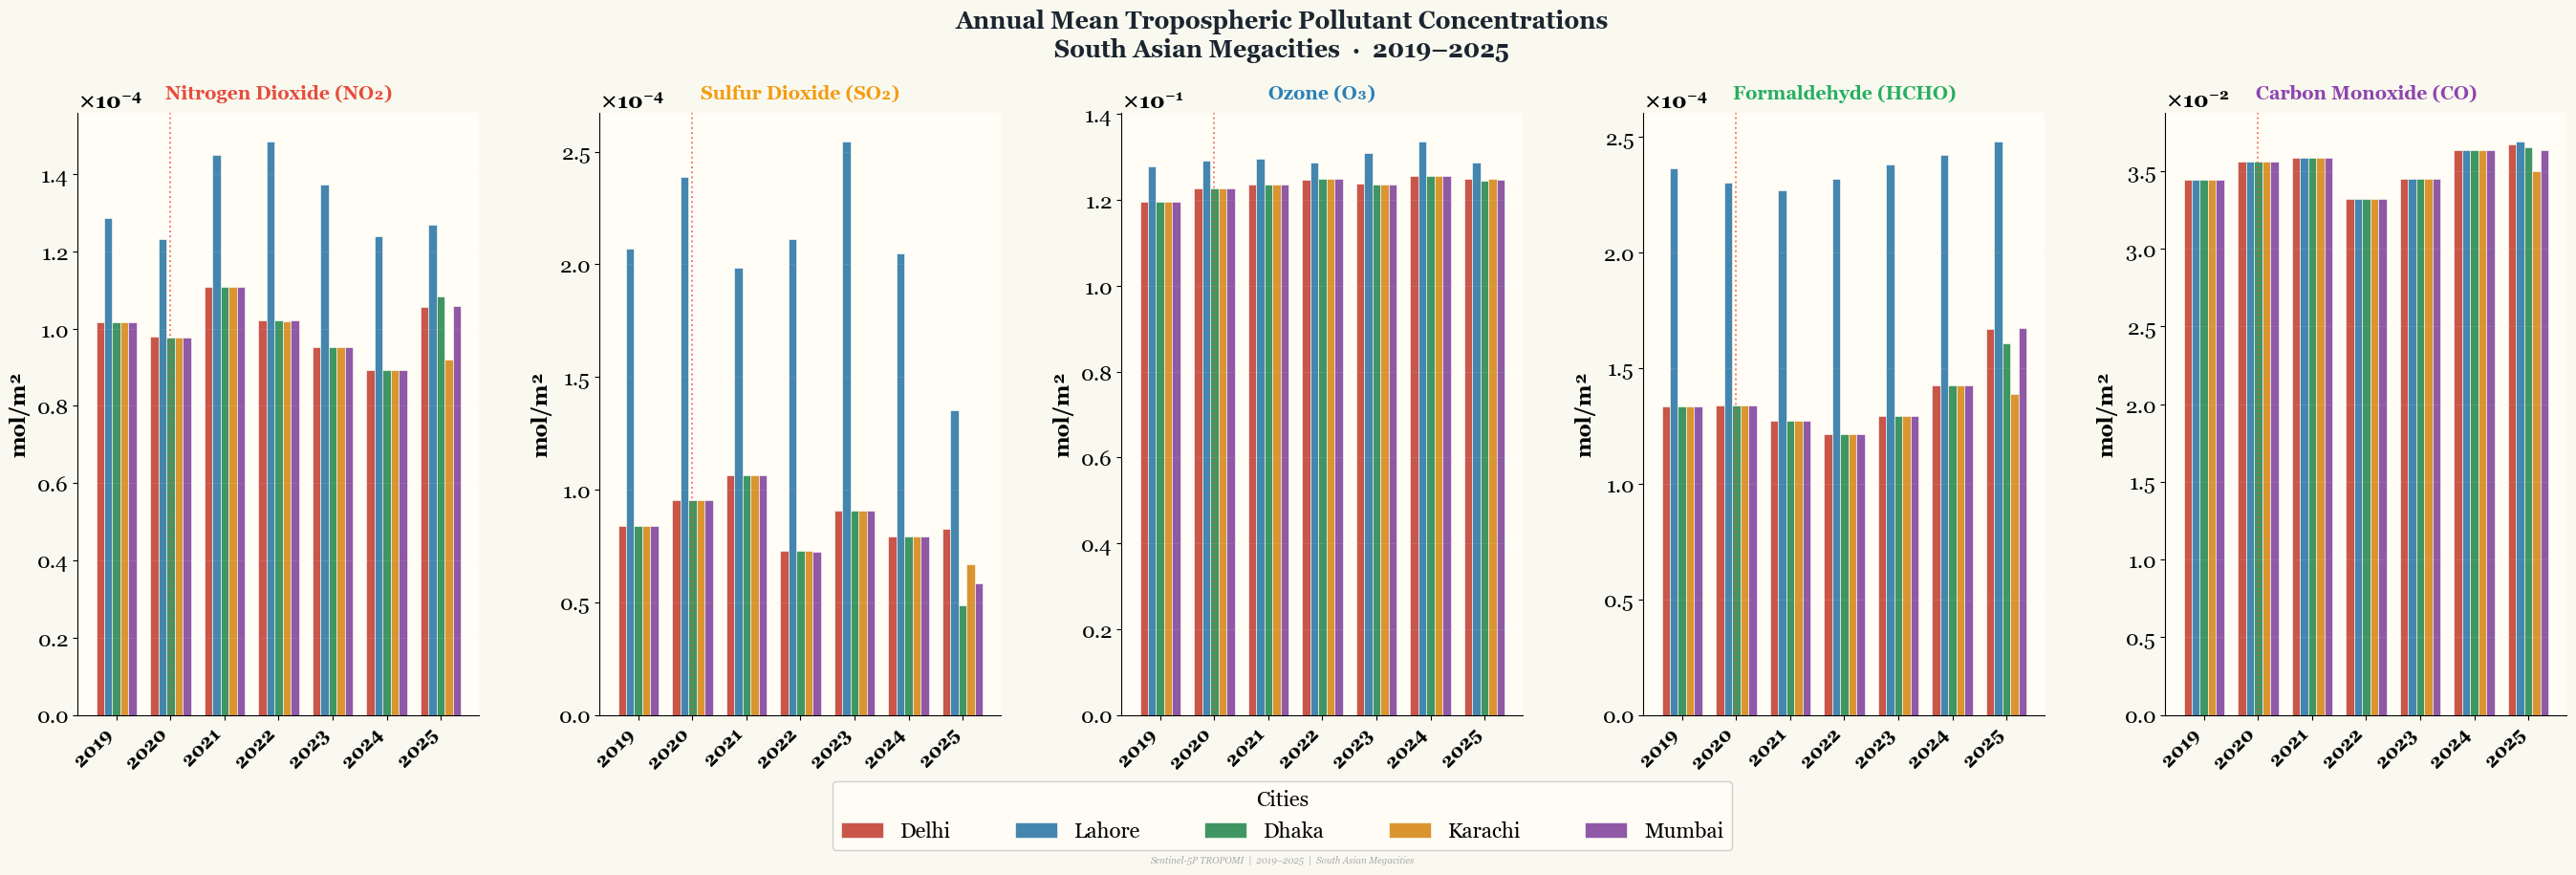

✓ Figure 4 — Saved with centered bottom legend.


In [19]:
ann_df = all_df.groupby(["City", "Year"])[GASES].mean().reset_index()

fig, axes = plt.subplots(1, 5, figsize=(28, 9))

# Set background to match your figure style
fig.patch.set_facecolor("#FAF9F0")

fig.suptitle(
    "Annual Mean Tropospheric Pollutant Concentrations\n"
    "South Asian Megacities  ·  2019–2025",
    fontsize=18,
    fontweight="bold",
    y=1,
    color="#1A252F",
)

years = sorted(ann_df["Year"].unique())
x = np.arange(len(years))
width = 0.15

for ax_i, gas in enumerate(GASES):
    ax = axes[ax_i]
    for c_i, city in enumerate(CITIES):
        vals = ann_df[ann_df["City"] == city].sort_values("Year")[gas].values
        offset = (c_i - 2) * width
        ax.bar(
            x + offset,
            vals,
            width=width,
            color=CITY_COLORS[city],
            alpha=0.85,
            label=city,
            edgecolor="white",
            linewidth=0.5,
        )

    # Subplot Title (Gas Name)
    ax.set_title(
        GAS_FULL[gas],
        fontsize=14,
        fontweight="bold",
        color=GAS_COLORS[gas],
        pad=10,
    )

    # X-Axis Year Labels
    ax.set_xticks(x)
    ax.set_xticklabels(
        years, rotation=45, ha="right", fontsize=14, fontweight="bold"
    )

    # Y-Axis Formatting
    sci_fmt(ax, axis="y")
    ax.tick_params(axis="y", labelsize=16)
    ax.yaxis.get_offset_text().set_fontsize(16)
    ax.yaxis.get_offset_text().set_fontweight("bold")
    ax.set_ylabel("mol/m²", fontsize=16, fontweight="bold")

    ax.grid(axis="y", alpha=0.35, linestyle=":")
    ax.set_facecolor("#FFFDF5")

    # COVID 2020 marker line
    for xi, yr in enumerate(years):
        if yr == 2020:
            ax.axvline(
                xi, color="#E74C3C", linewidth=1.4, linestyle=":", alpha=0.7
            )

# ── 1. ADJUST SUBPLOT SPACING TO MAKE ROOM FOR LEGEND AT BOTTOM ───────────────
fig.subplots_adjust(
    left=0.05,
    right=0.98,
    top=0.88,  # Space for title
    bottom=0.18,  # ◄── Leaves room at the bottom for the legend
    wspace=0.30,  # Horizontal gap between subplots
)

# ── 2. CENTERED BOTTOM FIGURE LEGEND ───────────────────────────────────────────
# Collect legend handles and labels from the first plot
handles, labels = axes[0].get_legend_handles_labels()

fig.legend(
    handles,
    labels,
    loc="lower center",  # Centers legend
    bbox_to_anchor=(0.5, 0.010),  # (x=0.5 is middle of screen, y=0.02 is near bottom)
    ncol=len(CITIES),  # Places all cities horizontally in 1 row
    fontsize=16,  # ◄── Legend text size
    title="Cities",
    title_fontsize=16,
    frameon=True,
    framealpha=0.95,
    facecolor="#FFFDF5",
    edgecolor="#CCCCCC",
    columnspacing=3,
)

# Watermark and Save (Avoid using tight_layout as it overrides subplots_adjust)
add_watermark(fig)
fig.savefig(
    out("temporal", "Fig4_Annual_Mean_Grouped_Bar.png"),
    dpi=600,
    bbox_inches="tight",
    facecolor=fig.get_facecolor(),
    edgecolor="none",
)
plt.show()

print("✓ Figure 4 — Saved with centered bottom legend.")

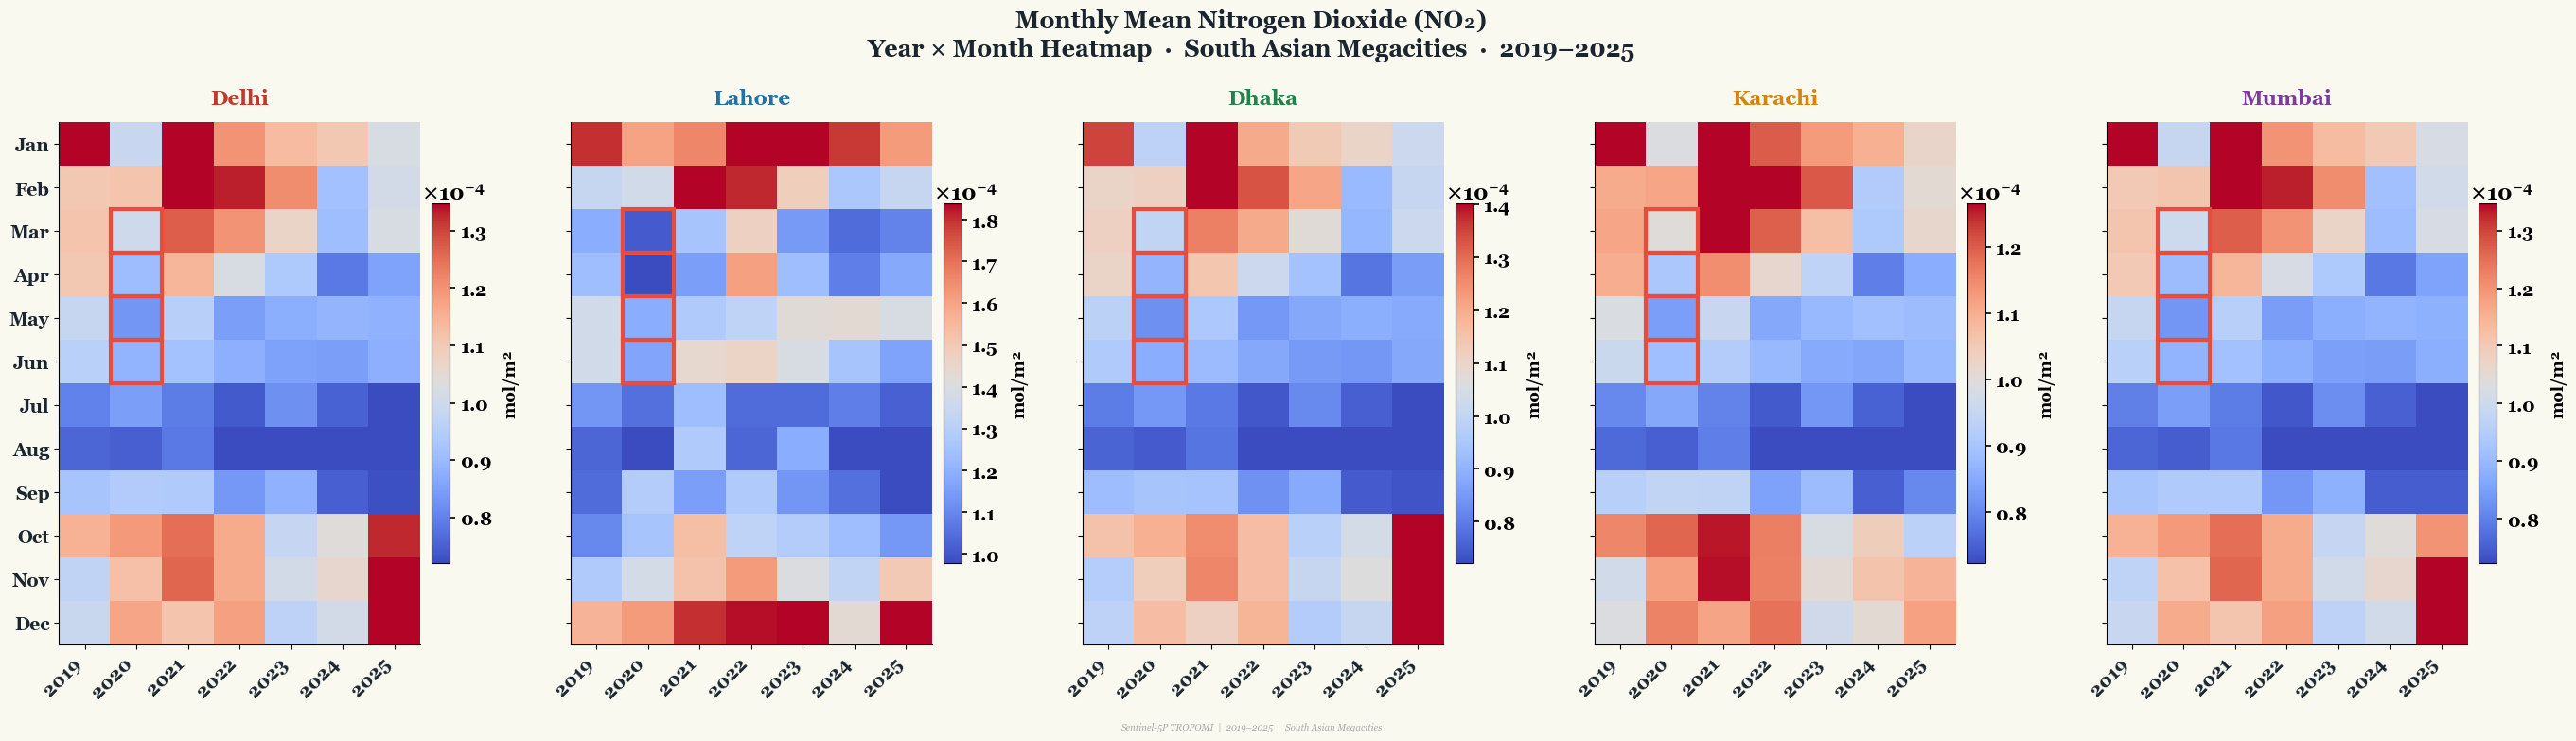

  ✓ Saved → Fig5_Monthly_Heatmap_NO2.png


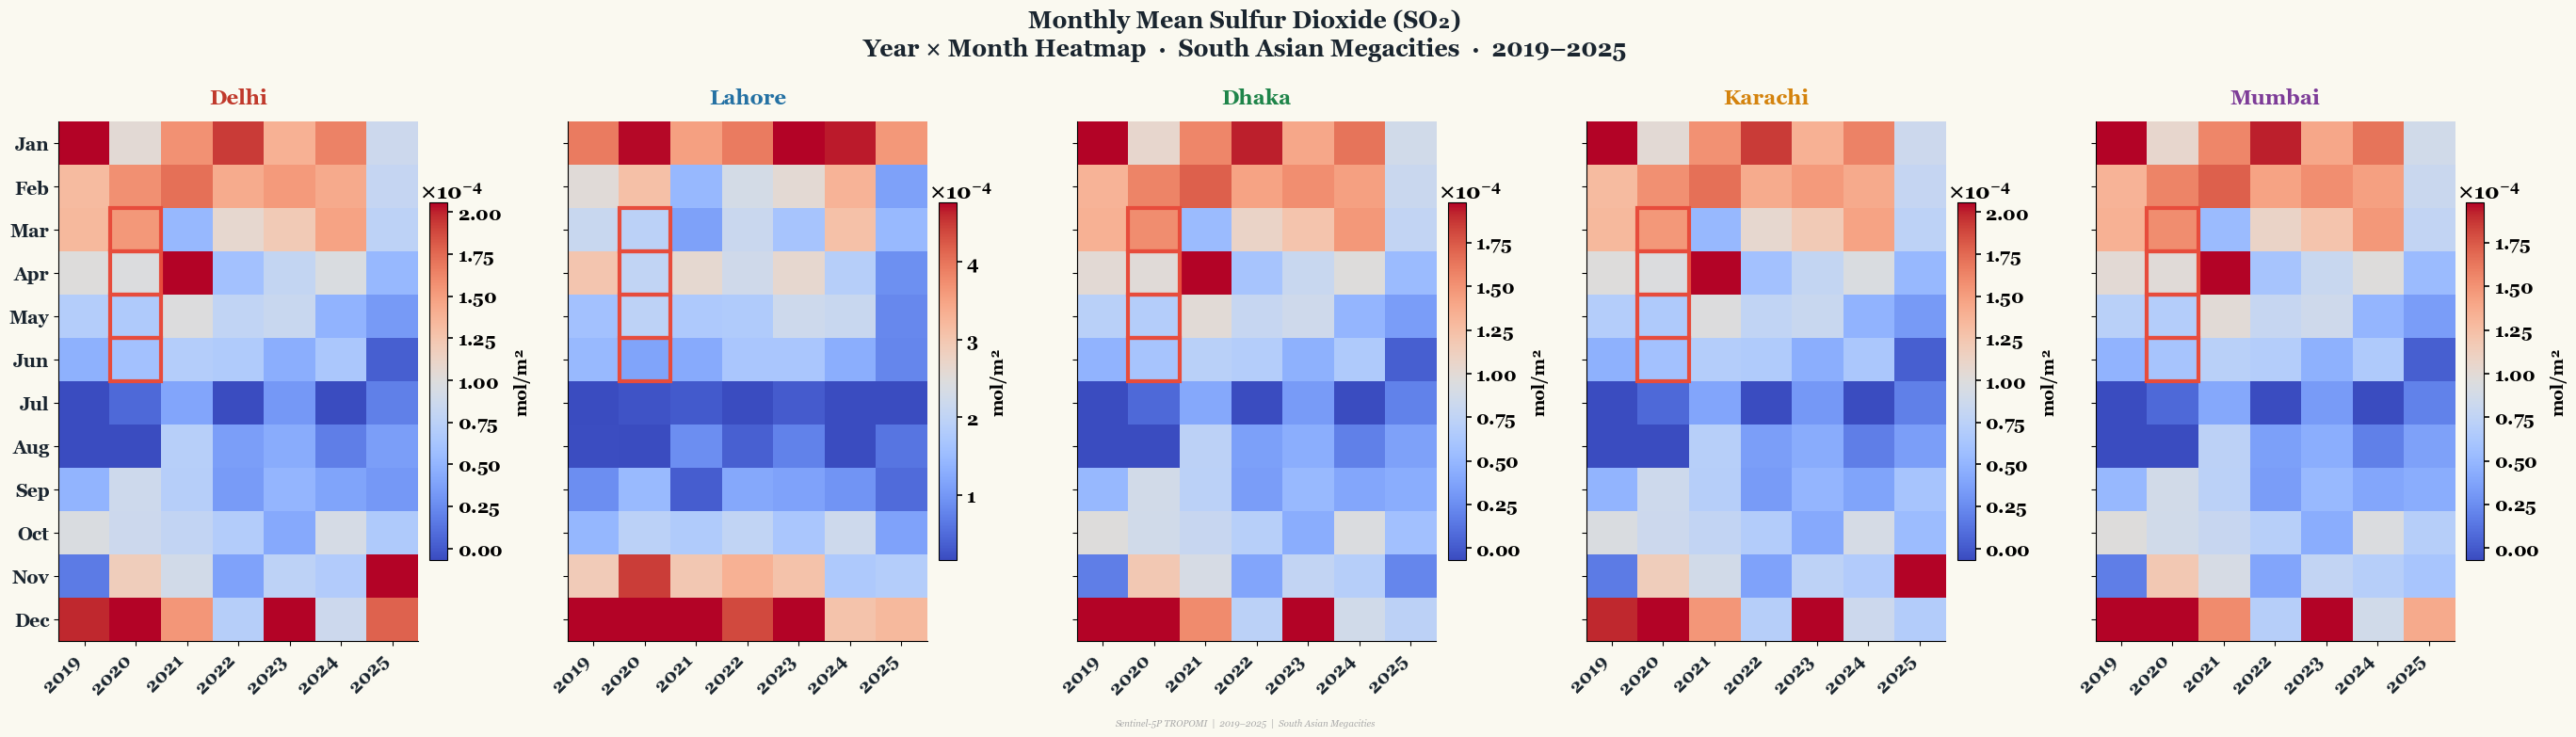

  ✓ Saved → Fig5_Monthly_Heatmap_SO2.png


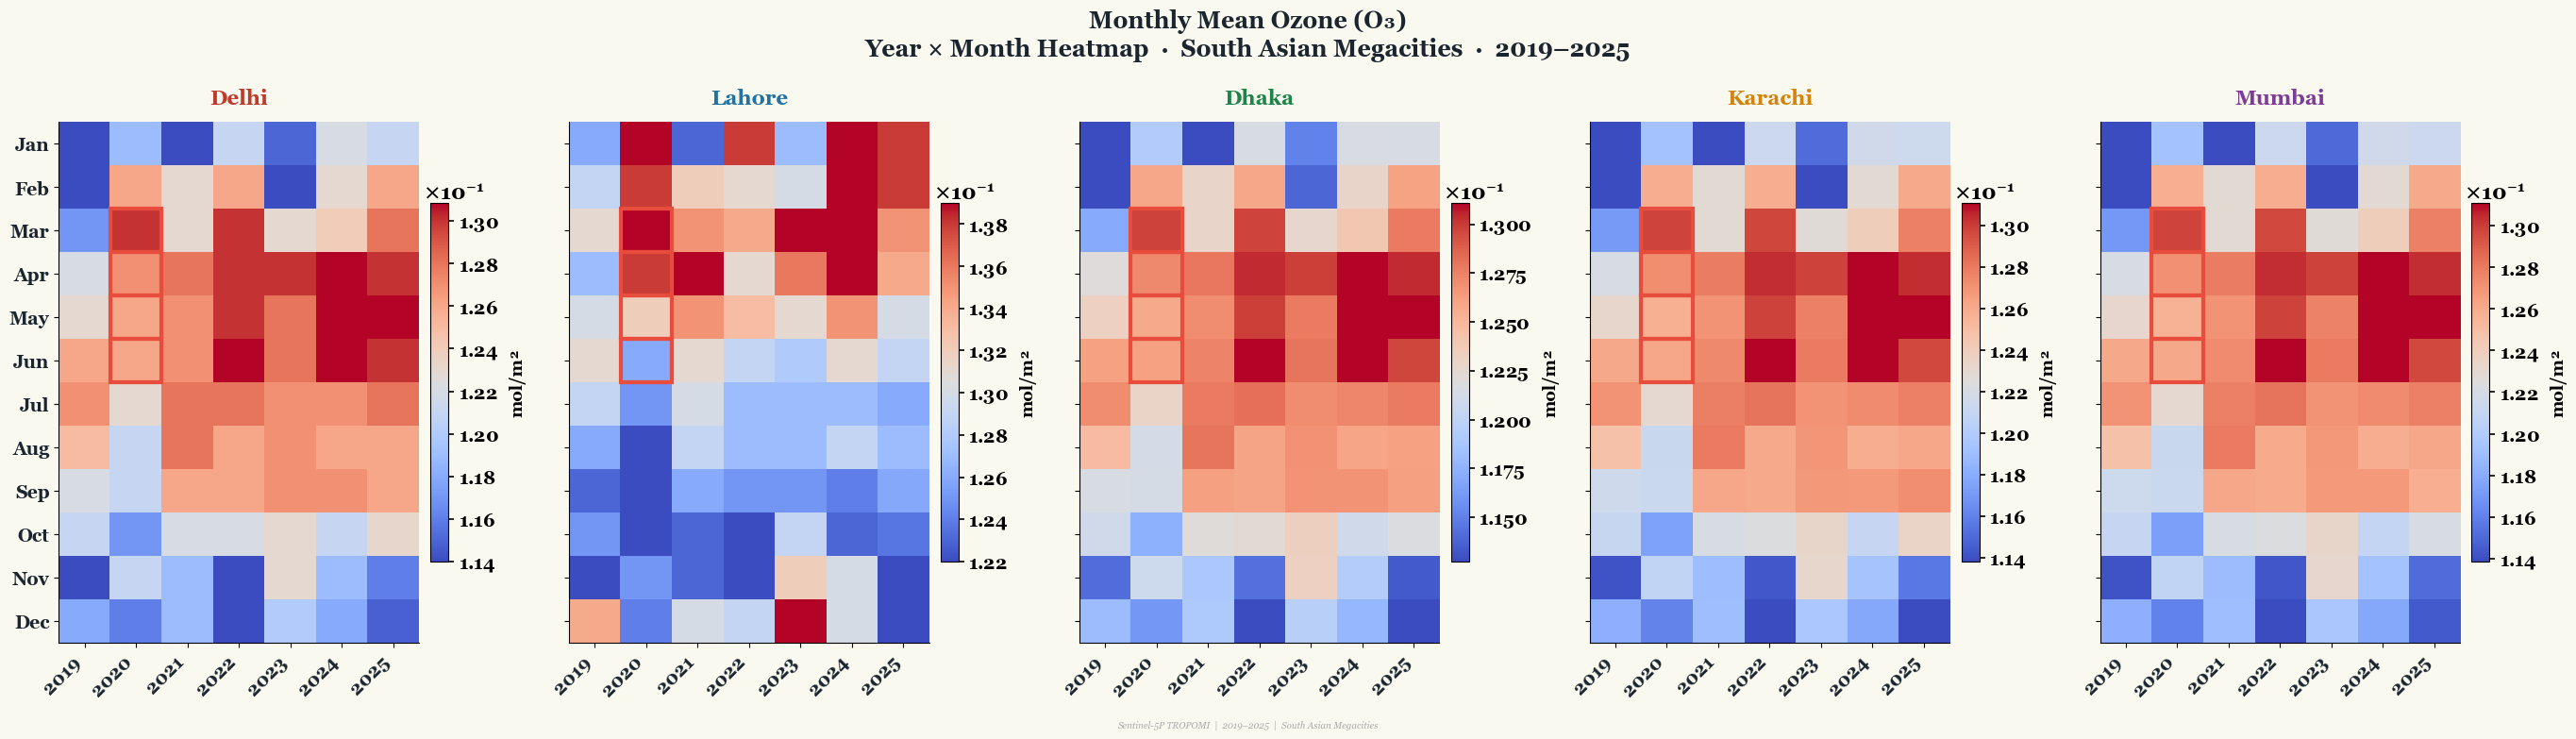

  ✓ Saved → Fig5_Monthly_Heatmap_O3.png


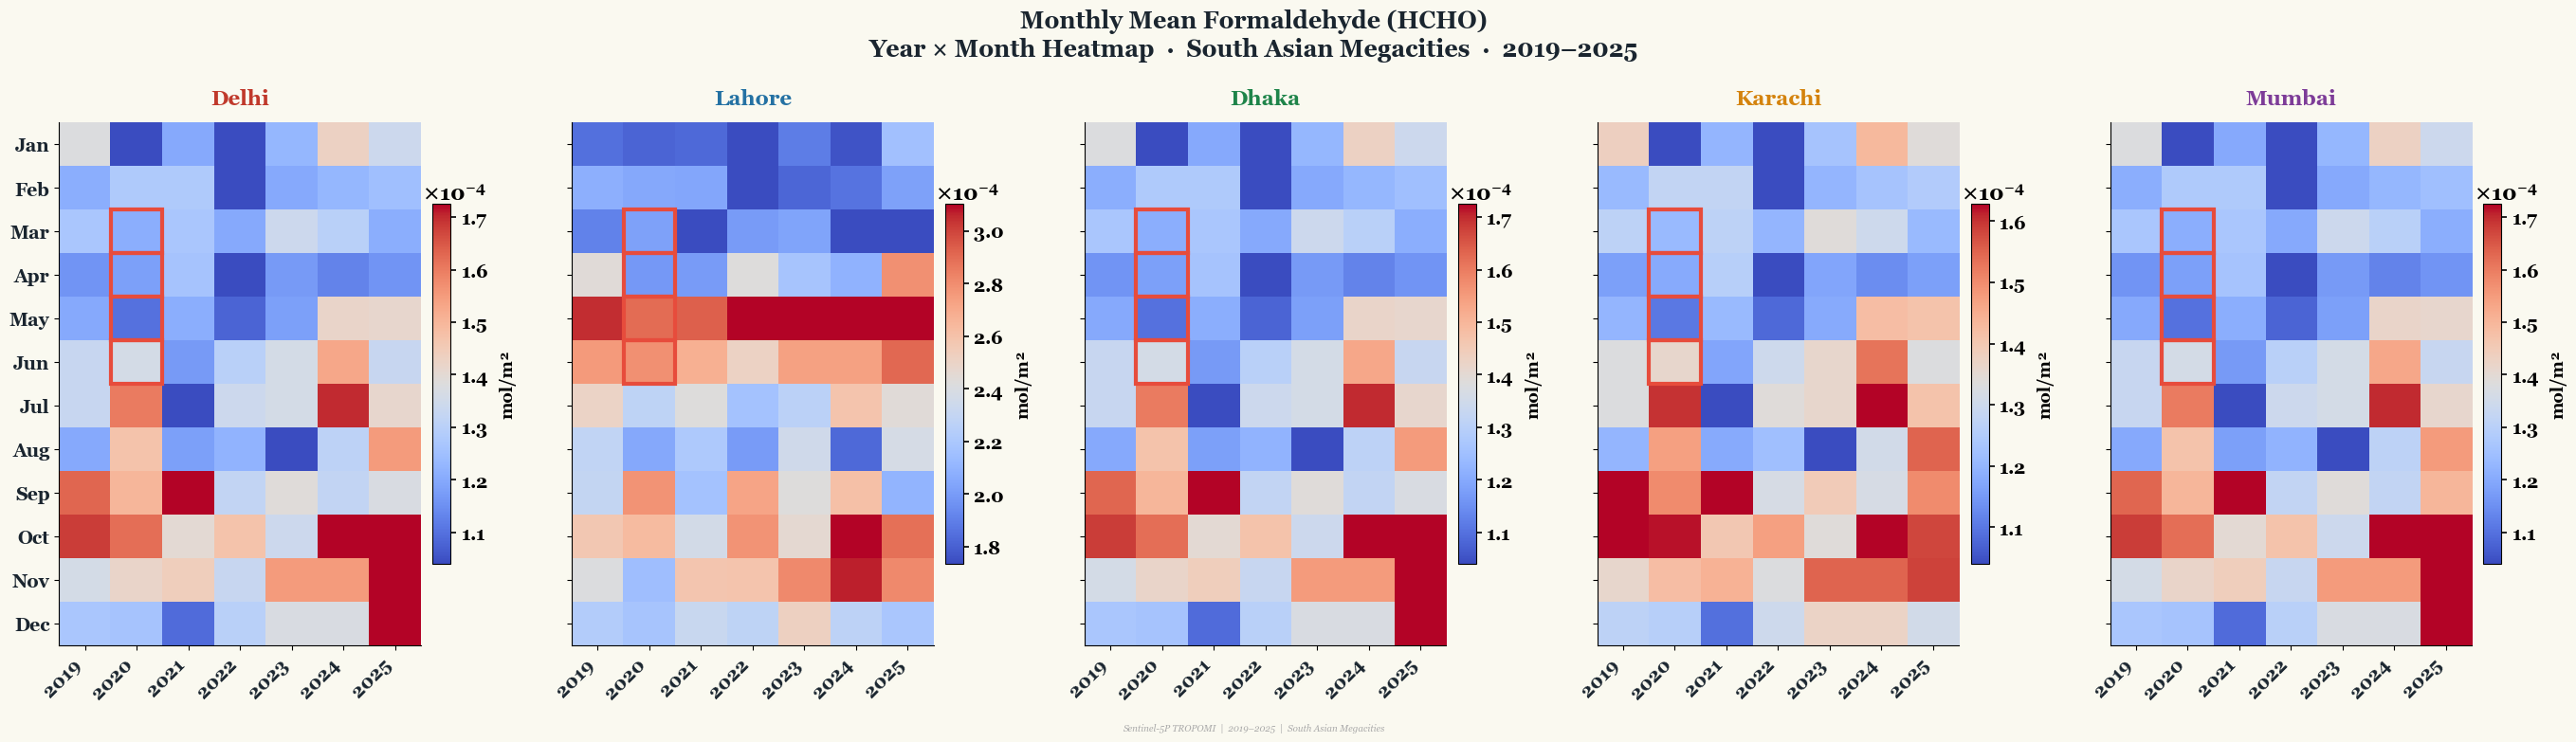

  ✓ Saved → Fig5_Monthly_Heatmap_HCHO.png


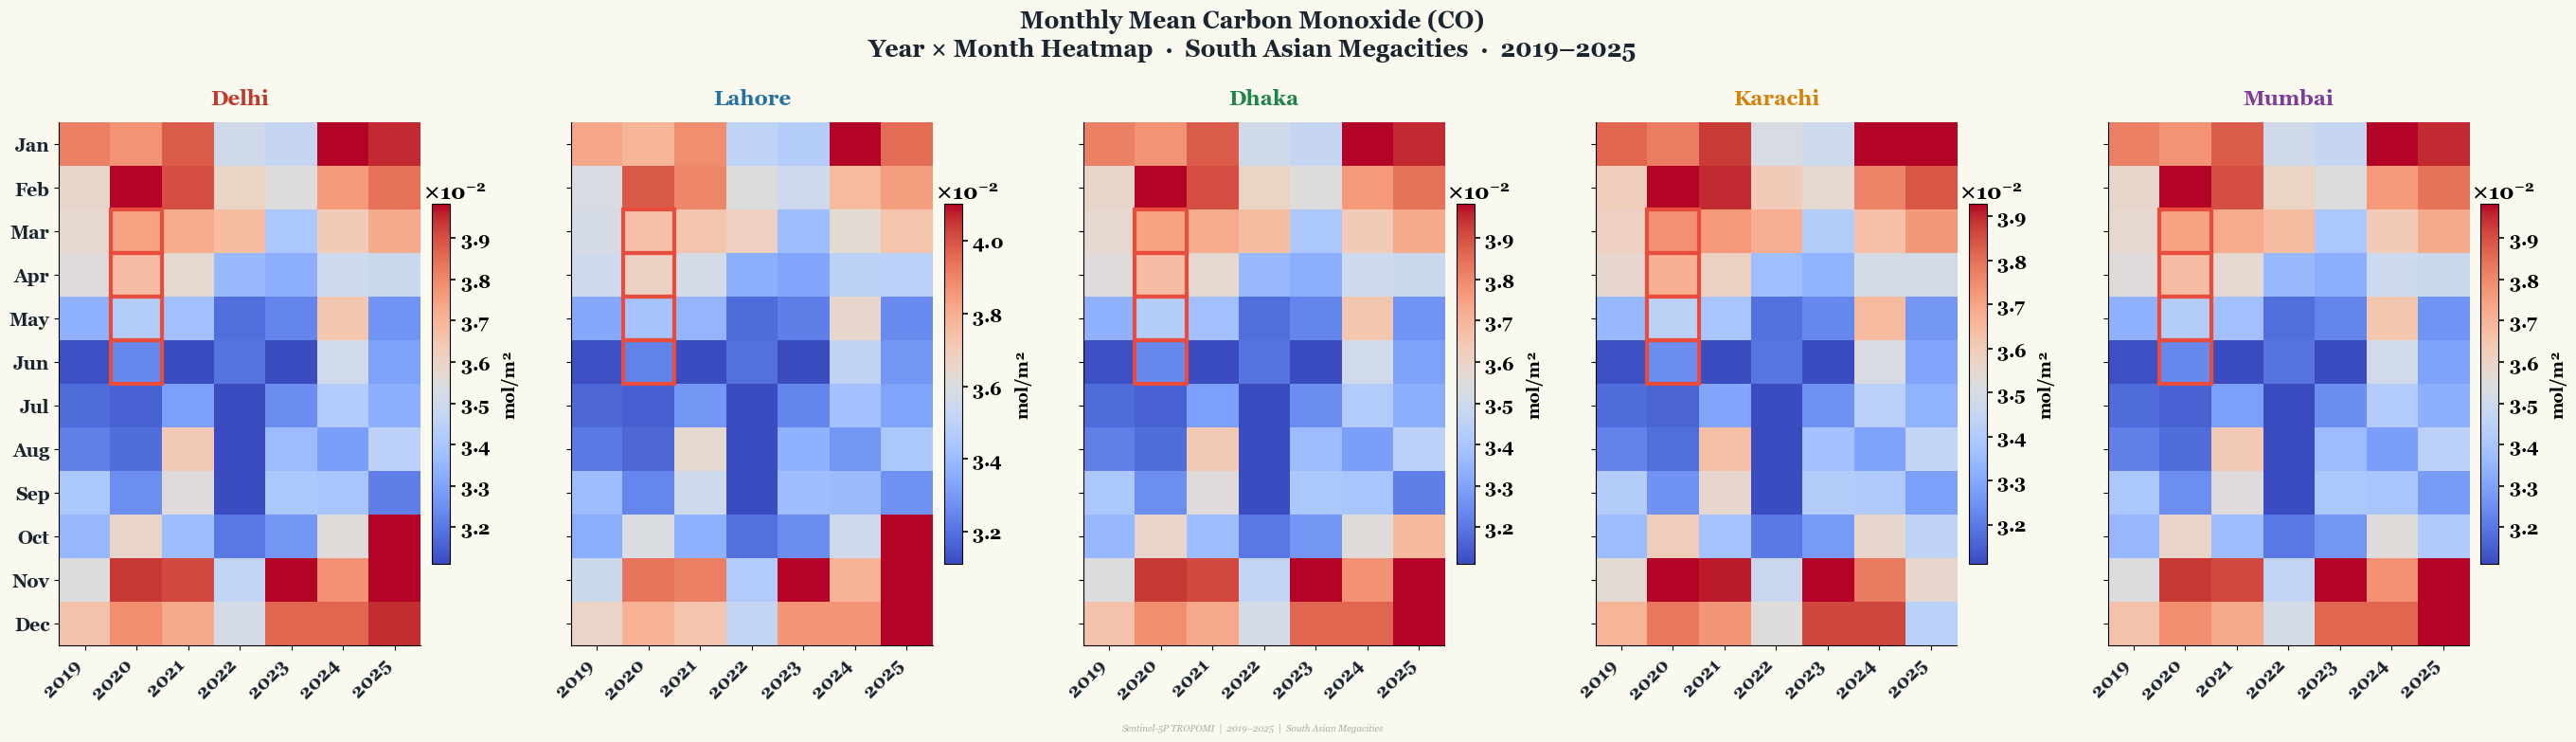

  ✓ Saved → Fig5_Monthly_Heatmap_CO.png
✓ Figure 5 — Monthly Heatmaps (all 5 gases) saved.


In [21]:
# ── CELL — Monthly Heatmaps (Enlarged Colorbar & Balanced Spacing) ─────────────

months_labels = [
    "Jan",
    "Feb",
    "Mar",
    "Apr",
    "May",
    "Jun",
    "Jul",
    "Aug",
    "Sep",
    "Oct",
    "Nov",
    "Dec",
]

for gas in GASES:
    fig, axes = plt.subplots(1, 5, figsize=(28, 8))

    # Figure Background
    fig.patch.set_facecolor("#FAF9F0")

    # ── MAIN FIGURE TITLE ────────────────────────────────────────────────────
    # y=0.96 keeps the main title safely above the city names
    fig.suptitle(
        f"Monthly Mean {GAS_FULL[gas]}\n"
        "Year × Month Heatmap  ·  South Asian Megacities  ·  2019–2025",
        fontsize=18,
        fontweight="bold",
        y=0.96,
        color="#1A252F",
    )

    for ax_i, city in enumerate(CITIES):
        df_city = dfs[city].copy()
        df_city["MonthN"] = df_city["Date"].dt.month
        df_city["YearN"] = df_city["Date"].dt.year
        pivot = df_city.pivot_table(
            index="MonthN", columns="YearN", values=gas, aggfunc="mean"
        )

        ax = axes[ax_i]
        vmin = np.nanpercentile(pivot.values, 5)
        vmax = np.nanpercentile(pivot.values, 95)

        im = ax.imshow(
            pivot.values,
            aspect="auto",
            cmap="coolwarm",
            interpolation="nearest",
            vmin=vmin,
            vmax=vmax,
        )

        # ── Y-AXIS (MONTHS) ───────────────────────────────────────────────────
        ax.set_yticks(range(12))
        ax.set_yticklabels(
            months_labels if ax_i == 0 else [],
            fontsize=14,
            fontweight="bold",
            color="#1A252F",
        )

        # ── X-AXIS (YEARS) ────────────────────────────────────────────────────
        ax.set_xticks(range(len(pivot.columns)))
        ax.set_xticklabels(
            pivot.columns,
            rotation=45,
            ha="right",
            fontsize=14,
            fontweight="bold",
            color="#1A252F",
        )

        # ── CITY TITLE ────────────────────────────────────────────────────────
        ax.set_title(
            city,
            fontsize=16,
            fontweight="bold",
            color=CITY_COLORS[city],
            pad=14,
        )

        # ── COLORBAR (SIDEBAR NUMERIC VALUES) ──────────────────────────────────
        cb = plt.colorbar(im, ax=ax, fraction=0.046, pad=0.03)

        # Scientific notation on colorbar tick values
        cb.formatter.set_powerlimits((0, 0))
        cb.formatter.set_useMathText(True)
        cb.update_ticks()

        # COLORBAR NUMBERS FONT SIZE
        cb.ax.tick_params(labelsize=14, length=4, width=1.2)
        for label in cb.ax.get_yticklabels():
            label.set_fontweight("bold")

        # ── 10 POWER MULTIPLIER (UPDATED: ENLARGED & MOVED UPWARD) ─────────────
        offset_text = cb.ax.yaxis.get_offset_text()
        
        # 1. Enlarged font size for high visibility
        offset_text.set_fontsize(16)
        offset_text.set_fontweight("bold")
        
        # 2. Shifted upward (y=1.09) and aligned with colorbar right side (x=1.15)
        offset_text.set_position((3, 2.6))
        offset_text.set_horizontalalignment("right")

        # Colorbar Label (mol/m²)
        cb.set_label("mol/m²", fontsize=13, fontweight="bold", labelpad=8)

        # ── COVID RED BOXES (Mar–Jun 2020) ────────────────────────────────────
        for y_i, yr in enumerate(pivot.columns):
            if yr == 2020:
                for m_i in [2, 3, 4, 5]:  # 0-indexed rows for Mar-Jun
                    rect = plt.Rectangle(
                        (y_i - 0.5, m_i - 0.5),
                        1,
                        1,
                        fill=False,
                        edgecolor="#E74C3C",
                        linewidth=3,
                    )
                    ax.add_patch(rect)

    # ── SPACING CONTROL (OPTIMIZED PREVENTING ALL OVERLAPS) ───────────────────
    fig.subplots_adjust(
        left=0.05,
        right=0.97,
        top=0.81,   # Leaves extra room at the top so title & raised 10^x never touch
        bottom=0.12,
        wspace=0.31, # Extra room between subplots for the enlarged exponents
    )

    add_watermark(fig)
    save_fig(fig, out("temporal", f"Fig5_Monthly_Heatmap_{gas}.png"))

print("✓ Figure 5 — Monthly Heatmaps (all 5 gases) saved.")

In [22]:
print("Running Mann-Kendall tests (25 combinations)…\n")
mk_rows = []

for city in CITIES:
    for gas in GASES:
        series = dfs[city].set_index("Date")[gas].dropna()
        try:
            res = mk.original_test(series.values)
            sig = "***" if res.p<0.001 else "**" if res.p<0.01 else "*" if res.p<0.05 else "ns"
            mk_rows.append({
                "City"          : city,
                "Gas"           : gas,
                "Z-statistic"   : round(res.z, 4),
                "p-value"       : round(res.p, 6),
                "Trend"         : res.trend,
                "Sen Slope (Q)" : res.slope,
                "Intercept"     : res.intercept,
                "Significance"  : sig,
            })
            print(f"  {city:8s} | {gas:4s} | {res.trend:12s} | Z={res.z:6.3f} | "
                  f"Q={res.slope:.3e} | p={res.p:.4f} {sig}")
        except Exception as e:
            print(f"  ERROR {city} {gas}: {e}")

mk_df = pd.DataFrame(mk_rows)
mk_df.to_csv(out("tables","Table3_MannKendall_SensSlope.csv"), index=False)
print("\n✓ Mann-Kendall Table saved.")

Running Mann-Kendall tests (25 combinations)…

  Delhi    | NO2  | no trend     | Z=-1.781 | Q=-1.696e-07 | p=0.0749 ns
  Delhi    | SO2  | no trend     | Z=-1.646 | Q=-4.186e-07 | p=0.0998 ns
  Delhi    | O3   | increasing   | Z= 2.254 | Q=4.839e-05 | p=0.0242 *
  Delhi    | HCHO | increasing   | Z= 2.466 | Q=2.000e-07 | p=0.0137 *
  Delhi    | CO   | no trend     | Z= 0.892 | Q=1.316e-05 | p=0.3722 ns
  Lahore   | NO2  | no trend     | Z=-0.448 | Q=-4.959e-08 | p=0.6539 ns
  Lahore   | SO2  | no trend     | Z=-1.271 | Q=-7.958e-07 | p=0.2037 ns
  Lahore   | O3   | no trend     | Z= 0.256 | Q=0.000e+00 | p=0.7983 ns
  Lahore   | HCHO | no trend     | Z= 1.406 | Q=2.711e-07 | p=0.1596 ns
  Lahore   | CO   | no trend     | Z= 0.985 | Q=1.484e-05 | p=0.3246 ns
  Dhaka    | NO2  | no trend     | Z=-1.750 | Q=-1.671e-07 | p=0.0801 ns
  Dhaka    | SO2  | decreasing   | Z=-2.434 | Q=-6.000e-07 | p=0.0149 *
  Dhaka    | O3   | increasing   | Z= 2.144 | Q=4.894e-05 | p=0.0320 *
  Dhaka    | HC

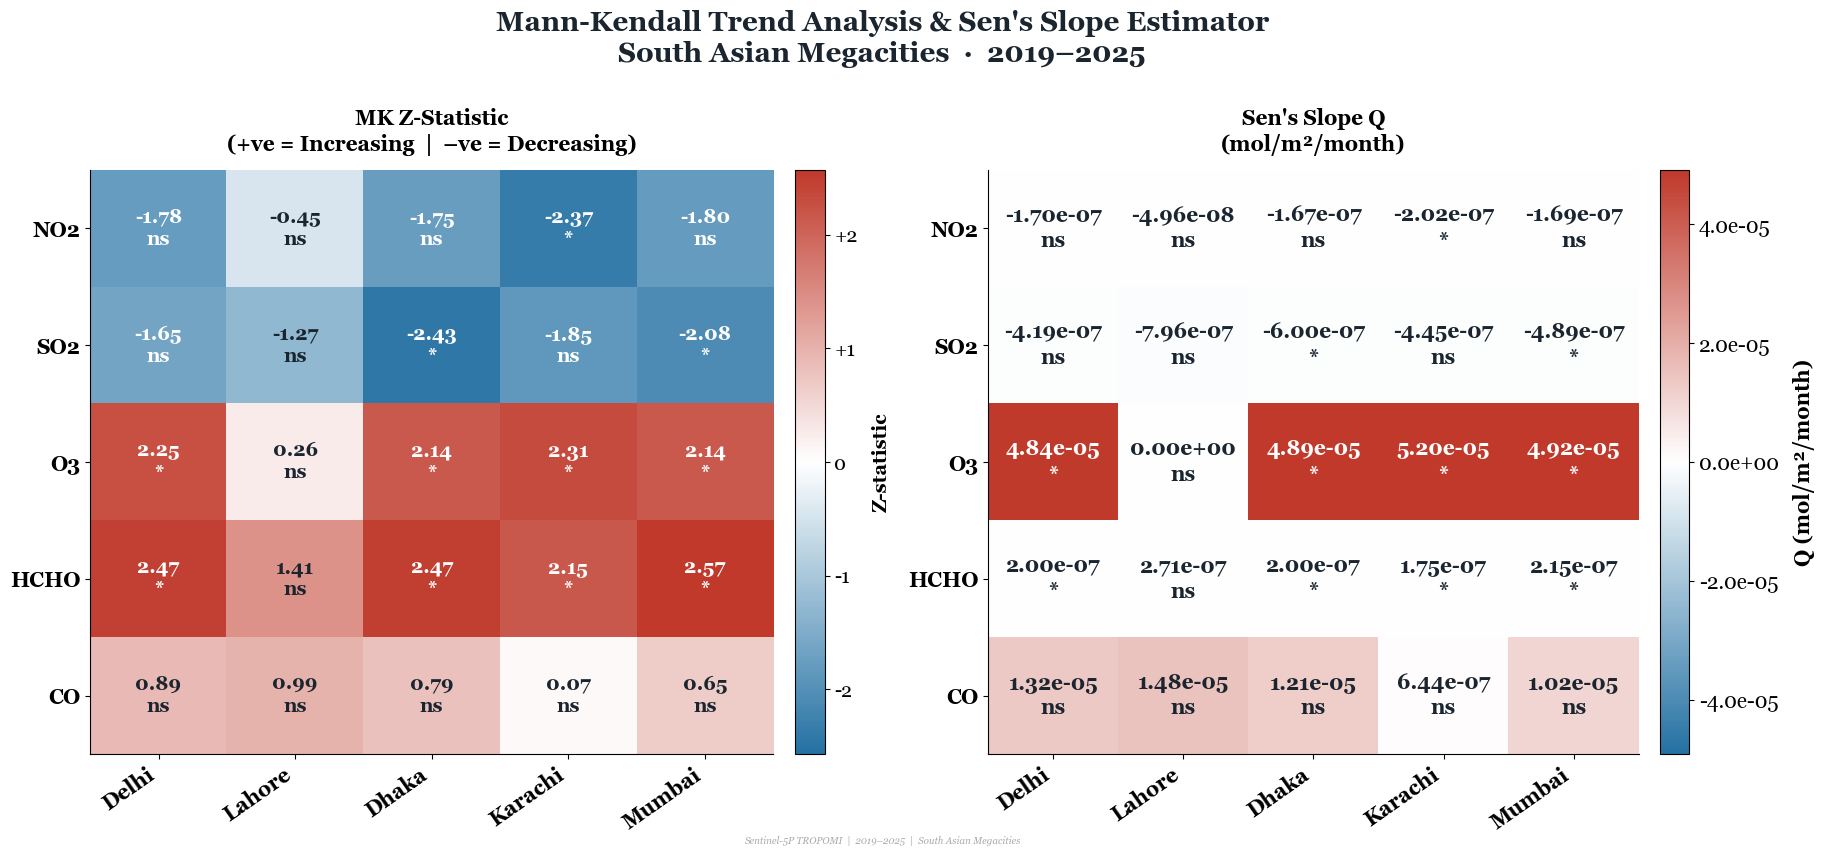

  ✓ Saved → Fig7_MannKendall_Trend_Heatmap.png
✓ Figure 7 — MK Trend Heatmap saved with tight spacing and enlarged fonts.


In [25]:
# ── CELL 13 — MK Trend Heatmap (FIXED: Reduced Spacing & Larger Fonts) ──────

# 1. REDUCED DISTANCE BETWEEN PLOTS: wspace reduced to 0.10, tighter figure width
fig, axes = plt.subplots(
    1,
    2,
    figsize=(18, 8),
    gridspec_kw={"width_ratios": [1.05, 1], "wspace": 0.22},
)

# 2. MAIN TITLE FONT SIZE & POSITION
fig.suptitle(
    "Mann-Kendall Trend Analysis & Sen's Slope Estimator\n"
    "South Asian Megacities  ·  2019–2025",
    fontsize=20,
    fontweight="bold",
    y=1.05,
    color="#1A252F",
)

# ═══════════════════════════════════════════════════════════════════
# LEFT PANEL — MK Z-Statistic
# ═══════════════════════════════════════════════════════════════════
z_pivot = mk_df.pivot(index="Gas", columns="City", values="Z-statistic")
z_pivot = z_pivot.reindex(index=GASES, columns=CITIES)
zmax = max(abs(z_pivot.values.flatten()))

im1 = axes[0].imshow(
    z_pivot.values,
    cmap=DIVERGE_CMAP,
    norm=TwoSlopeNorm(vcenter=0, vmin=-zmax, vmax=zmax),
    aspect="auto",
)

axes[0].set_xticks(range(5))
axes[0].set_yticks(range(5))

# 3. AXIS TEXT SIZE (Cities on X-axis)
axes[0].set_xticklabels(
    CITIES,
    rotation=35,
    ha="right",
    fontsize=15,  # ◄── INCREASED CITY NAMES
    fontweight="bold",
)

# 3. AXIS TEXT SIZE (Gases on Y-axis)
axes[0].set_yticklabels(
    GASES,
    fontsize=15,  # ◄── INCREASED GAS NAMES
    fontweight="bold",
)

axes[0].set_title(
    "MK Z-Statistic\n(+ve = Increasing  |  –ve = Decreasing)",
    fontsize=15,
    fontweight="bold",
    pad=14,
)

# 4. TEXT INSIDE HEATMAP BOXES
for i, gas in enumerate(GASES):
    for j, city in enumerate(CITIES):
        row_ = mk_df[(mk_df["City"] == city) & (mk_df["Gas"] == gas)]
        if len(row_):
            z_ = row_["Z-statistic"].values[0]
            s_ = row_["Significance"].values[0]
            axes[0].text(
                j,
                i,
                f"{z_:.2f}\n{s_}",
                ha="center",
                va="center",
                fontsize=14,  # ◄── INCREASED BOX VALUES (was 12)
                fontweight="bold",
                color="white" if abs(z_) > 1.5 else "#1A252F",
            )

# Colorbar Left
cb1 = plt.colorbar(im1, ax=axes[0], fraction=0.046, pad=0.03)
cb1.set_label("Z-statistic", fontsize=14, fontweight="bold", labelpad=10)
cb1.set_ticks([-2, -1, 0, 1, 2])
cb1.set_ticklabels(["-2", "-1", "0", "+1", "+2"], fontsize=14)

# ═══════════════════════════════════════════════════════════════════
# RIGHT PANEL — Sen's Slope Q
# ═══════════════════════════════════════════════════════════════════
q_pivot = mk_df.pivot(index="Gas", columns="City", values="Sen Slope (Q)")
q_pivot = q_pivot.reindex(index=GASES, columns=CITIES)
qmax = np.nanpercentile(np.abs(q_pivot.values), 95)

im2 = axes[1].imshow(
    q_pivot.values,
    cmap=DIVERGE_CMAP,
    norm=TwoSlopeNorm(vcenter=0, vmin=-qmax, vmax=qmax),
    aspect="auto",
)

axes[1].set_xticks(range(5))
axes[1].set_yticks(range(5))

# 3. AXIS TEXT SIZE
axes[1].set_xticklabels(
    CITIES, rotation=35, ha="right", fontsize=15, fontweight="bold"
)

axes[1].set_yticklabels(GASES, fontsize=15, fontweight="bold")

axes[1].set_title(
    "Sen's Slope Q\n(mol/m²/month)", fontsize=15, fontweight="bold", pad=14
)

# 4. TEXT INSIDE HEATMAP BOXES
for i, gas in enumerate(GASES):
    for j, city in enumerate(CITIES):
        row_ = mk_df[(mk_df["City"] == city) & (mk_df["Gas"] == gas)]
        if len(row_):
            q_ = row_["Sen Slope (Q)"].values[0]
            s_ = row_["Significance"].values[0]
            axes[1].text(
                j,
                i,
                f"{q_:.2e}\n{s_}",
                ha="center",
                va="center",
                fontsize=15,  # ◄── INCREASED BOX VALUES (was 12)
                fontweight="bold",
                color="white" if abs(q_) > qmax * 0.55 else "#1A252F",
            )

# Colorbar Right
cb2 = plt.colorbar(im2, ax=axes[1], fraction=0.046, pad=0.03)
cb2.set_label("Q (mol/m²/month)", fontsize=15, fontweight="bold", labelpad=10)

from matplotlib.ticker import FuncFormatter

cb2.ax.yaxis.set_major_formatter(FuncFormatter(lambda x, _: f"{x:.1e}"))
cb2.ax.tick_params(labelsize=15)

# ── SPACING CONTROL ───────────────────────────────────────────────────────────
plt.tight_layout()
fig.subplots_adjust(top=0.85, bottom=0.12, left=0.06, right=0.95)

add_watermark(fig)
save_fig(fig, out("trend", "Fig7_MannKendall_Trend_Heatmap.png"))
print("✓ Figure 7 — MK Trend Heatmap saved with tight spacing and enlarged fonts.")

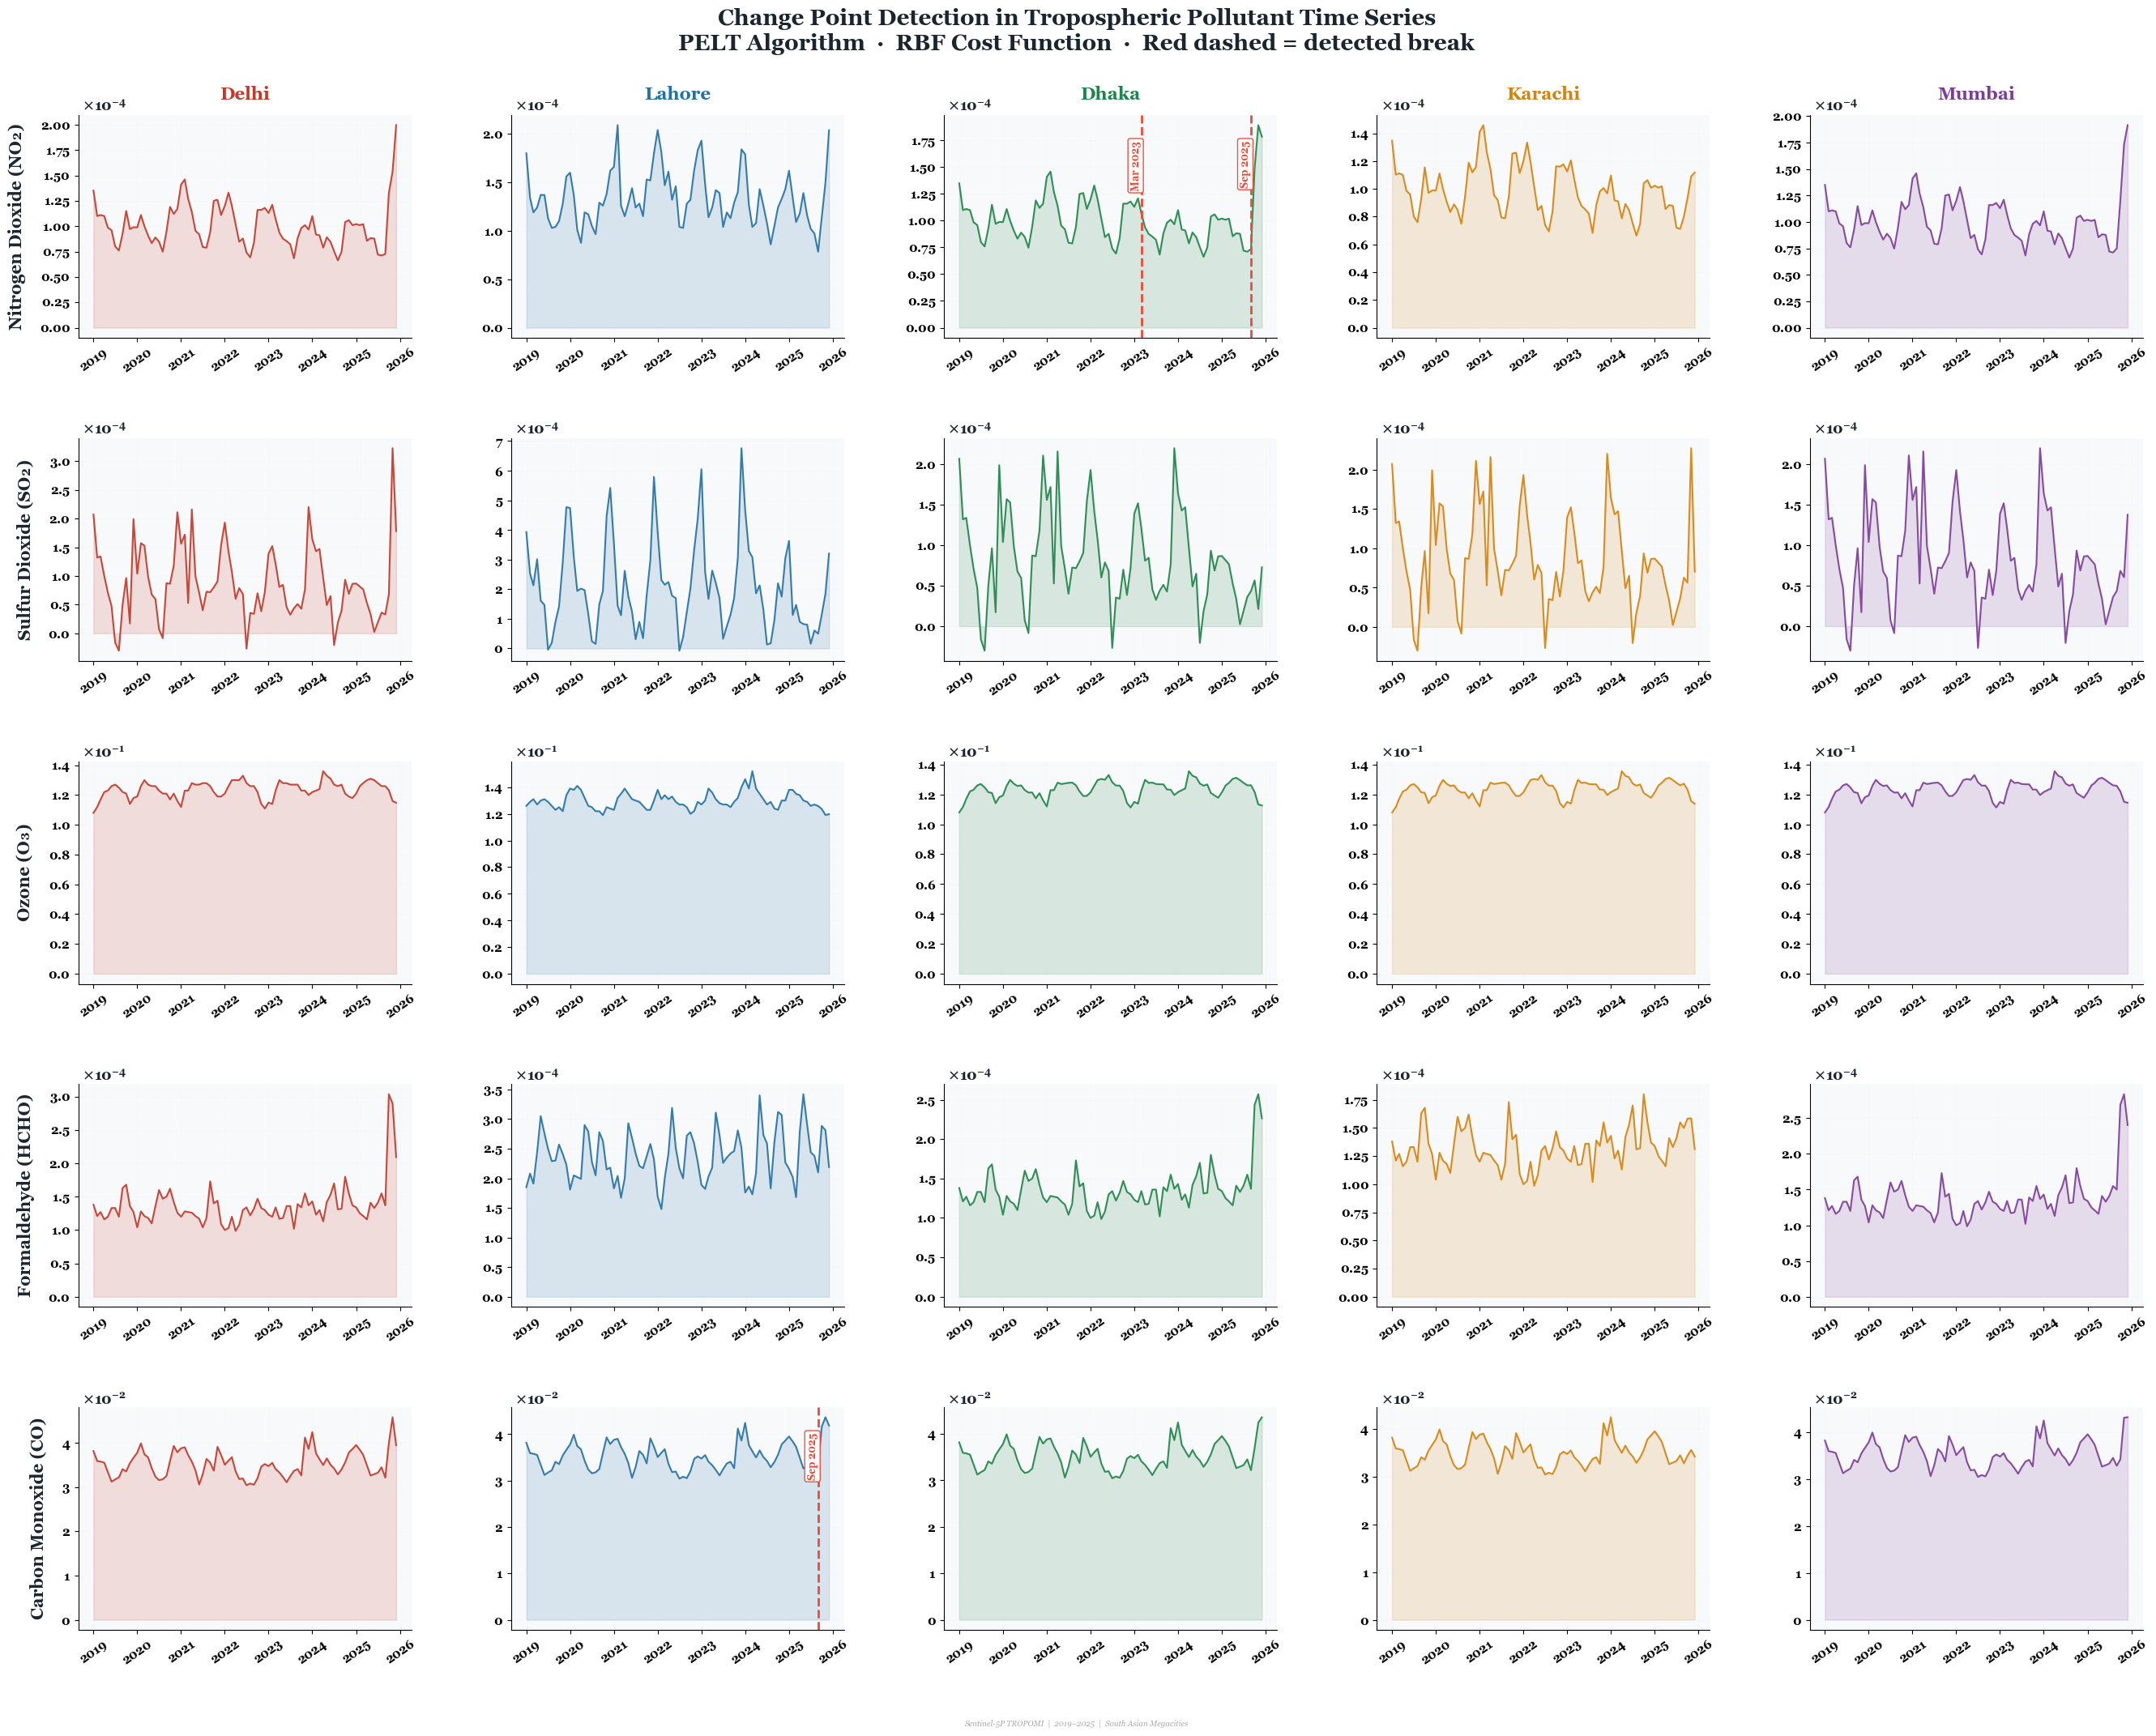

  ✓ Saved → Fig9_Change_Point_Detection.png
✓ Figure 9 — Change Point Detection saved with active PELT break lines.


In [29]:
# ── CELL — Change Point Detection Grid (Fig 9 - FIXED: PELT Lines Active) ─────

import matplotlib.dates as mdates
import pandas as pd
import ruptures as rpt  # ◄── Required for PELT algorithm

# 1. EXPANDED FIGURE SIZE FOR MAXIMUM CLARITY
fig, axes = plt.subplots(5, 5, figsize=(28, 22), sharex=False)

# 2. MAIN TITLE ADJUSTMENT
fig.suptitle(
    "Change Point Detection in Tropospheric Pollutant Time Series\n"
    "PELT Algorithm  ·  RBF Cost Function  ·  Red dashed = detected break",
    fontsize=20,
    fontweight="bold",
    y=0.97,
    color="#1A252F",
)

for row_i, gas in enumerate(GASES):
    for col_i, city in enumerate(CITIES):
        ax = axes[row_i][col_i]

        # Pull data for specific city and gas
        series = dfs[city].set_index("Date")[gas].dropna()
        color = CITY_COLORS[city]

        # Plot time series line & fill
        ax.plot(
            series.index, series.values, color=color, linewidth=1.5, alpha=0.9
        )
        ax.fill_between(series.index, series.values, alpha=0.15, color=color)

        # ── 3. RUN PELT ALGORITHM & DRAW RED DASHED LINES ─────────────────────
        if len(series) > 12:
            try:
                # Prepare signal array for PELT
                signal = series.values.reshape(-1, 1)

                # Run PELT with RBF cost model (pen = penalty parameter)
                algo = rpt.Pelt(model="rbf", min_size=3, jump=1).fit(signal)
                # Change pen value (e.g., 3, 5, or 10) to control sensitivity
                result = algo.predict(pen=3)

                # Extract change point dates (excluding the last endpoint index)
                bkps_indices = [bk - 1 for bk in result[:-1] if bk < len(series)]
                bkps_dates = series.index[bkps_indices]

                # Draw red dashed line and date box for each detected break
                for bk in bkps_dates:
                    ax.axvline(
                        x=bk, color="#E74C3C", linestyle="--", linewidth=2.0, zorder=5
                    )
                    
                    # Annotate Date Label on top of the dashed line
                    ax.text(
                        bk,
                        ax.get_ylim()[1] * 0.88,
                        bk.strftime("%b %Y"),
                        rotation=90,
                        fontsize=9,
                        fontweight="bold",
                        color="#E74C3C",
                        ha="right",
                        va="top",
                        bbox=dict(
                            boxstyle="round,pad=0.2",
                            fc="white",
                            ec="#E74C3C",
                            lw=1,
                            alpha=0.95,
                        ),
                        zorder=6,
                    )
            except Exception as e:
                pass

        # ── 4. SCIENTIFIC NOTATION & 10^X MULTIPLIER CONTROL ──────────────────
        sci_fmt(ax, axis="y")  # Custom scientific formatter

        offset_text = ax.yaxis.get_offset_text()
        offset_text.set_fontsize(13)
        offset_text.set_fontweight("bold")
        offset_text.set_color("#1A252F")
        offset_text.set_position((0.01, 1.05))

        # ── 5. TICK LABELS (X-AXIS YEARS & Y-AXIS NUMBERS) ─────────────────────
        ax.tick_params(axis="y", labelsize=11)
        for label in ax.get_yticklabels():
            label.set_fontweight("bold")

        ax.xaxis.set_major_locator(mdates.YearLocator())
        ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
        ax.tick_params(axis="x", labelsize=11, rotation=35)
        for label in ax.get_xticklabels():
            label.set_fontweight("bold")

        # ── 6. CITY NAMES (TOP ROW ONLY) ──────────────────────────────────────
        if row_i == 0:
            ax.set_title(
                city,
                fontsize=16,
                fontweight="bold",
                color=CITY_COLORS[city],
                pad=14,
            )

        # ── 7. GAS NAMES (LEFT COLUMN ONLY - LARGE & READABLE) ────────────────
        if col_i == 0:
            ax.set_ylabel(
                GAS_FULL[gas],
                fontsize=15,
                fontweight="bold",
                color="#1A252F",
                labelpad=12,
            )

        ax.grid(alpha=0.3, linestyle=":")
        ax.set_facecolor("#F8F9FA")

# ── 8. SPACING CONTROL (PREVENTS ALL OVERLAPS) ────────────────────────────────
fig.subplots_adjust(
    left=0.06,
    right=0.97,
    top=0.91,
    bottom=0.06,
    wspace=0.30,
    hspace=0.45,
)

add_watermark(fig)
save_fig(fig, out("changepoint", "Fig9_Change_Point_Detection.png"))
print(
    "✓ Figure 9 — Change Point Detection saved with active PELT break lines."
)

In [32]:
covid_rows = []
for city in CITIES:
    for gas in GASES:
        series    = dfs[city].set_index("Date")[gas]
        b_vals    = series["2019-03-01":"2019-06-30"].dropna()
        l_vals    = series["2020-03-01":"2020-06-30"].dropna()
        baseline  = b_vals.mean()
        lockdown  = l_vals.mean()
        pct_chg   = (lockdown - baseline) / abs(baseline) * 100 if baseline != 0 else np.nan

        cohens_d  = np.nan
        ttest_p   = np.nan
        if len(b_vals) > 1 and len(l_vals) > 1:
            pooled_sd = np.sqrt((b_vals.std()**2 + l_vals.std()**2) / 2)
            if pooled_sd > 0:
                cohens_d = (l_vals.mean() - b_vals.mean()) / pooled_sd
            _, ttest_p = stats.ttest_ind(b_vals, l_vals)

        # Recovery: first month post-lockdown within ±10% of baseline
        post     = series["2020-07-01":]
        recovery = None
        for dt, val in post.items():
            if abs(val - baseline) / (abs(baseline)+1e-30) <= 0.10:
                recovery = dt
                break

        sig = "***" if ttest_p<0.001 else "**" if ttest_p<0.01 else "*" if ttest_p<0.05 else "ns"
        covid_rows.append({
            "City"               : city,
            "Gas"                : gas,
            "Baseline (2019)"    : round(baseline, 10),
            "Lockdown (2020)"    : round(lockdown, 10),
            "% Change"           : round(pct_chg, 2),
            "Cohen's d"          : round(cohens_d, 3) if not np.isnan(cohens_d) else np.nan,
            "p-value"            : round(ttest_p, 5)  if not np.isnan(ttest_p)  else np.nan,
            "Significance"       : sig,
            "Recovery Month"     : str(recovery)[:7] if recovery else "Not recovered",
        })

covid_df = pd.DataFrame(covid_rows)
covid_df.to_csv(out("tables","Table5_COVID_Lockdown_Impact.csv"), index=False)
print("✓ COVID analysis table saved.\n")
print(covid_df[["City","Gas","% Change","Cohen's d","Significance","Recovery Month"]]
      .to_string(index=False))


✓ COVID analysis table saved.

   City  Gas  % Change  Cohen's d Significance Recovery Month
  Delhi  NO2    -12.68     -1.797            *        2020-09
  Delhi  SO2      7.58      0.167           ns        2020-09
  Delhi   O3      4.30      1.771            *        2020-07
  Delhi HCHO     -2.22     -0.294           ns        2020-12
  Delhi   CO      3.62      0.552           ns        2020-07
 Lahore  NO2    -17.89     -1.878            *        2020-09
 Lahore  SO2    -13.75     -0.494           ns        2020-10
 Lahore   O3      3.47      0.920           ns        2020-07
 Lahore HCHO     -4.53     -0.236           ns        2020-09
 Lahore   CO      3.62      0.552           ns        2020-07
  Dhaka  NO2    -12.68     -1.797            *        2020-09
  Dhaka  SO2      7.58      0.167           ns        2020-09
  Dhaka   O3      4.16      1.722           ns        2020-07
  Dhaka HCHO     -2.22     -0.294           ns        2020-12
  Dhaka   CO      3.62      0.552      

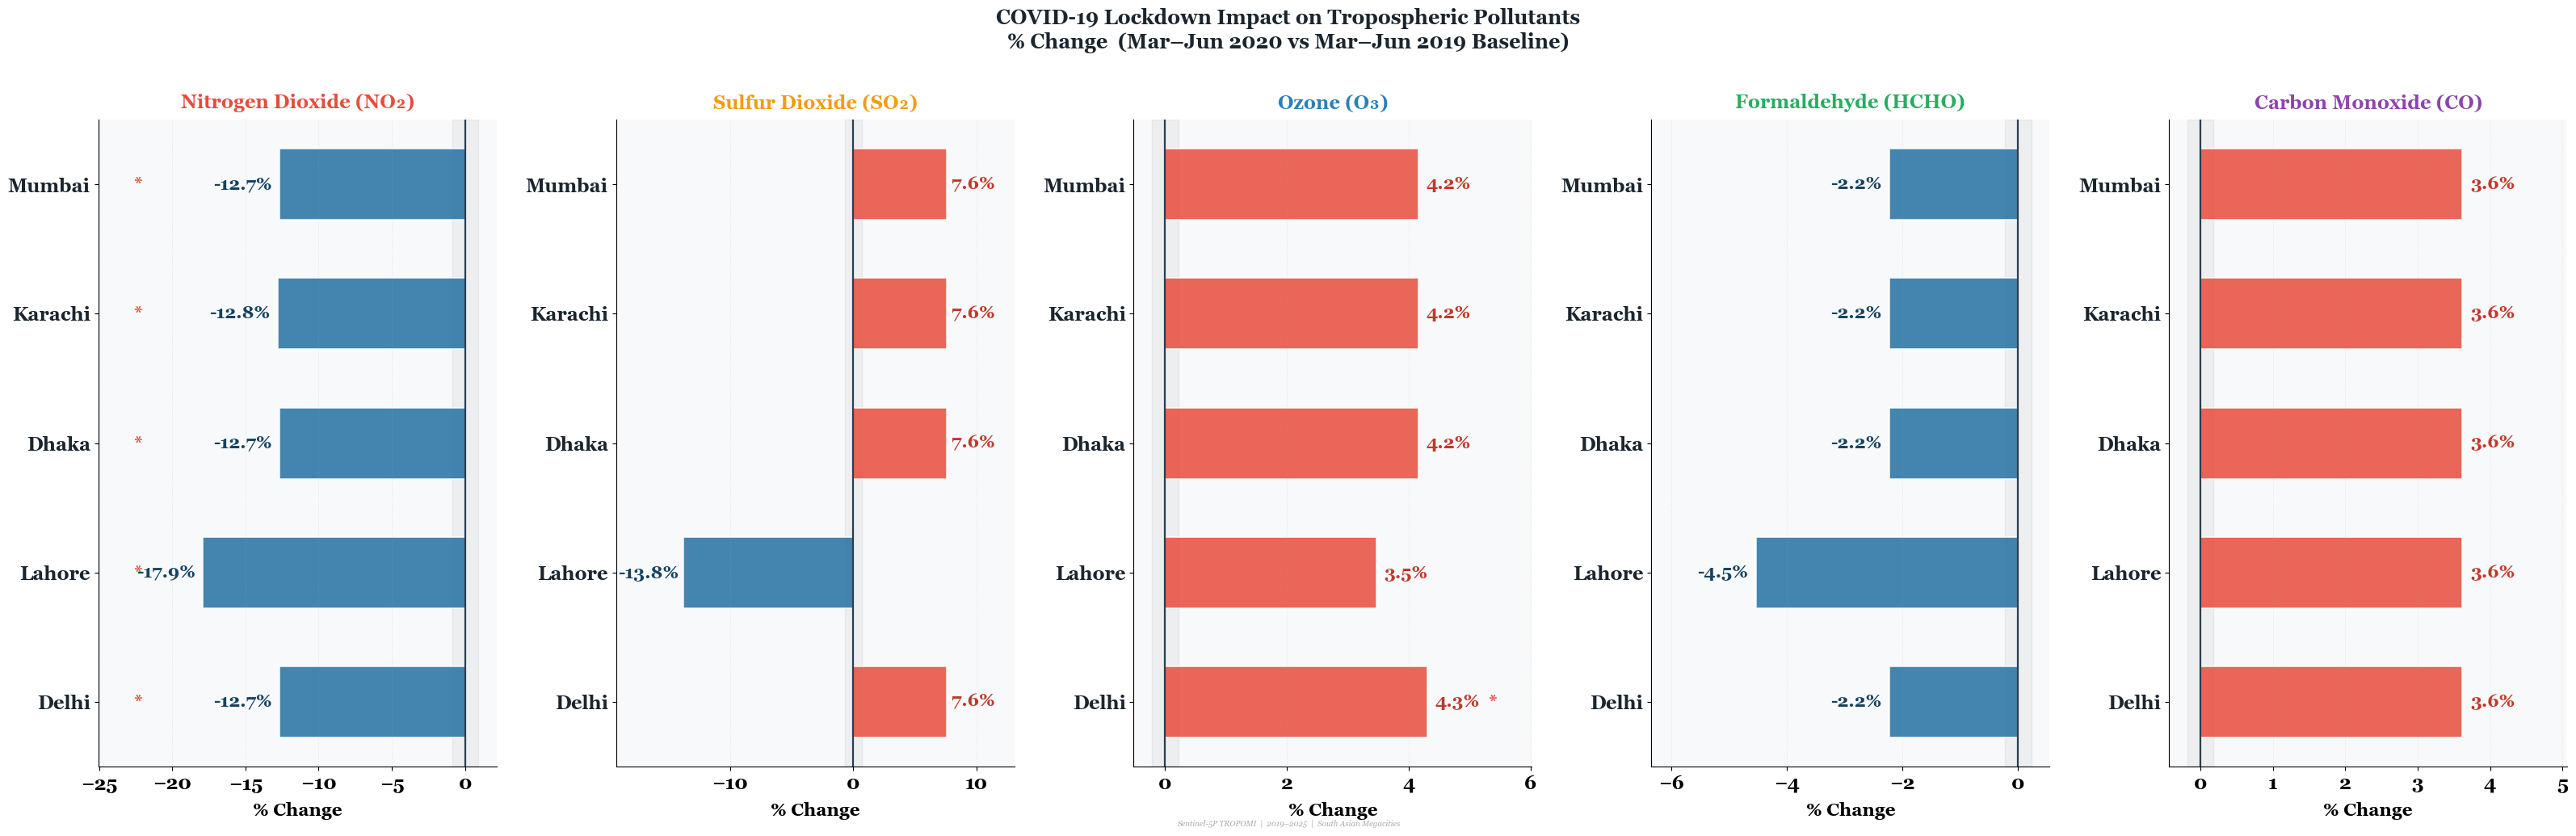

  ✓ Saved → Fig8a_COVID_Anomaly_Bar.png
✓ Figure 8a — COVID Anomaly Bar saved.


In [34]:
# ── CELL 16 — COVID FIGURE 8a: ENHANCED TEXT & SPACING ───────────────────────

fig, axes = plt.subplots(1, 5, figsize=(32, 10))
fig.suptitle(
    "COVID-19 Lockdown Impact on Tropospheric Pollutants\n"
    "% Change  (Mar–Jun 2020 vs Mar–Jun 2019 Baseline)",
    fontsize=18,
    fontweight="bold",
    y=1.02,
    color="#1A252F",
)

for ax_i, gas in enumerate(GASES):
    ax = axes[ax_i]
    data_gas = covid_df[covid_df["Gas"] == gas].set_index("City")
    pcts = [data_gas.loc[c, "% Change"] for c in CITIES]

    x_min = min(pcts)
    x_max = max(pcts)
    x_range = max(abs(x_min), abs(x_max))

    label_offset = x_range * 0.03

    for c_i, (city, pct) in enumerate(zip(CITIES, pcts)):
        bar_color = "#E74C3C" if pct > 0 else "#2471A3"
        ax.barh(
            c_i,
            pct,
            color=bar_color,
            alpha=0.85,
            edgecolor="white",
            linewidth=1.2,
            height=0.55,
        )

        if pct >= 0:
            label_x = pct + label_offset
            ha = "left"
        else:
            label_x = pct - label_offset
            ha = "right"

        label_color = "#C0392B" if pct > 0 else "#154360"

        # ── 1. CONTROL BAR VALUE TEXT SIZE (% VALUES NEXT TO BARS) ───────────
        ax.text(
            label_x,
            c_i,
            f"{pct:.1f}%",
            va="center",
            ha=ha,
            fontsize=16,  # ◄── INCREASE THIS (e.g., 12 or 13)
            fontweight="bold",
            color=label_color,
        )

        # Significance star size
        sig_ = data_gas.loc[city, "Significance"]
        if sig_ != "ns":
            star_x = (
                (x_max + x_range * 0.25)
                if x_max >= 0
                else (x_min - x_range * 0.25)
            )
            ax.text(
                star_x,
                c_i,
                sig_,
                va="center",
                ha="center",
                fontsize=16,  # ◄── Increased for visibility
                color="#E74C3C",
                fontweight="bold",
            )

    # Y-axis City Labels
    ax.set_yticks(range(len(CITIES)))
    ax.set_yticklabels(
        CITIES, fontsize=17, fontweight="bold", color="#1A252F"
    )

    padding = x_range * 0.40
    ax.set_xlim(
        x_min - padding if x_min < 0 else -padding * 0.3,
        x_max + padding if x_max > 0 else padding * 0.3,
    )

    ax.axvline(0, color="#2C3E50", linewidth=1.6, zorder=5)
    ax.set_title(
        GAS_FULL[gas],
        fontsize=17,
        fontweight="bold",
        color=GAS_COLORS[gas],
        pad=10,
    )

    # ── 2. CONTROL "% CHANGE" X-AXIS LABEL SIZE ──────────────────────────────
    ax.set_xlabel("% Change", fontsize=16, fontweight="bold", labelpad=8)  # ◄── INCREASE THIS

    # ── 3. CONTROL NUMERICAL TICK VALUES SIZE ON X-AXIS ──────────────────────
    ax.tick_params(axis="x", labelsize=17)  # ◄── INCREASE THIS (e.g., 12 or 13)
    for label in ax.get_xticklabels():
        label.set_fontweight("bold")  # Added bolding for extra clarity

    ax.grid(axis="x", alpha=0.3, linestyle=":", color="#AAAAAA")
    ax.set_facecolor("#F8F9FA")
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

    ax.axvspan(
        -0.05 * x_range, 0.05 * x_range, alpha=0.06, color="#2C3E50", zorder=0
    )

plt.tight_layout()

# ── 4. CONTROL SPACING BETWEEN SUBPLOTS ──────────────────────────────────────
# Smaller wspace brings plots closer; larger wspace pushes them apart
fig.subplots_adjust(wspace=0.30)  # ◄── ADJUST THIS (e.g., 0.30 to 0.50)

add_watermark(fig)
save_fig(fig, out("covid", "Fig8a_COVID_Anomaly_Bar.png"))
print("✓ Figure 8a — COVID Anomaly Bar saved.")

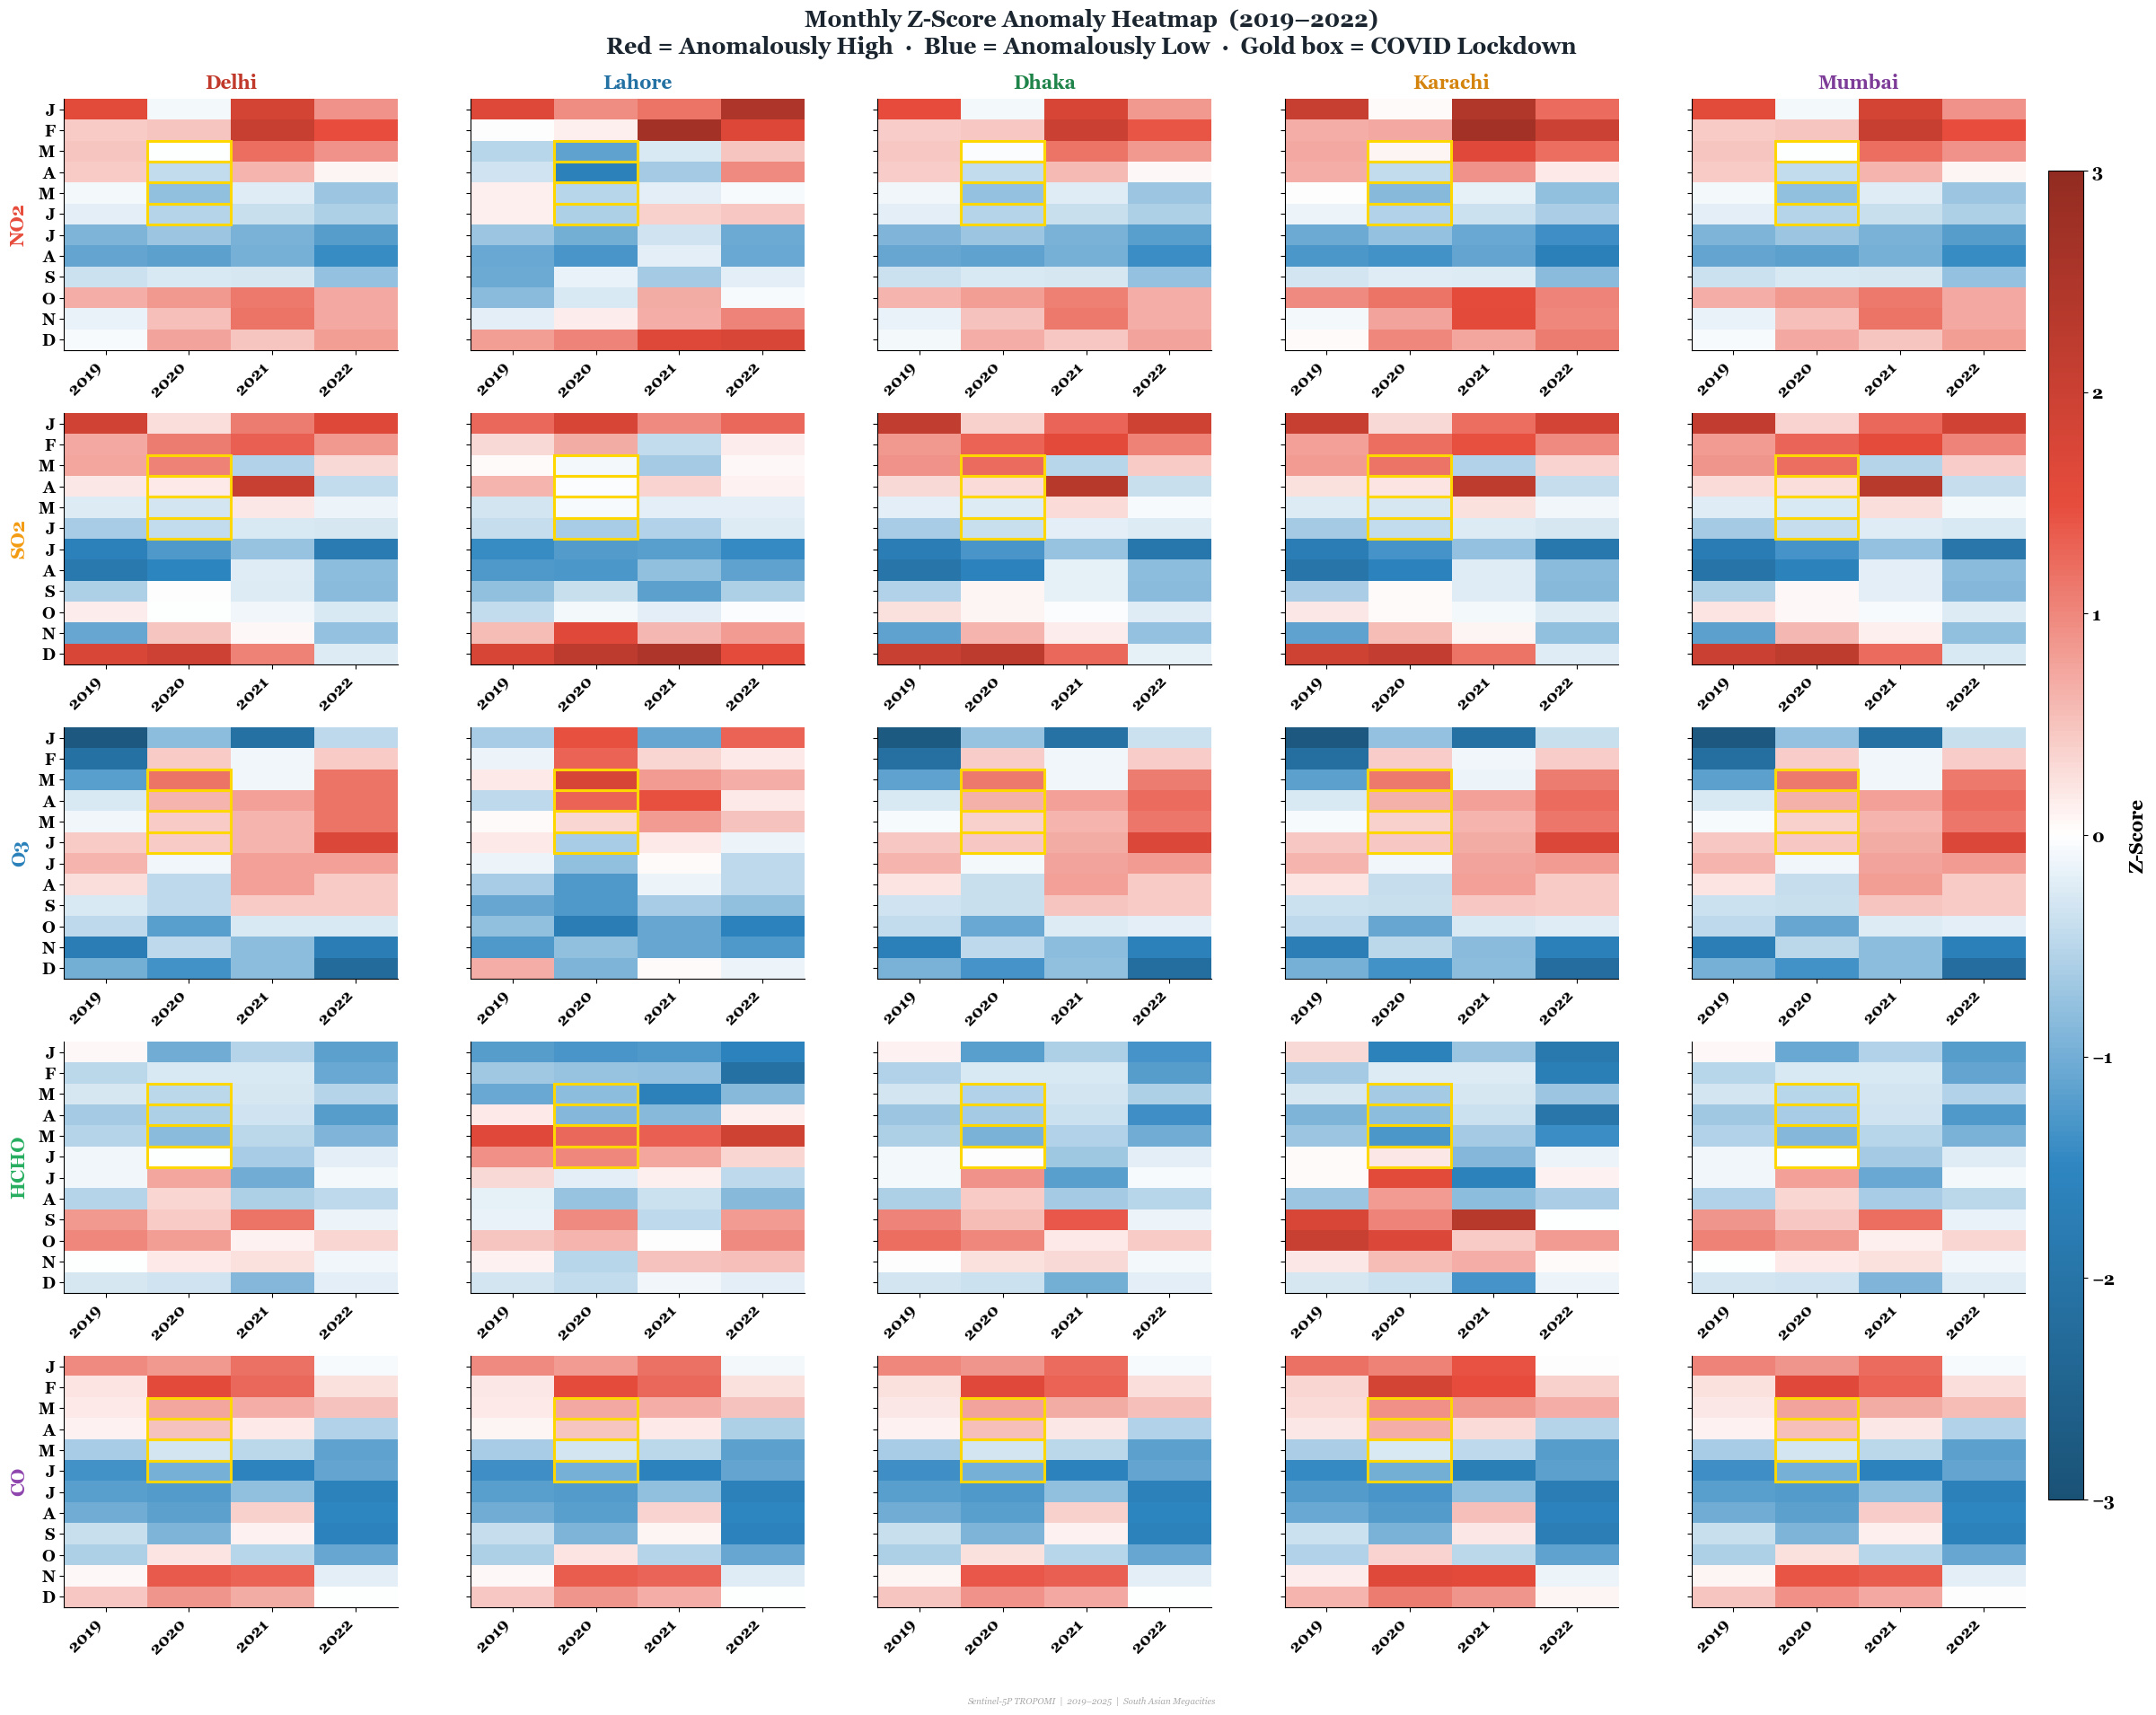

✓ Figure 8b — Z-Score Anomaly Heatmap saved with tight margins.


In [36]:
# ── CELL — Monthly Z-Score Anomaly Heatmap (Fig 8b - Updated) ─────────────────

fig, axes = plt.subplots(5, 5, figsize=(26, 20))  # Slightly reduced figure height
fig.suptitle(
    "Monthly Z-Score Anomaly Heatmap  (2019–2022)\n"
    "Red = Anomalously High  ·  Blue = Anomalously Low  ·  Gold box = COVID Lockdown",
    fontsize=18,
    fontweight="bold",
    y=0.95,  # ◄── LOWERED TO REMOVE TOP WHITE SPACE
    color="#1A252F",
)

for row_i, gas in enumerate(GASES):
    for col_i, city in enumerate(CITIES):
        ax = axes[row_i][col_i]
        series = dfs[city].set_index("Date")[gas]
        mean_ = series.mean()
        std_ = series.std()
        sub = series[(series.index.year >= 2019) & (series.index.year <= 2022)]
        z_s = (sub - mean_) / (std_ + 1e-30)

        pivot_z = pd.DataFrame(
            {
                "Z": z_s.values,
                "Year": z_s.index.year,
                "Month": z_s.index.month,
            }
        ).pivot(index="Month", columns="Year", values="Z")

        im = ax.imshow(
            pivot_z.values,
            aspect="auto",
            cmap=ANOMALY_CMAP,
            vmin=-3,
            vmax=3,
            interpolation="nearest",
        )

        # ── 1. X-AXIS TICK LABELS (YEARS) ─────────────────────────────────────
        ax.set_xticks(range(len(pivot_z.columns)))
        ax.set_xticklabels(
            pivot_z.columns,
            fontsize=13,  # ◄── ENLARGED X-AXIS VALUES
            fontweight="bold",
            rotation=45,
            ha="right",
        )

        # ── 2. Y-AXIS TICK LABELS (MONTHS) ────────────────────────────────────
        ax.set_yticks(range(12))
        mlabels = ["J", "F", "M", "A", "M", "J", "J", "A", "S", "O", "N", "D"]
        ax.set_yticklabels(
            mlabels if col_i == 0 else [],
            fontsize=13,  # ◄── ENLARGED Y-AXIS MONTH VALUES
            fontweight="bold",
        )

        if row_i == 0:
            ax.set_title(
                city,
                fontsize=15,
                fontweight="bold",
                color=CITY_COLORS[city],
                pad=8,
            )
        if col_i == 0:
            ax.set_ylabel(
                gas,
                fontsize=15,
                fontweight="bold",
                color=GAS_COLORS[gas],
                labelpad=8,
            )

        # Gold COVID boxes (Mar=2, Apr=3, May=4, Jun=5 → 0-indexed rows 2-5)
        for y_i, yr in enumerate(pivot_z.columns):
            if yr == 2020:
                for m_row in [2, 3, 4, 5]:
                    rect = plt.Rectangle(
                        (y_i - 0.5, m_row - 0.5),
                        1,
                        1,
                        fill=False,
                        edgecolor="gold",
                        linewidth=2.2,
                    )
                    ax.add_patch(rect)

# ── 3. ADJUST GRID MARGINS (REDUCES TOP & BOTTOM EXTRA WHITE SPACE) ────────────
fig.subplots_adjust(
    left=0.06,
    right=0.90,
    top=0.90,  # ◄── Tightened top margin
    bottom=0.06,  # ◄── Tightened bottom margin
    hspace=0.25,
    wspace=0.22,
)

# ── 4. COLORBAR CONTROLS ──────────────────────────────────────────────────────
cbar_ax = fig.add_axes([0.91, 0.12, 0.015, 0.74])  # Position & height
sm = plt.cm.ScalarMappable(cmap=ANOMALY_CMAP, norm=plt.Normalize(-3, 3))
sm.set_array([])
cb = fig.colorbar(sm, cax=cbar_ax)

# Colorbar label settings
cb.set_label(
    "Z-Score", fontsize=15, fontweight="bold", labelpad=10  # ◄── Z-SCORE TEXT SIZE
)

# Colorbar numeric values settings (-3, -2, -1, 0, 1, 2, 3)
cb.ax.tick_params(labelsize=14)  # ◄── COLORBAR NUMERIC VALUES SIZE
for label in cb.ax.get_yticklabels():
    label.set_fontweight("bold")

add_watermark(fig)
fig.savefig(
    out("covid", "Fig8b_Zscore_Anomaly_Heatmap.png"),
    dpi=600,
    bbox_inches="tight",
    facecolor="white",
)
plt.show()
print("✓ Figure 8b — Z-Score Anomaly Heatmap saved with tight margins.")

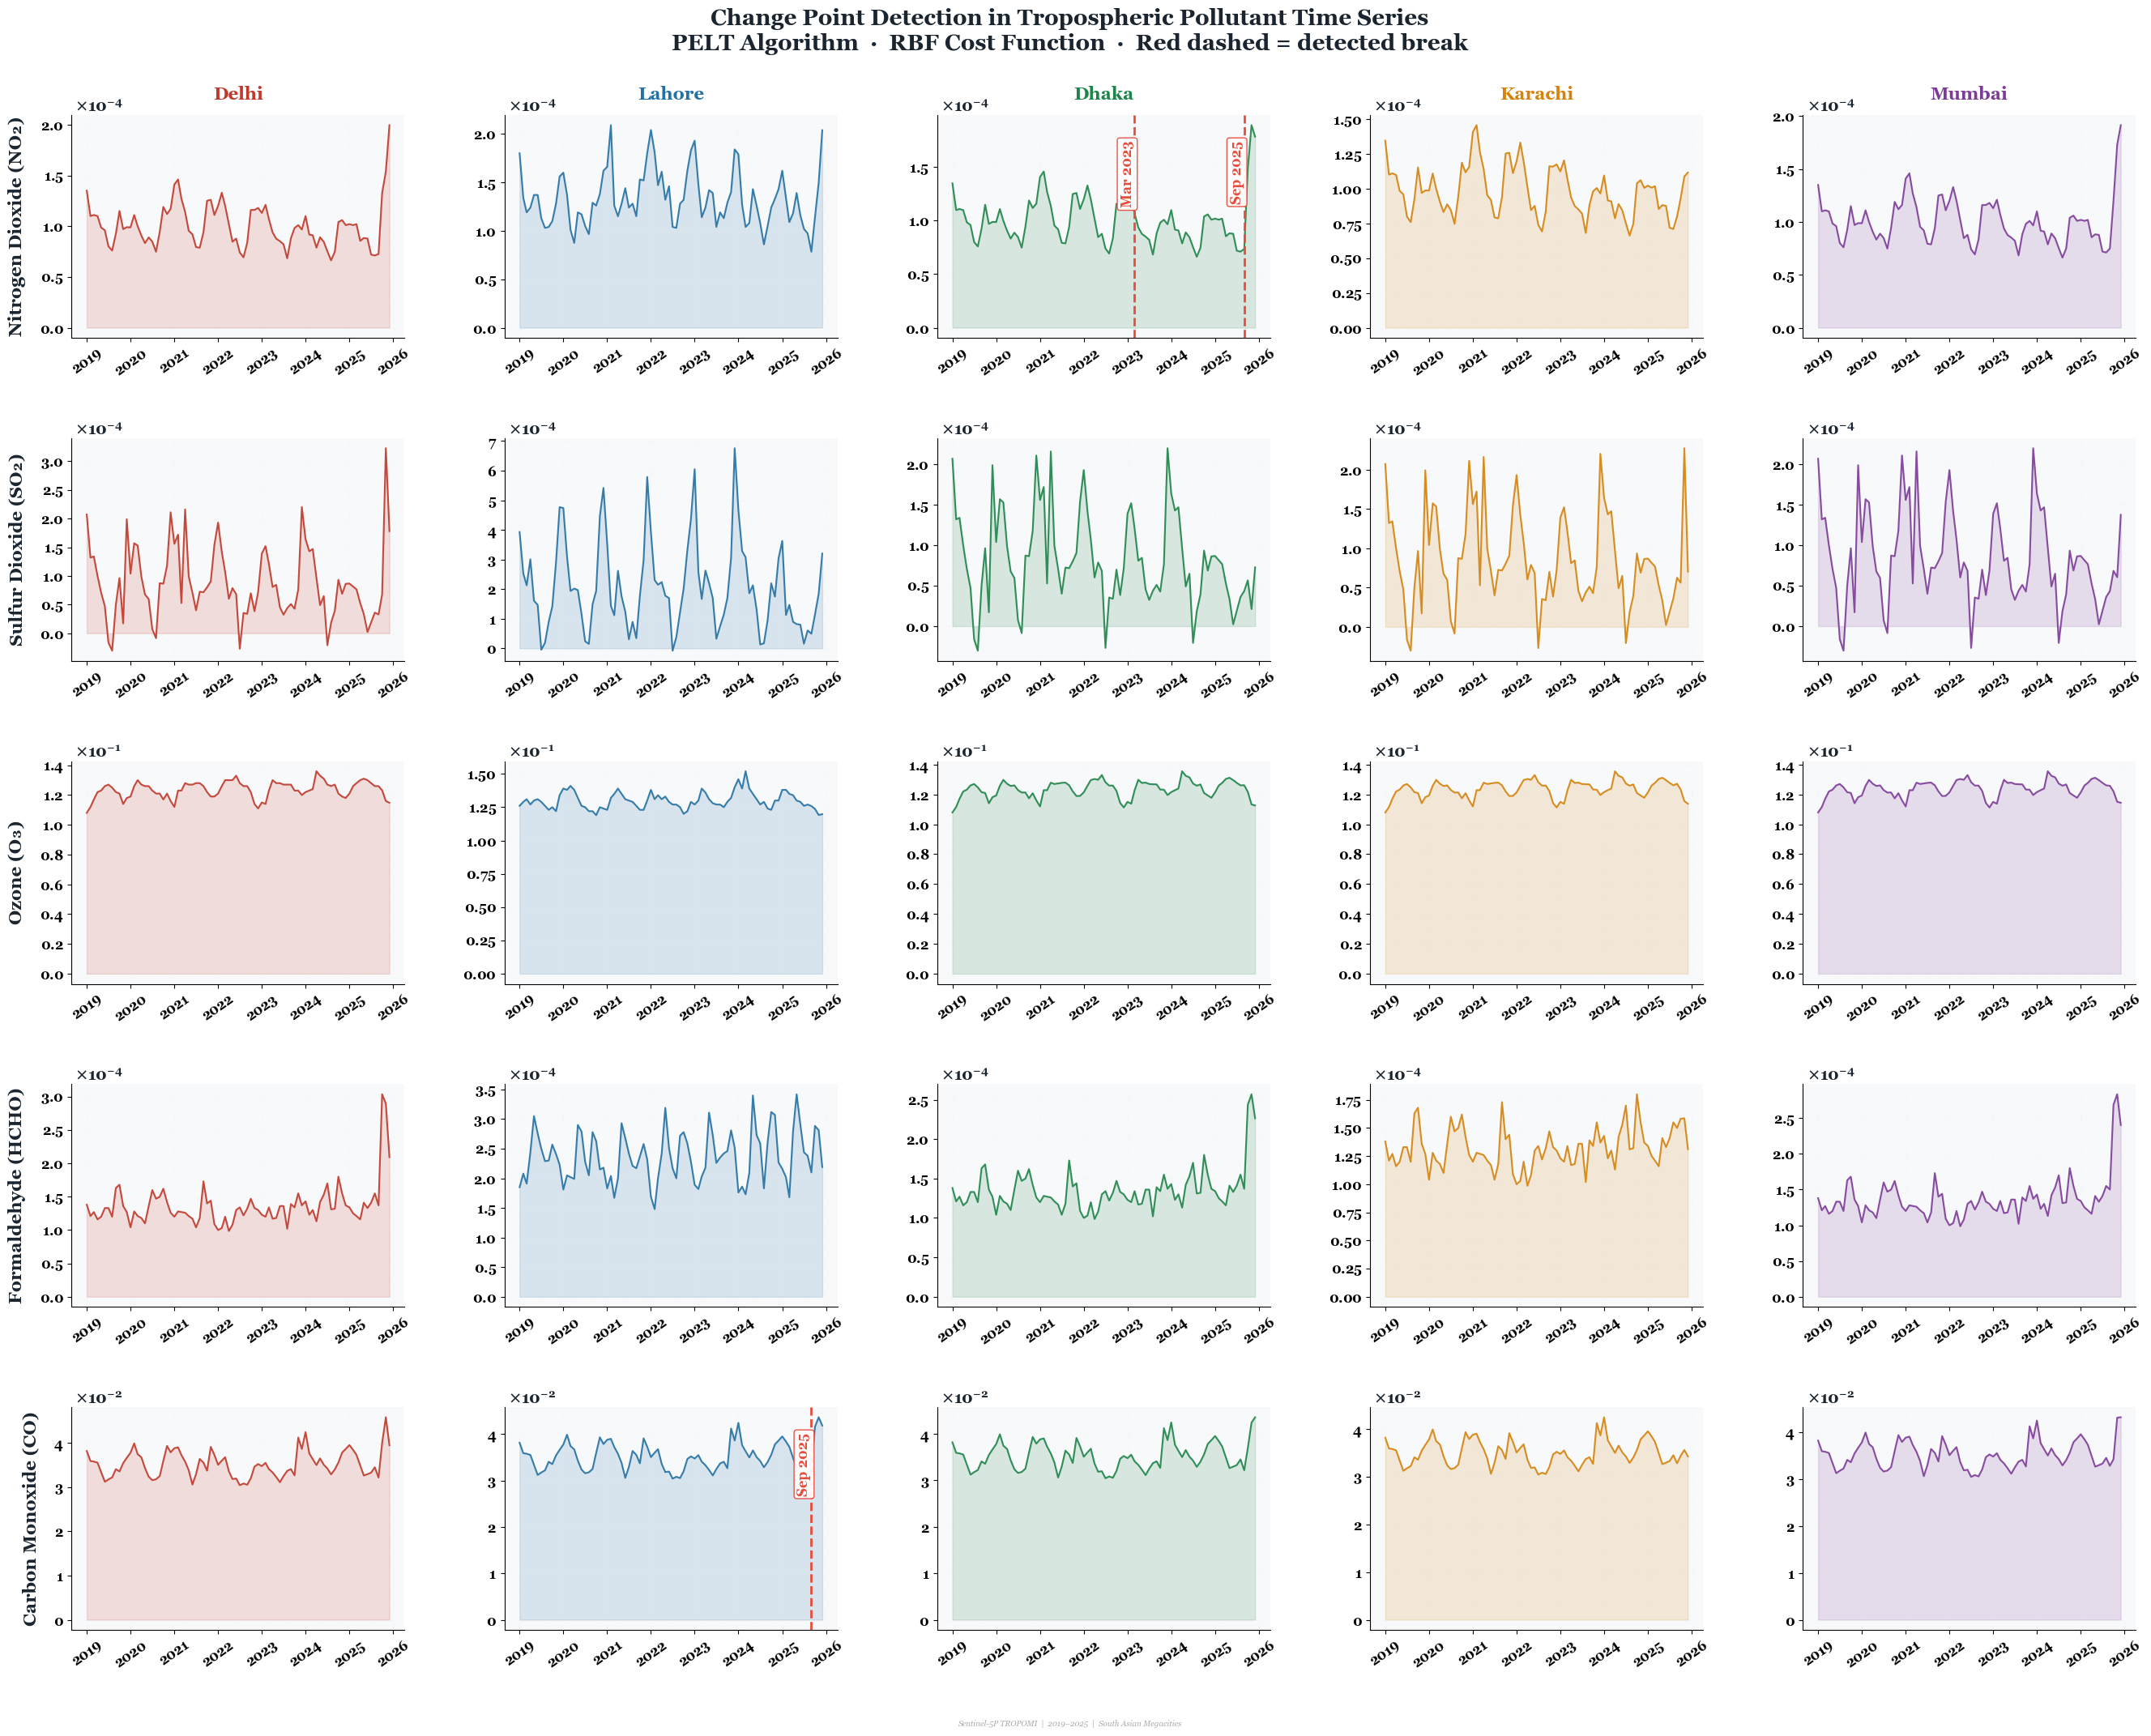

  ✓ Saved → Fig9_Change_Point_Detection.png
✓ Figure 9 — Change Point Detection saved with active PELT break lines.


In [38]:
# ── CELL — Change Point Detection Grid (Fig 9 - FIXED: PELT Lines Active) ─────

import matplotlib.dates as mdates
import pandas as pd
import ruptures as rpt  # ◄── Required for PELT algorithm

# 1. EXPANDED FIGURE SIZE FOR MAXIMUM CLARITY
fig, axes = plt.subplots(5, 5, figsize=(28, 22), sharex=False)

# 2. MAIN TITLE ADJUSTMENT
fig.suptitle(
    "Change Point Detection in Tropospheric Pollutant Time Series\n"
    "PELT Algorithm  ·  RBF Cost Function  ·  Red dashed = detected break",
    fontsize=20,
    fontweight="bold",
    y=0.97,
    color="#1A252F",
)

for row_i, gas in enumerate(GASES):
    for col_i, city in enumerate(CITIES):
        ax = axes[row_i][col_i]

        # Pull data for specific city and gas
        series = dfs[city].set_index("Date")[gas].dropna()
        color = CITY_COLORS[city]

        # Plot time series line & fill
        ax.plot(
            series.index, series.values, color=color, linewidth=1.5, alpha=0.9
        )
        ax.fill_between(series.index, series.values, alpha=0.15, color=color)

        # ── 3. RUN PELT ALGORITHM & DRAW RED DASHED LINES ─────────────────────
        if len(series) > 12:
            try:
                # Prepare signal array for PELT
                signal = series.values.reshape(-1, 1)

                # Run PELT with RBF cost model (pen = penalty parameter)
                algo = rpt.Pelt(model="rbf", min_size=3, jump=1).fit(signal)
                # Change pen value (e.g., 3, 5, or 10) to control sensitivity
                result = algo.predict(pen=3)

                # Extract change point dates (excluding the last endpoint index)
                bkps_indices = [bk - 1 for bk in result[:-1] if bk < len(series)]
                bkps_dates = series.index[bkps_indices]

                # Draw red dashed line and date box for each detected break
                for bk in bkps_dates:
                    ax.axvline(
                        x=bk, color="#E74C3C", linestyle="--", linewidth=2.0, zorder=5
                    )
                    
                    # Annotate Date Label on top of the dashed line
                    ax.text(
                        bk,
                        ax.get_ylim()[1] * 0.88,
                        bk.strftime("%b %Y"),
                        rotation=90,
                        fontsize=12,
                        fontweight="bold",
                        color="#E74C3C",
                        ha="right",
                        va="top",
                        bbox=dict(
                            boxstyle="round,pad=0.2",
                            fc="white",
                            ec="#E74C3C",
                            lw=1,
                            alpha=0.95,
                        ),
                        zorder=6,
                    )
            except Exception as e:
                pass

        # ── 4. SCIENTIFIC NOTATION & 10^X MULTIPLIER CONTROL ──────────────────
        sci_fmt(ax, axis="y")  # Custom scientific formatter

        offset_text = ax.yaxis.get_offset_text()
        offset_text.set_fontsize(14)
        offset_text.set_fontweight("bold")
        offset_text.set_color("#1A252F")
        offset_text.set_position((0.01, 1.05))

        # ── 5. TICK LABELS (X-AXIS YEARS & Y-AXIS NUMBERS) ─────────────────────
        ax.tick_params(axis="y", labelsize=12)
        for label in ax.get_yticklabels():
            label.set_fontweight("bold")

        ax.xaxis.set_major_locator(mdates.YearLocator())
        ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
        ax.tick_params(axis="x", labelsize=12, rotation=35)
        for label in ax.get_xticklabels():
            label.set_fontweight("bold")

        # ── 6. CITY NAMES (TOP ROW ONLY) ──────────────────────────────────────
        if row_i == 0:
            ax.set_title(
                city,
                fontsize=16,
                fontweight="bold",
                color=CITY_COLORS[city],
                pad=14,
            )

        # ── 7. GAS NAMES (LEFT COLUMN ONLY - LARGE & READABLE) ────────────────
        if col_i == 0:
            ax.set_ylabel(
                GAS_FULL[gas],
                fontsize=16,
                fontweight="bold",
                color="#1A252F",
                labelpad=12,
            )

        ax.grid(alpha=0.3, linestyle=":")
        ax.set_facecolor("#F8F9FA")

# ── 8. SPACING CONTROL (PREVENTS ALL OVERLAPS) ────────────────────────────────
fig.subplots_adjust(
    left=0.06,
    right=0.97,
    top=0.91,
    bottom=0.06,
    wspace=0.30,
    hspace=0.45,
)

add_watermark(fig)
save_fig(fig, out("changepoint", "Fig9_Change_Point_Detection.png"))
print(
    "✓ Figure 9 — Change Point Detection saved with active PELT break lines."
)

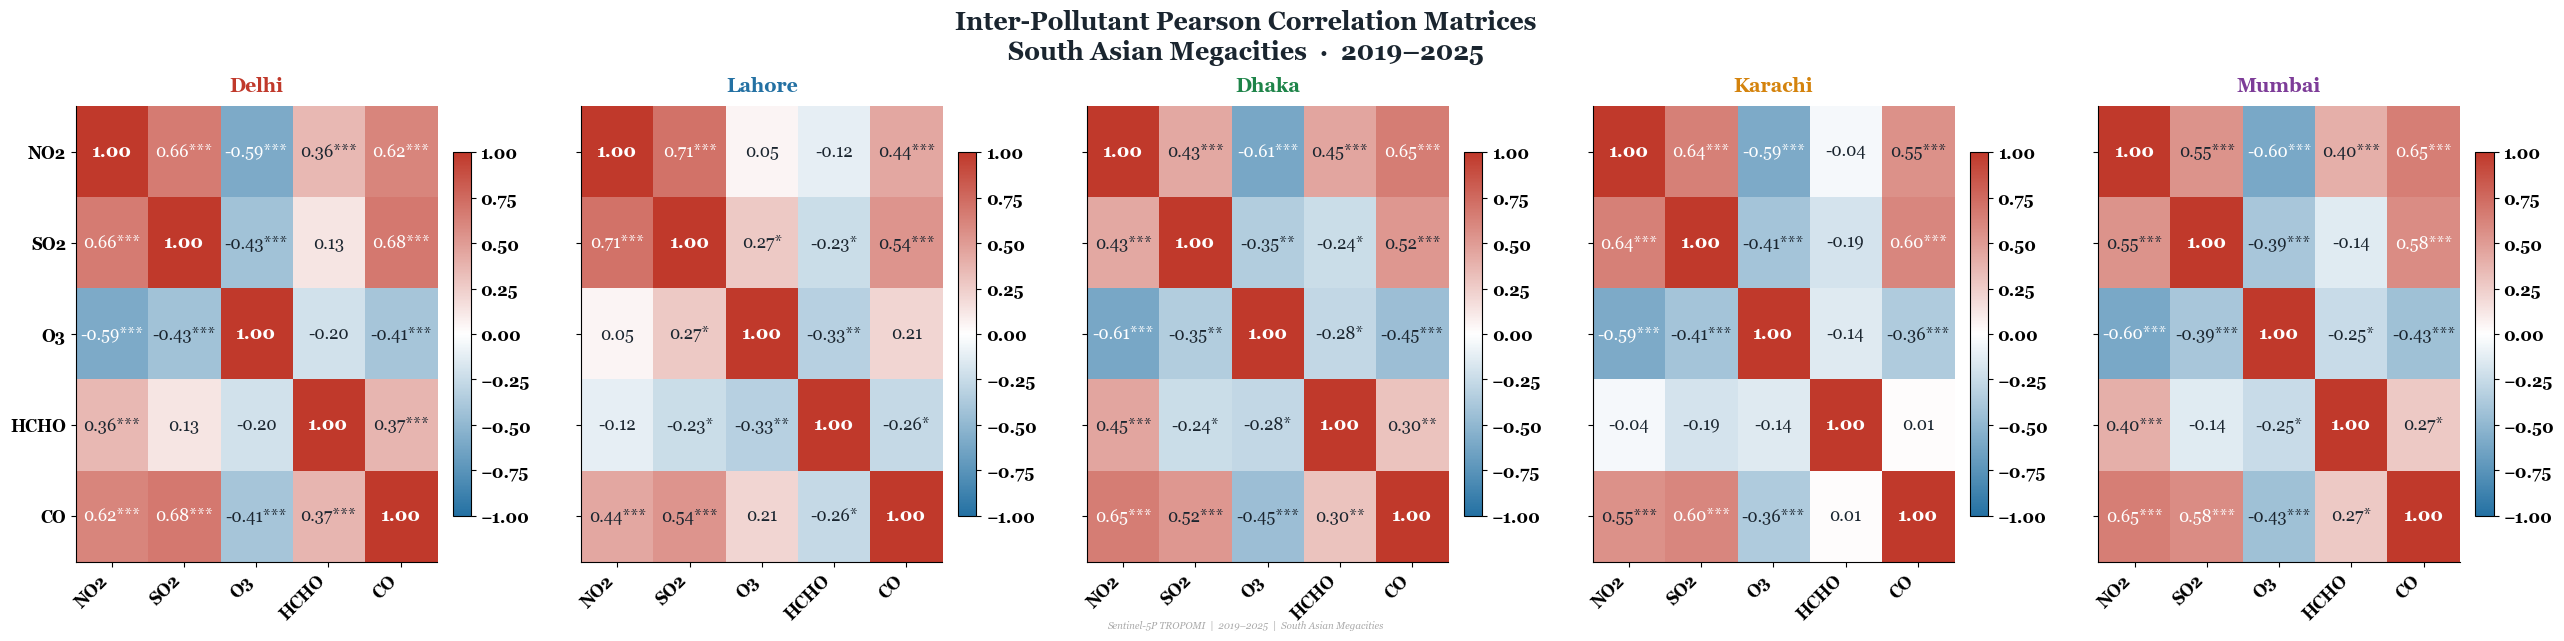

  ✓ Saved → Fig10_InterPollutant_Correlation.png
✓ Figure 10 — Inter-Pollutant Correlation saved with enlarged fonts.


In [40]:
# ── CELL — Inter-Pollutant Pearson Correlation Matrices (Fig 10) ──────────────
# ──────────────────────────────────────────────────────────────────────────────
# 🎛️ FONT SIZE & LAYOUT CONTROLS — EDIT YOUR SIZES HERE
# ──────────────────────────────────────────────────────────────────────────────
TITLE_FONTSIZE = 18  # Main title font size
CITY_TITLE_FONTSIZE = 14  # City titles (Delhi, Lahore, etc.)

HEATMAP_CELL_FONTSIZE = 12  # ◄── TEXT SIZE INSIDE BOXES (e.g. 0.66***)
DIAGONAL_CELL_FONTSIZE = 13  # ◄── TEXT SIZE FOR DIAGONAL 1.00 VALUES

X_TICK_FONTSIZE = 12  # ◄── X-AXIS TICK VALUES (NO2, SO2, O3...)
Y_TICK_FONTSIZE = 12  # ◄── Y-AXIS TICK VALUES (NO2, SO2, O3...)

CBAR_TICK_FONTSIZE = 12  # ◄── NUMERICAL VALUES ON SIDE COLORBARS
# ──────────────────────────────────────────────────────────────────────────────

fig, axes = plt.subplots(1, 5, figsize=(26, 6))

fig.suptitle(
    "Inter-Pollutant Pearson Correlation Matrices\n"
    "South Asian Megacities  ·  2019–2025",
    fontsize=TITLE_FONTSIZE,
    fontweight="bold",
    y=1.04,  # ◄── Adjusted y to reduce top white space
    color="#1A252F",
)

all_corr_rows = []

for ax_i, city in enumerate(CITIES):
    df_wide = dfs[city][GASES].dropna()
    corr = df_wide.corr(method="pearson")
    pval_df = pd.DataFrame(index=GASES, columns=GASES, dtype=float)

    for g1 in GASES:
        for g2 in GASES:
            if g1 == g2:
                pval_df.loc[g1, g2] = 1.0
            else:
                r_, p_ = stats.pearsonr(df_wide[g1], df_wide[g2])
                pval_df.loc[g1, g2] = p_
                if GASES.index(g2) > GASES.index(g1):
                    all_corr_rows.append(
                        {
                            "City": city,
                            "Gas1": g1,
                            "Gas2": g2,
                            "Pearson r": round(r_, 3),
                            "p-value": round(p_, 5),
                            "Sig": (
                                "***"
                                if p_ < 0.001
                                else "**"
                                if p_ < 0.01
                                else "*"
                                if p_ < 0.05
                                else "ns"
                            ),
                        }
                    )

    ax = axes[ax_i]
    im = ax.imshow(
        corr.values, cmap=DIVERGE_CMAP, vmin=-1, vmax=1, aspect="auto"
    )

    # ── 1. AXES TICK SETTINGS ─────────────────────────────────────────────────
    ax.set_xticks(range(len(GASES)))
    ax.set_yticks(range(len(GASES)))

    # X-Axis Ticks
    ax.set_xticklabels(
        GASES,
        rotation=45,
        ha="right",
        fontsize=X_TICK_FONTSIZE,
        fontweight="bold",
    )

    # Y-Axis Ticks (Only show labels on the leftmost matrix)
    if ax_i == 0:
        ax.set_yticklabels(
            GASES, fontsize=Y_TICK_FONTSIZE, fontweight="bold"
        )
    else:
        ax.set_yticklabels([])

    ax.set_title(
        city,
        fontsize=CITY_TITLE_FONTSIZE,
        fontweight="bold",
        color=CITY_COLORS[city],
        pad=10,
    )

    # ── 2. NUMERICAL VALUES & STARS INSIDE HEATMAP BOXES ──────────────────────
    for i, g1 in enumerate(GASES):
        for j, g2 in enumerate(GASES):
            r_ = corr.loc[g1, g2]
            p_ = float(pval_df.loc[g1, g2])
            sig = (
                "***"
                if p_ < 0.001
                else "**"
                if p_ < 0.01
                else "*"
                if p_ < 0.05
                else ""
            )

            # Determine text size and weight based on whether it's the diagonal (1.00)
            cell_size = (
                DIAGONAL_CELL_FONTSIZE if i == j else HEATMAP_CELL_FONTSIZE
            )
            cell_weight = "bold" if i == j else "normal"

            ax.text(
                j,
                i,
                f"{r_:.2f}{sig}",
                ha="center",
                va="center",
                fontsize=cell_size,  # ◄── APPLIES CONTROLLED FONT SIZE
                color="white" if abs(r_) > 0.55 else "#1A252F",
                fontweight=cell_weight,
            )

    # ── 3. COLORBAR TICK SIZE ──────────────────────────────────────────────────
    cb = plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
    cb.ax.tick_params(labelsize=CBAR_TICK_FONTSIZE)  # ◄── COLORBAR NUMBERS SIZE
    for label in cb.ax.get_yticklabels():
        label.set_fontweight("bold")

# ── 4. REDUCE WHITE SPACE (MARGIN & PADDING CONTROLS) ─────────────────────────
fig.subplots_adjust(
    left=0.05,
    right=0.98,
    top=0.88,  # ◄── Tightens upper white space
    bottom=0.12,  # ◄── Tightens lower white space
    wspace=0.28,  # Horizontal spacing between individual matrices
)

add_watermark(fig)
save_fig(fig, out("corr", "Fig10_InterPollutant_Correlation.png"))

pd.DataFrame(all_corr_rows).to_csv(
    out("tables", "InterPollutant_Pearson_Correlation.csv"), index=False
)
print("✓ Figure 10 — Inter-Pollutant Correlation saved with enlarged fonts.")

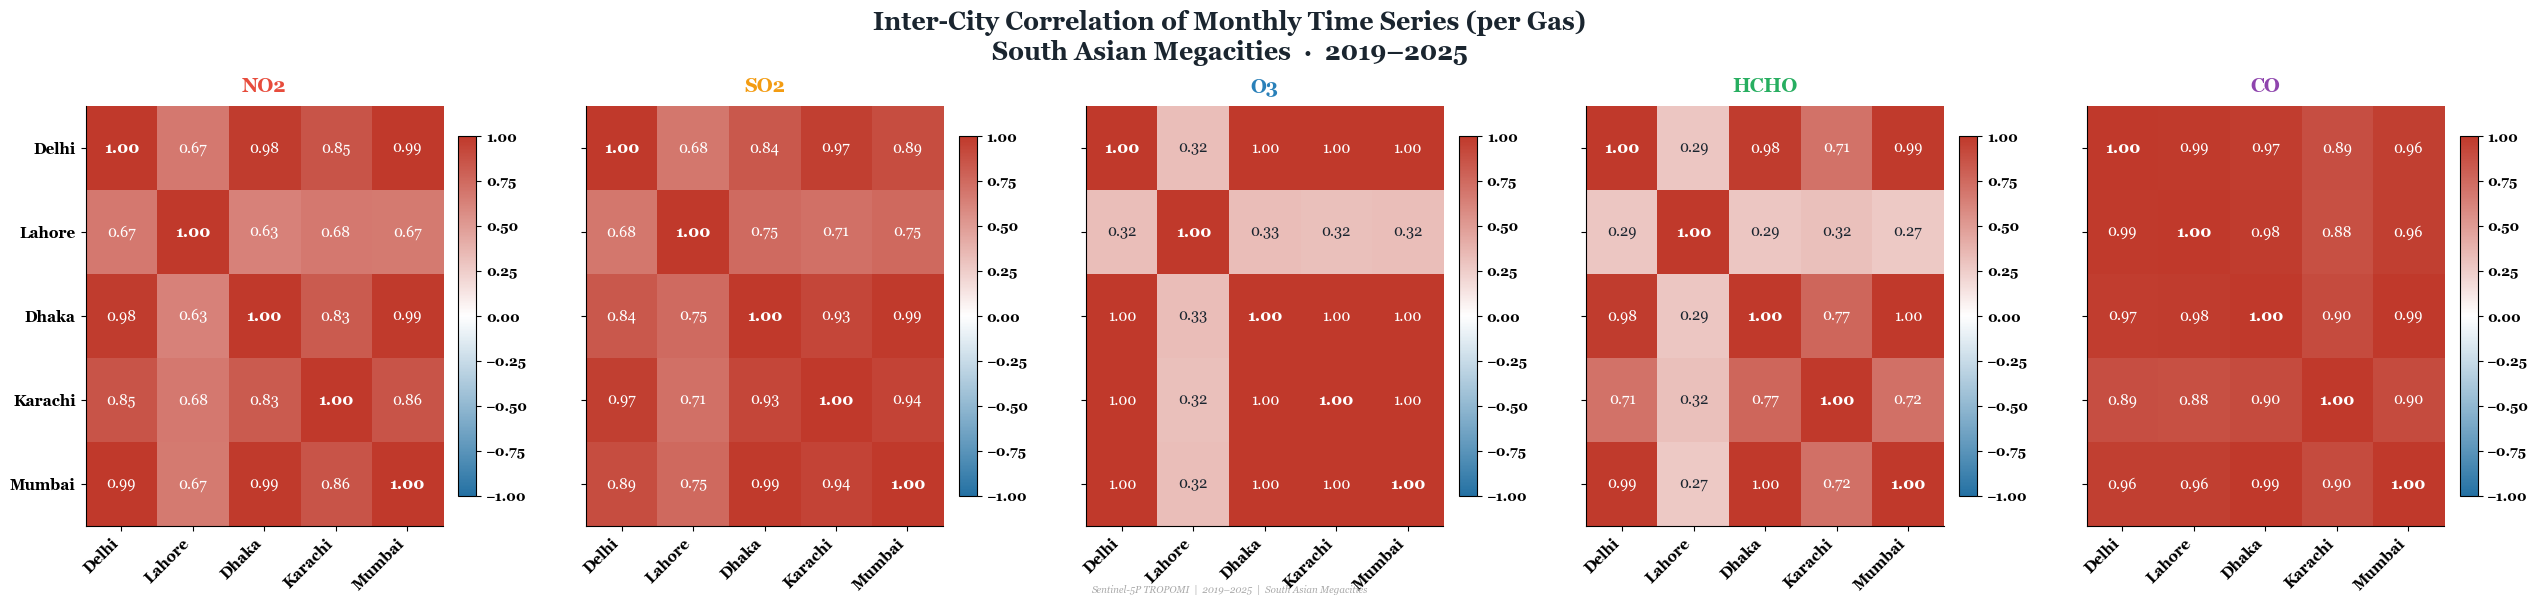

  ✓ Saved → Fig11_InterCity_Correlation.png
✓ Figure 11 — Inter-City Correlation saved with full font control.


In [44]:
# ── CELL — Inter-City Correlation Matrix (Fig 11) ───────────────────────────

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# ──────────────────────────────────────────────────────────────────────────────
# 🎛️ FONT SIZE & LAYOUT CONTROLS — EDIT ALL SIZES HERE
# ──────────────────────────────────────────────────────────────────────────────
TITLE_FONTSIZE = 18  # Main figure title size
GAS_TITLE_FONTSIZE = 14  # Gas titles above each plot (NO2, SO2, O3, etc.)

HEATMAP_CELL_FONTSIZE = 10.5  # ◄── NUMERICAL VALUES INSIDE BOXES (e.g., 0.85)
DIAGONAL_CELL_FONTSIZE = 11.5  # ◄── DIAGONAL 1.00 VALUES SIZE

X_TICK_FONTSIZE = 11  # ◄── X-AXIS CITY NAMES (Delhi, Lahore, Dhaka...)
Y_TICK_FONTSIZE = 11  # ◄── Y-AXIS CITY NAMES

CBAR_TICK_FONTSIZE = 10  # ◄── NUMERICAL VALUES ON SIDE COLORBARS
# ──────────────────────────────────────────────────────────────────────────────

fig, axes = plt.subplots(1, 5, figsize=(26, 6))

# ── 1. MAIN TITLE & SPACING CONTROL ───────────────────────────────────────────
fig.suptitle(
    "Inter-City Correlation of Monthly Time Series (per Gas)\n"
    "South Asian Megacities  ·  2019–2025",
    fontsize=TITLE_FONTSIZE,
    fontweight="bold",
    y=0.98,  # ◄── Adjust y to control title vertical distance
    color="#1A252F",
)

for ax_i, gas in enumerate(GASES):
    combined = pd.DataFrame(
        {city: dfs[city].set_index("Date")[gas] for city in CITIES}
    )
    corr_c = combined.corr(method="pearson")

    ax = axes[ax_i]
    im = ax.imshow(
        corr_c.values, cmap=DIVERGE_CMAP, vmin=-1, vmax=1, aspect="auto"
    )

    # ── 2. TICK SETTINGS (CITY NAMES) ─────────────────────────────────────────
    ax.set_xticks(range(5))
    ax.set_yticks(range(5))

    # X-Axis Ticks
    ax.set_xticklabels(
        CITIES,
        rotation=45,
        ha="right",
        fontsize=X_TICK_FONTSIZE,
        fontweight="bold",
    )

    # Y-Axis Ticks (Only show on leftmost plot)
    if ax_i == 0:
        ax.set_yticklabels(
            CITIES, fontsize=Y_TICK_FONTSIZE, fontweight="bold"
        )
    else:
        ax.set_yticklabels([])

    # Gas Name Subplot Title
    ax.set_title(
        gas,
        fontsize=GAS_TITLE_FONTSIZE,
        fontweight="bold",
        color=GAS_COLORS[gas],
        pad=10,
    )

    # ── 3. NUMERICAL VALUES INSIDE HEATMAP BOXES ──────────────────────────────
    for i in range(5):
        for j in range(5):
            v = corr_c.values[i, j]

            # Adjust size and weight for diagonal vs non-diagonal values
            cell_size = (
                DIAGONAL_CELL_FONTSIZE if i == j else HEATMAP_CELL_FONTSIZE
            )
            cell_weight = "bold" if i == j else "normal"

            ax.text(
                j,
                i,
                f"{v:.2f}",
                ha="center",
                va="center",
                fontsize=cell_size,  # ◄── APPLIES CONTROLLED FONT SIZE
                color="white" if abs(v) > 0.55 else "#1A252F",
                fontweight=cell_weight,
            )

    # ── 4. COLORBAR TICK SIZE ──────────────────────────────────────────────────
    cb = plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
    cb.ax.tick_params(labelsize=CBAR_TICK_FONTSIZE)  # ◄── COLORBAR NUMBERS SIZE
    for label in cb.ax.get_yticklabels():
        label.set_fontweight("bold")

# ── 5. REDUCE MARGINS & ADJUST SUBPLOT SPACING ────────────────────────────────
fig.subplots_adjust(
    left=0.06,
    right=0.98,
    top=0.82,  # ◄── Distance between title and plots
    bottom=0.12,  # ◄── Bottom margin control
    wspace=0.28,  # ◄── Horizontal gap between matrices
)

add_watermark(fig)
save_fig(fig, out("corr", "Fig11_InterCity_Correlation.png"))
print("✓ Figure 11 — Inter-City Correlation saved with full font control.")

✓ Spearman table saved.


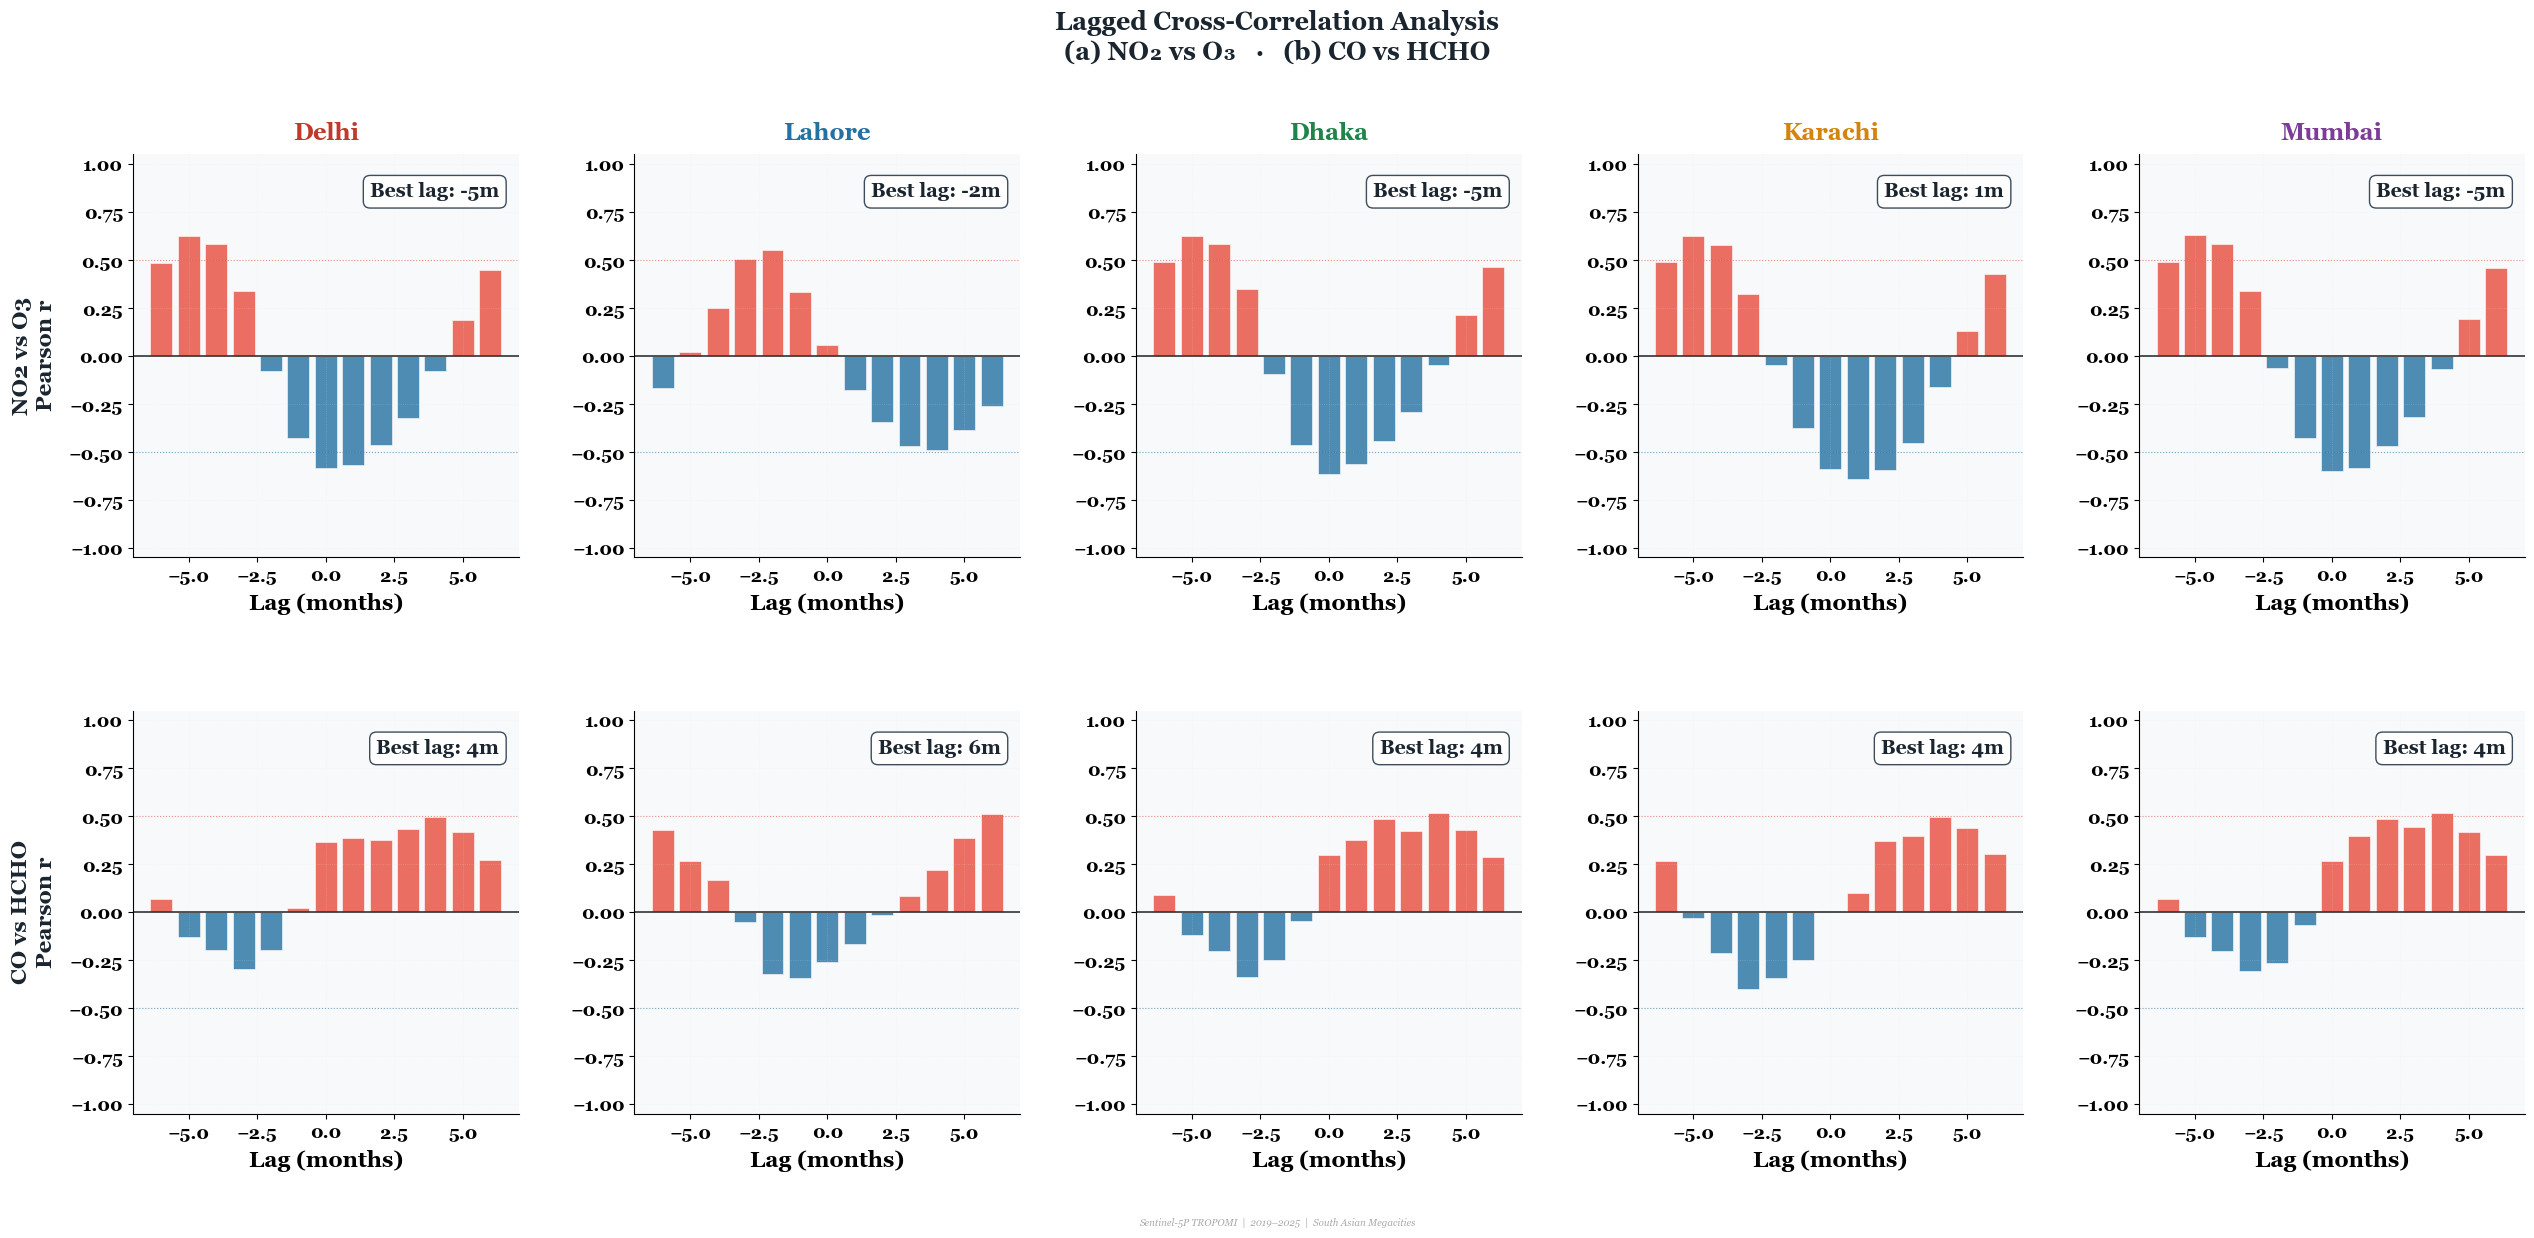

  ✓ Saved → Fig16_Lagged_CrossCorrelation.png
✓ Figure 16 — Lagged Cross-Correlation saved.


In [46]:
# ── CELL — Lagged Cross-Correlation Analysis (Fig 16) ────────────────────────

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats

# ──────────────────────────────────────────────────────────────────────────────
# 🎛️ FONT SIZE & LAYOUT CONTROLS — EDIT ALL SIZES HERE
# ──────────────────────────────────────────────────────────────────────────────
TITLE_FONTSIZE = 18  # Main figure title size
CITY_TITLE_FONTSIZE = 17  # City names (Delhi, Lahore, etc.)
Y_AXIS_LABEL_FONTSIZE = 16  # Y-axis labels ("NO2 vs O3 Pearson r")
X_AXIS_LABEL_FONTSIZE = 16  # X-axis labels ("Lag (months)")

X_TICK_FONTSIZE = 13  # ◄── NUMERICAL VALUES ON X-AXIS (-6, -4, -2, 0, 2, 4, 6)
Y_TICK_FONTSIZE = 13  # ◄── NUMERICAL VALUES ON Y-AXIS (-1.00, -0.50, 0.00...)

BEST_LAG_FONTSIZE = 14  # ◄── TEXT SIZE INSIDE "Best lag: Xm" BOX
# ──────────────────────────────────────────────────────────────────────────────

# Spearman table calculation
spearman_rows = []
for city in CITIES:
    df_w = dfs[city][GASES].dropna()
    for i, g1 in enumerate(GASES):
        for g2 in GASES[i + 1 :]:
            rho, p = stats.spearmanr(df_w[g1], df_w[g2])
            spearman_rows.append(
                {
                    "City": city,
                    "Gas1": g1,
                    "Gas2": g2,
                    "Spearman rho": round(rho, 3),
                    "p-value": round(p, 5),
                    "Sig": (
                        "***"
                        if p < 0.001
                        else "**"
                        if p < 0.01
                        else "*"
                        if p < 0.05
                        else "ns"
                    ),
                }
            )
pd.DataFrame(spearman_rows).to_csv(
    out("tables", "Spearman_Correlation.csv"), index=False
)
print("✓ Spearman table saved.")

# Lagged cross-correlation figure
fig, axes_lag = plt.subplots(2, 5, figsize=(26, 12))

# Main Title & Top Distance Control
fig.suptitle(
    "Lagged Cross-Correlation Analysis\n"
    "(a) NO₂ vs O₃   ·   (b) CO vs HCHO",
    fontsize=TITLE_FONTSIZE,
    fontweight="bold",
    y=1.02,  # ◄── Brings main title down closer to subplots
    color="#1A252F",
)

pairs = [("NO2", "O3"), ("CO", "HCHO")]
lags = list(range(-6, 7))

for row_i, (g1, g2) in enumerate(pairs):
    for col_i, city in enumerate(CITIES):
        ax = axes_lag[row_i][col_i]
        s1 = dfs[city].set_index("Date")[g1].dropna()
        s2 = dfs[city].set_index("Date")[g2].dropna()
        idx_common = s1.index.intersection(s2.index)
        s1_, s2_ = s1[idx_common], s2[idx_common]

        cc = [s1_.corr(s2_.shift(lag)) for lag in lags]
        colors = ["#E74C3C" if v > 0 else "#2471A3" for v in cc]

        ax.bar(
            lags,
            cc,
            color=colors,
            alpha=0.8,
            edgecolor="white",
            linewidth=0.5,
        )
        ax.axhline(0, color="#333", linewidth=1.2)
        ax.axhline(
            0.5, color="#E74C3C", linewidth=0.8, linestyle=":", alpha=0.6
        )
        ax.axhline(
            -0.5, color="#2471A3", linewidth=0.8, linestyle=":", alpha=0.6
        )

        # ── 1. X & Y AXIS LABELS ──────────────────────────────────────────────
        ax.set_xlabel(
            "Lag (months)",
            fontsize=X_AXIS_LABEL_FONTSIZE,
            fontweight="bold",
            labelpad=6,
        )
        ax.set_ylim(-1.05, 1.05)

        # ── 2. NUMERICAL TICK VALUES ON AXES ─────────────────────────────────
        ax.tick_params(axis="x", labelsize=X_TICK_FONTSIZE)  # ◄── X-AXIS NUMBERS
        ax.tick_params(axis="y", labelsize=Y_TICK_FONTSIZE)  # ◄── Y-AXIS NUMBERS
        for label in ax.get_xticklabels() + ax.get_yticklabels():
            label.set_fontweight("bold")

        ax.grid(alpha=0.28, linestyle=":")
        ax.set_facecolor("#F8F9FA")

        # ── 3. "BEST LAG" ANNOTATION BOX SIZE CONTROL ─────────────────────────
        best_lag = lags[int(np.argmax(np.abs(cc)))]
        ax.text(
            0.95,
            0.93,
            f"Best lag: {best_lag}m",
            transform=ax.transAxes,
            fontsize=BEST_LAG_FONTSIZE,  # ◄── CONTROL BEST LAG TEXT SIZE
            fontweight="bold",
            ha="right",
            va="top",
            color="#1A252F",
            bbox=dict(
                boxstyle="round,pad=0.35",
                fc="white",
                ec="#2C3E50",
                lw=1.0,
                alpha=0.92,
            ),
        )

        # ── 4. SUBPLOT TITLES & Y-AXIS TEXT ──────────────────────────────────
        if row_i == 0:
            ax.set_title(
                city,
                fontsize=CITY_TITLE_FONTSIZE,
                fontweight="bold",
                color=CITY_COLORS[city],
                pad=10,
            )
        if col_i == 0:
            ax.set_ylabel(
                f"{g1} vs {g2}\nPearson r",
                fontsize=Y_AXIS_LABEL_FONTSIZE,
                fontweight="bold",
                color="#1A252F",
                labelpad=8,
            )

# ── 5. SPACING & MARGIN CONTROLS ──────────────────────────────────────────────
fig.subplots_adjust(
    left=0.06,
    right=0.98,
    top=0.90,  # ◄── Top padding (controls title-to-plot gap)
    bottom=0.10,  # ◄── Bottom padding
    wspace=0.30,  # Horizontal gap between columns
    hspace=0.38,  # Vertical gap between rows
)

add_watermark(fig)
save_fig(fig, out("corr", "Fig16_Lagged_CrossCorrelation.png"))
print("✓ Figure 16 — Lagged Cross-Correlation saved.")

In [48]:
# Build PCA dataset
pca_records = []
for city in CITIES:
    for _, row in dfs[city].iterrows():
        rec = {"City": city, "Date": row["Date"], "Year": row.get("Year", row["Date"].year)}
        for g in GASES:
            rec[g] = row[g]
        pca_records.append(rec)

pca_df = pd.DataFrame(pca_records).dropna(subset=GASES)
X      = pca_df[GASES].values
scaler = StandardScaler()
X_std  = scaler.fit_transform(X)

pca    = PCA()
scores = pca.fit_transform(X_std)
pca_df = pca_df.copy()
pca_df["PC1"] = scores[:, 0]
pca_df["PC2"] = scores[:, 1]

loadings = pd.DataFrame(
    pca.components_.T,
    index   = GASES,
    columns = [f"PC{i+1}" for i in range(5)]
)
loadings.to_csv(out("tables","Table7_PCA_Loadings.csv"))

ev = pca.explained_variance_ratio_ * 100
print(f"✓ PCA complete:")
print(f"   PC1 = {ev[0]:.1f}%   PC2 = {ev[1]:.1f}%   PC3 = {ev[2]:.1f}%")
print(f"   Cumulative (PC1+PC2+PC3) = {sum(ev[:3]):.1f}%")
print(f"\n   Loadings:\n{loadings.round(3)}")

✓ PCA complete:
   PC1 = 46.7%   PC2 = 25.4%   PC3 = 14.8%
   Cumulative (PC1+PC2+PC3) = 86.9%

   Loadings:
        PC1    PC2    PC3    PC4    PC5
NO2   0.598 -0.020  0.156 -0.269  0.738
SO2   0.552  0.094 -0.377 -0.496 -0.546
O3   -0.036  0.764 -0.543  0.239  0.252
HCHO  0.376  0.473  0.651  0.346 -0.303
CO    0.442 -0.429 -0.338  0.710 -0.039


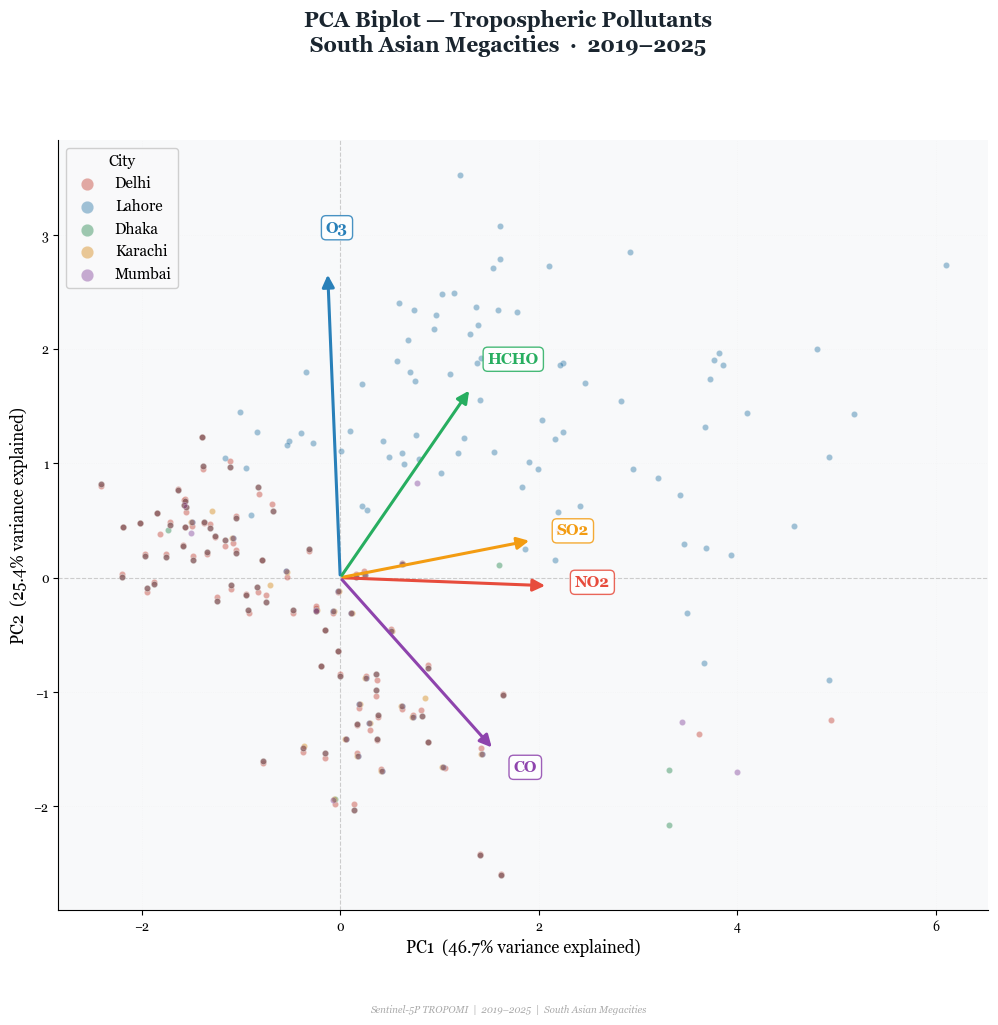

  ✓ Saved → Fig12_PCA_Biplot.png


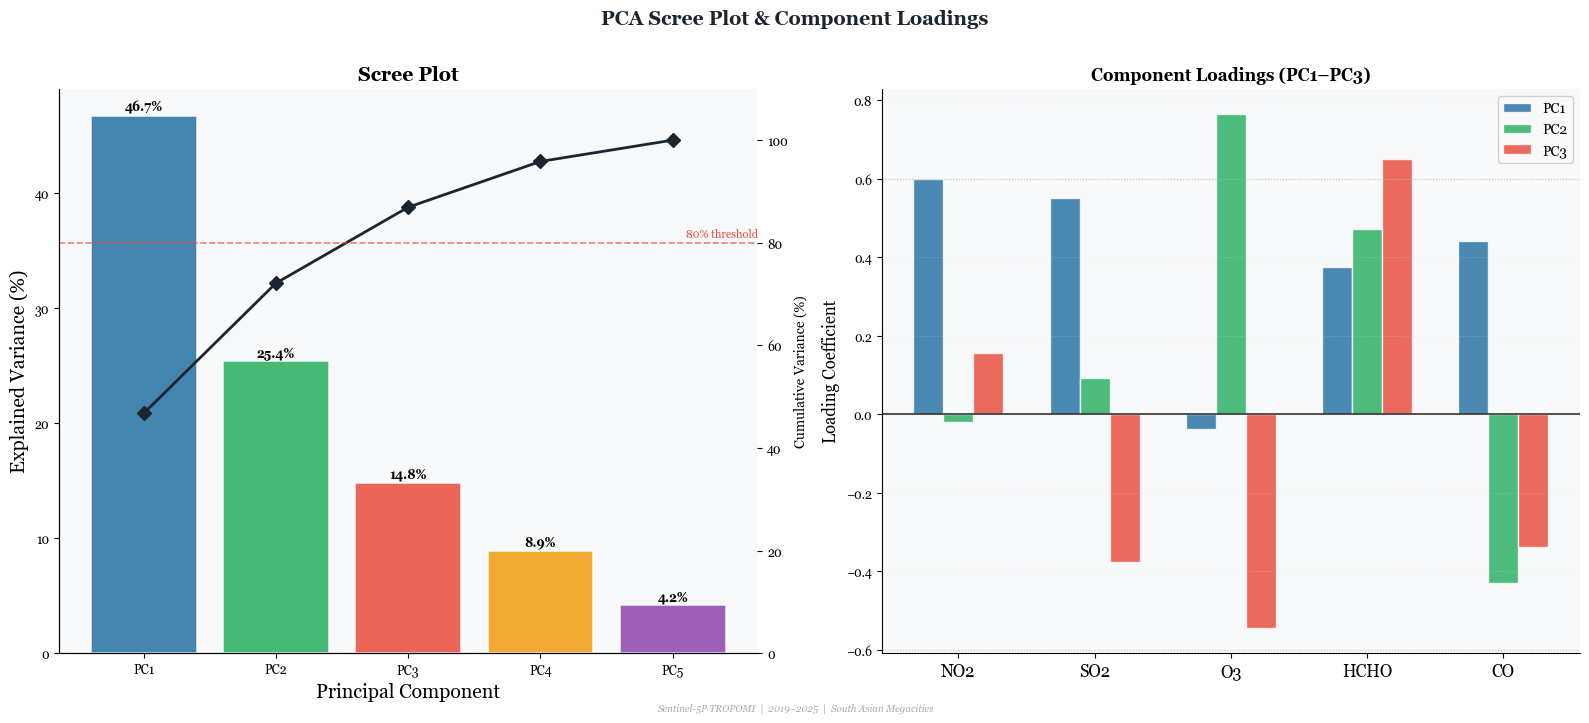

  ✓ Saved → Fig13_PCA_Scree_Loadings.png
✓ Figures 12 & 13 — PCA saved.


In [50]:
fig, ax = plt.subplots(figsize=(12, 10))
fig.suptitle("PCA Biplot — Tropospheric Pollutants\n"
             "South Asian Megacities  ·  2019–2025",
             fontsize=15, fontweight="bold", y=1.01, color="#1A252F")

for city in CITIES:
    mask = pca_df["City"] == city
    ax.scatter(pca_df.loc[mask,"PC1"], pca_df.loc[mask,"PC2"],
               color=CITY_COLORS[city], alpha=0.42, s=20,
               edgecolors="white", linewidths=0.3, label=city, zorder=3)

scale = 3.5
for gas in GASES:
    lx = float(loadings.loc[gas,"PC1"]) * scale
    ly = float(loadings.loc[gas,"PC2"]) * scale
    ax.annotate("", xy=(lx, ly), xytext=(0, 0),
                arrowprops=dict(arrowstyle="-|>", color=GAS_COLORS[gas],
                                lw=2.2, mutation_scale=18))
    ax.text(lx * 1.13, ly * 1.13, gas, color=GAS_COLORS[gas],
            fontsize=11, fontweight="bold",
            bbox=dict(boxstyle="round,pad=0.3", fc="white",
                      alpha=0.85, ec=GAS_COLORS[gas]))

ax.axhline(0, color="#CCCCCC", linewidth=0.8, linestyle="--")
ax.axvline(0, color="#CCCCCC", linewidth=0.8, linestyle="--")
ax.set_xlabel(f"PC1  ({ev[0]:.1f}% variance explained)", fontsize=12)
ax.set_ylabel(f"PC2  ({ev[1]:.1f}% variance explained)", fontsize=12)
ax.legend(title="City", fontsize=11, title_fontsize=11,
          framealpha=0.92, markerscale=2)
ax.grid(alpha=0.22, linestyle=":")
ax.set_facecolor("#F8F9FA")
add_watermark(fig)
save_fig(fig, out("pca","Fig12_PCA_Biplot.png"))

# ── Figure 13 — Scree Plot + Loading Bar Chart ───────────────────────────────
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 7))
fig.suptitle("PCA Scree Plot & Component Loadings",
             fontsize=14, fontweight="bold", y=1.01, color="#1A252F")

pc_labels = [f"PC{i+1}" for i in range(5)]
bar_colors = ["#2471A3","#27AE60","#E74C3C","#F39C12","#8E44AD"]

ax1.bar(pc_labels, ev, color=bar_colors, alpha=0.85,
        edgecolor="white", linewidth=1.2)
for i, val in enumerate(ev):
    ax1.text(i, val + 0.4, f"{val:.1f}%", ha="center",
             fontsize=9, fontweight="bold")

ax1_r = ax1.twinx()
cum   = np.cumsum(ev)
ax1_r.plot(pc_labels, cum, color="#1A252F", marker="D",
           markersize=7, linewidth=2, label="Cumulative %")
ax1_r.axhline(80, color="#E74C3C", linewidth=1.2,
              linestyle="--", alpha=0.7)
ax1_r.text(4.1, 81, "80% threshold", color="#E74C3C", fontsize=8)
ax1_r.set_ylabel("Cumulative Variance (%)", fontsize=10)
ax1_r.set_ylim(0, 110)
ax1.set_xlabel("Principal Component", fontsize=14)
ax1.set_ylabel("Explained Variance (%)", fontsize=14)
ax1.set_title("Scree Plot", fontsize=14, fontweight="bold")
ax1.set_facecolor("#F8F9FA")

# Loading bars for PC1, PC2, PC3
x_  = np.arange(5)
w_  = 0.22
for i, (pc, clr) in enumerate(zip(["PC1","PC2","PC3"],
                                    ["#2471A3","#27AE60","#E74C3C"])):
    ax2.bar(x_ + (i-1)*w_, loadings[pc], width=w_,
            label=pc, color=clr, alpha=0.82, edgecolor="white")

ax2.axhline(0,    color="#333", linewidth=1.2)
ax2.axhline(0.6,  color="#AAA", linewidth=0.8, linestyle=":", alpha=0.7)
ax2.axhline(-0.6, color="#AAA", linewidth=0.8, linestyle=":", alpha=0.7)
ax2.set_xticks(x_)
ax2.set_xticklabels(GASES, fontsize=12)
ax2.set_ylabel("Loading Coefficient", fontsize=12)
ax2.set_title("Component Loadings (PC1–PC3)", fontsize=12, fontweight="bold")
ax2.legend(fontsize=10)
ax2.grid(axis="y", alpha=0.35, linestyle=":")
ax2.set_facecolor("#F8F9FA")

plt.tight_layout()
add_watermark(fig)
save_fig(fig, out("pca","Fig13_PCA_Scree_Loadings.png"))
print("✓ Figures 12 & 13 — PCA saved.")

✓ Cophenetic Correlation Coefficient (CCC): 0.9922
   (Values > 0.75 = good clustering quality)


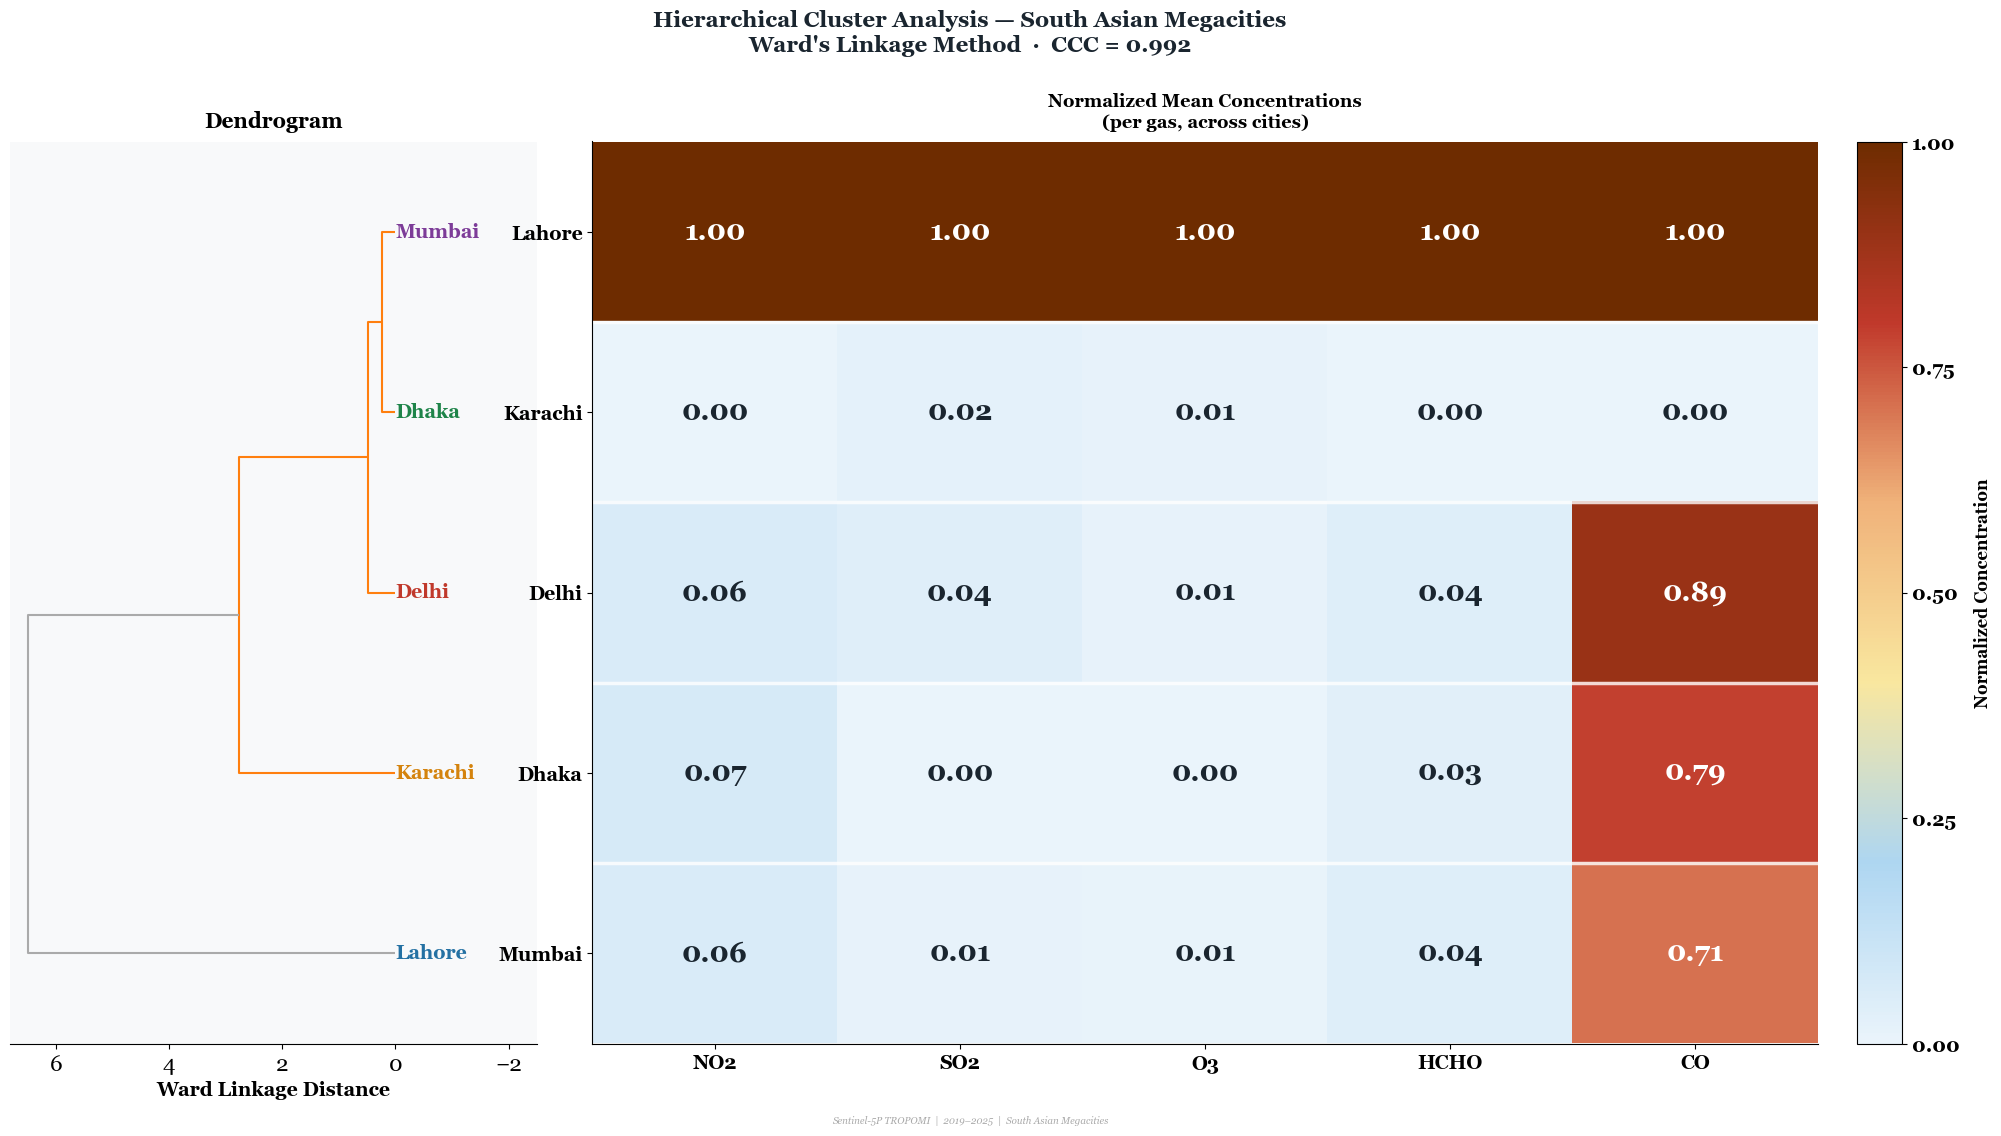

  ✓ Saved → Fig14_HCA_Dendrogram_Heatmap.png
✓ Figure 14 — HCA Dendrogram & Clustered Heatmap saved.


In [56]:
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from scipy.cluster import hierarchy
from scipy.spatial.distance import pdist
from sklearn.preprocessing import StandardScaler
import pandas as pd

# ── CONFIGURATION: Control text sizes easily here ────────────────────────────
CELL_FONTSIZE = 20  # ← Change this number to control the text size inside the heatmap boxes

city_means = pd.DataFrame({c: dfs[c][GASES].mean() for c in CITIES}).T
X_city     = StandardScaler().fit_transform(city_means.values)
dist_vec   = pdist(X_city, metric="euclidean")
Z_link     = hierarchy.linkage(dist_vec, method="ward")
ccc, _     = hierarchy.cophenet(Z_link, dist_vec)

print(f"✓ Cophenetic Correlation Coefficient (CCC): {ccc:.4f}")
print(f"   (Values > 0.75 = good clustering quality)")

# ── Figure setup ──────────────────────────────────────────────────────────────
fig = plt.figure(figsize=(20, 11))
gs  = gridspec.GridSpec(1, 2,
                         width_ratios=[1, 2.5],
                         wspace=0.06)
ax_d = fig.add_subplot(gs[0])
ax_h = fig.add_subplot(gs[1])

fig.suptitle(f"Hierarchical Cluster Analysis — South Asian Megacities\n"
             f"Ward's Linkage Method  ·  CCC = {ccc:.3f}",
             fontsize=16, fontweight="bold", y=1.02, color="#1A252F")

# ── Dendrogram ────────────────────────────────────────────────────────────────
dend = hierarchy.dendrogram(
    Z_link,
    labels             = CITIES,
    orientation        = "left",
    ax                 = ax_d,
    color_threshold    = 0.7 * max(Z_link[:,2]),
    above_threshold_color = "#AAAAAA",
    leaf_font_size     = 1,    # ← set to 1 — we draw our OWN labels below
                               #   this COMPLETELY removes the overlap
)

# ── FIX: Draw city name labels MANUALLY with full control ─────────────────────
ordered_cities = dend["ivl"]   # cities in dendrogram order (bottom to top)
n = len(ordered_cities)

# Dendrogram with orientation="left" places leaves on the Y-axis
y_positions = [5 + 10 * i for i in range(n)]  # [5, 15, 25, 35, 45]

for city, ypos in zip(ordered_cities, y_positions):
    ax_d.text(
        x          = 0,               # at the right edge of dendrogram (x=0 is leaf end)
        y          = ypos,
        s          = city,
        ha         = "left",          # left-align from x=0
        va         = "center",
        fontsize   = 14,              # ← city name size in dendrogram
        fontweight = "bold",
        color      = CITY_COLORS.get(city, "#1A252F"),
    )

# Adjust x-axis to leave room for the manually placed labels
x_left = ax_d.get_xlim()[1]
ax_d.set_xlim(right=-2.5)             # pull left so labels don't clip

ax_d.set_xlabel("Ward Linkage Distance", fontsize=14, fontweight="bold")
ax_d.set_title("Dendrogram", fontsize=15, fontweight="bold", pad=10)
ax_d.set_facecolor("#F8F9FA")
ax_d.tick_params(axis="x", labelsize=16)

# Remove the default y-axis tick labels (we replaced them manually)
ax_d.set_yticks([])
ax_d.spines["top"].set_visible(False)
ax_d.spines["right"].set_visible(False)
ax_d.spines["left"].set_visible(False)

# ── Heatmap ───────────────────────────────────────────────────────────────────
norm_means = (city_means - city_means.min()) / (
              city_means.max() - city_means.min() + 1e-30)

# Order heatmap rows to match dendrogram order
heatmap_data = norm_means.loc[ordered_cities]

im_h = ax_h.imshow(heatmap_data.values,
                    cmap=POLLUTION_CMAP,
                    aspect="auto",
                    vmin=0, vmax=1,
                    interpolation="nearest")

ax_h.set_xticks(range(5))
ax_h.set_xticklabels(GASES,
                      fontsize=14,          # ← gas name size
                      fontweight="bold")

ax_h.set_yticks(range(5))
ax_h.set_yticklabels(ordered_cities,
                      fontsize=14,          # ← city name size in heatmap
                      fontweight="bold")

ax_h.set_title("Normalized Mean Concentrations\n(per gas, across cities)",
               fontsize=13, fontweight="bold", pad=10)

# Values inside heatmap cells
for i, city in enumerate(ordered_cities):
    for j, gas in enumerate(GASES):
        val = float(norm_means.loc[city, gas])
        raw_val = float(city_means.loc[city, gas])
        ax_h.text(j, i,
                  f"{val:.2f}",
                  ha="center", va="center",
                  fontsize=CELL_FONTSIZE,    # ← Uses the variable defined at the top
                  fontweight="bold",
                  color="white" if val > 0.60 else "#1A252F")

# Colorbar
cb_h = plt.colorbar(im_h, ax=ax_h, fraction=0.04, pad=0.03)
cb_h.set_label("Normalized Concentration",
               fontsize=12, fontweight="bold", labelpad=10)
cb_h.ax.tick_params(labelsize=12)          # ← colorbar tick number size
cb_h.set_ticks([0, 0.25, 0.5, 0.75, 1.0])
cb_h.set_ticklabels(["0.00","0.25","0.50","0.75","1.00"],
                     fontsize=14, fontweight="bold")

# ── Cluster boundary lines on heatmap ─────────────────────────────────────────
cluster_boundaries = []
for k in range(1, n):
    city_a = ordered_cities[k-1]
    city_b = ordered_cities[k]
    cluster_boundaries.append(k - 0.5)

for boundary in cluster_boundaries:
    ax_h.axhline(boundary, color="white", linewidth=2.5, alpha=0.8)

plt.tight_layout()
fig.subplots_adjust(top=0.90, bottom=0.08, left=0.02, right=0.97)

add_watermark(fig)
save_fig(fig, out("pca","Fig14_HCA_Dendrogram_Heatmap.png"))
print("✓ Figure 14 — HCA Dendrogram & Clustered Heatmap saved.")

## CELL 25 — FINAL COMPREHENSIVE SUMMARY DASHBOARD

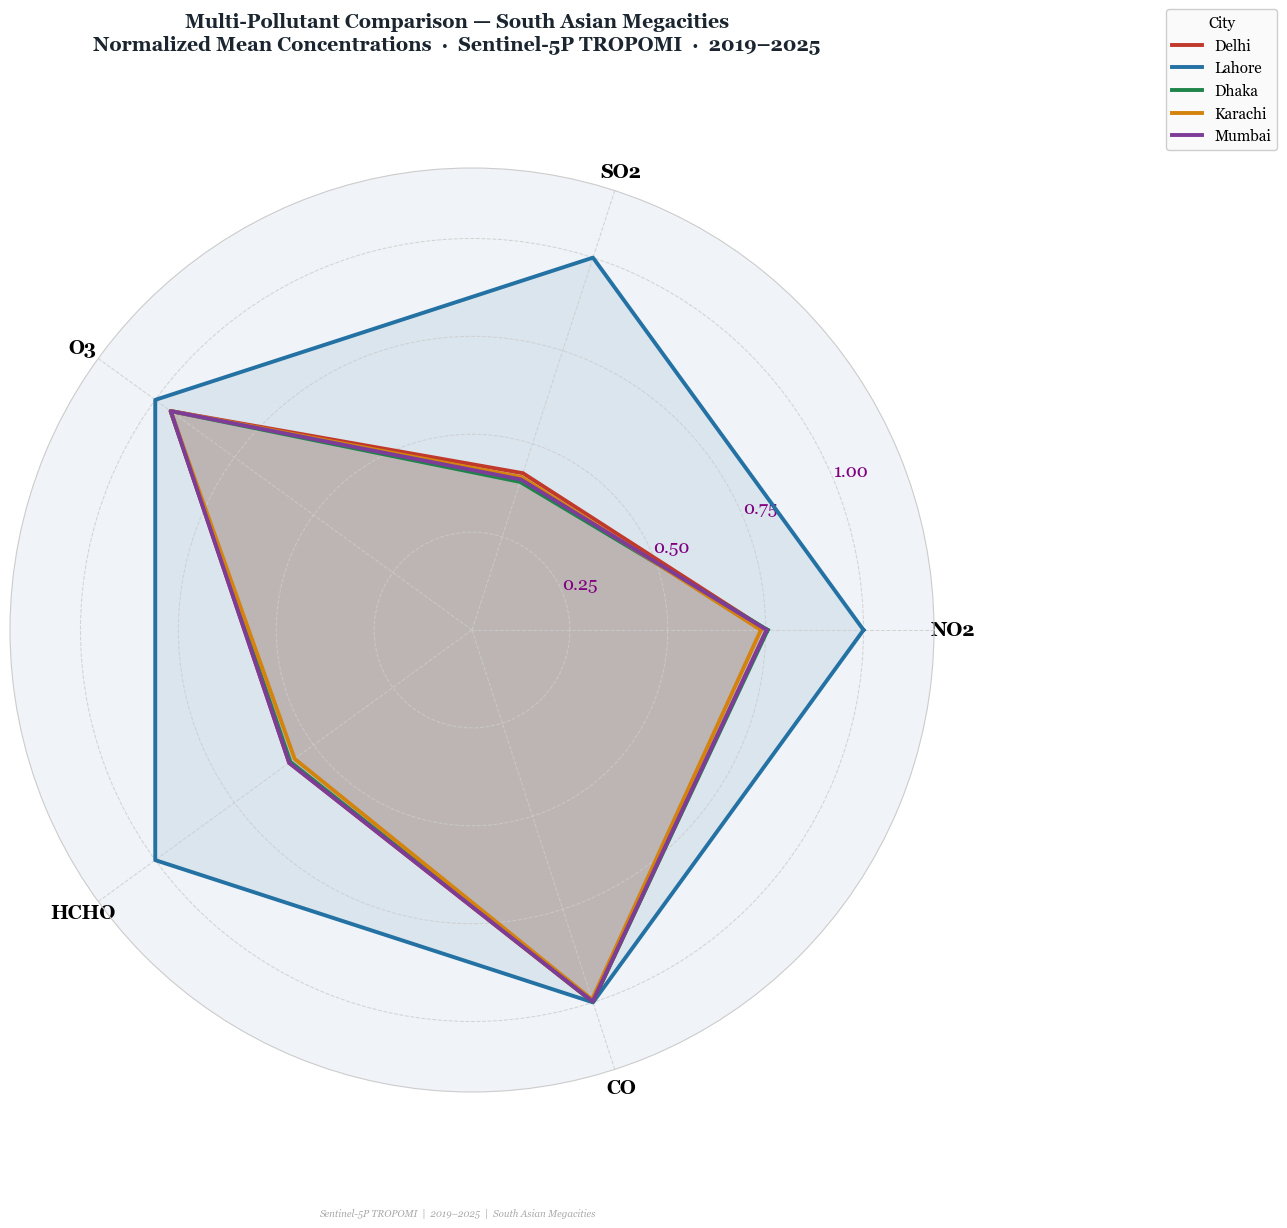

  ✓ Saved → Fig15_Radar_Chart_Cross_City.png
✓ Figure 15 — Radar Chart saved.

  Overall Composite Pollution Index (higher = more polluted):
  Lahore    : 1.000  ████████████████████
  Delhi     : 0.740  ██████████████
  Mumbai    : 0.737  ██████████████
  Dhaka     : 0.735  ██████████████
  Karachi   : 0.730  ██████████████


In [71]:
city_gas_means = pd.DataFrame({c: dfs[c][GASES].mean() for c in CITIES}).T
norm_radar     = city_gas_means.div(city_gas_means.max())   # normalize 0-1

N      = len(GASES)
angles = np.linspace(0, 2 * np.pi, N, endpoint=False).tolist()
angles += angles[:1]                                         # close the loop

fig, ax = plt.subplots(figsize=(12, 12), subplot_kw=dict(polar=True))
fig.patch.set_facecolor("white")
ax.set_facecolor("#F0F3F7")
fig.suptitle("Multi-Pollutant Comparison — South Asian Megacities\n"
             "Normalized Mean Concentrations  ·  Sentinel-5P TROPOMI  ·  2019–2025",
             fontsize=14, fontweight="bold", y=1.01, color="#1A252F")

for city in CITIES:
    values = norm_radar.loc[city].tolist()
    values += values[:1]
    ax.plot(angles, values, color=CITY_COLORS[city],
            linewidth=2.8, linestyle="-", label=city)
    ax.fill(angles, values, color=CITY_COLORS[city], alpha=0.10)

ax.set_xticks(angles[:-1])
ax.set_xticklabels(GASES, fontsize=14, fontweight="bold")
ax.set_yticks([0.25, 0.50, 0.75, 1.00])
ax.set_yticklabels(["0.25","0.50","0.75","1.00"], fontsize=13, color="#800080")
ax.set_ylim(0, 1.18)
ax.grid(color="#CCCCCC", linestyle="--", linewidth=0.75, alpha=0.8)
ax.spines["polar"].set_edgecolor("#CCCCCC")
ax.legend(loc="upper right", bbox_to_anchor=(1.38, 1.18),
          fontsize=11, title="City", title_fontsize=11, framealpha=0.95)

add_watermark(fig)
save_fig(fig, out("crosscity","Fig15_Radar_Chart_Cross_City.png"))

# Ranking and composite index tables
rank_df    = city_gas_means.rank(ascending=False).astype(int)
composite  = norm_radar.mean(axis=1).sort_values(ascending=False)
rank_df.to_csv(out("tables","Cross_City_Ranking.csv"))
composite.to_frame("Composite Pollution Index").to_csv(out("tables","Composite_Index.csv"))

print("✓ Figure 15 — Radar Chart saved.")
print("\n  Overall Composite Pollution Index (higher = more polluted):")
for city, val in composite.items():
    bar = "█" * int(val * 20)
    print(f"  {city:10s}: {val:.3f}  {bar}")

## CELL 26 — FINAL REPORT: PRINT ALL RESULTS SUMMARY

In [73]:
print("\n" + "="*70)
print("  ✅  ALL ANALYSES COMPLETE")
print("="*70)
print(f"\n  Output root: {OUTPUT_ROOT}\n")

for k, folder in FOLDERS.items():
    path  = os.path.join(OUTPUT_ROOT, folder)
    files = [f for f in os.listdir(path) if not f.startswith(".")]
    print(f"  📁 {folder}/")
    for f in sorted(files):
        print(f"       └─ {f}")

print("""
  ─────────────────────────────────────────────────────────────
  FIGURE SUMMARY
  ─────────────────────────────────────────────────────────────
  Fig 1   Descriptive Stats Bars       → 01_Descriptive_Statistics/
  Fig 2   Time Series (5 gases)        → 02_Temporal_Analysis/
  Fig 3   Seasonal Box Plots 5×5       → 03_Seasonal_Analysis/
  Fig 4   Annual Bar Chart             → 02_Temporal_Analysis/
  Fig 5   Monthly Heatmaps (×5 gases)  → 02_Temporal_Analysis/
  Fig 6   STL Decomposition (×5 gases) → 10_STL_Decomposition/
  Fig 7   MK Trend Heatmap             → 04_Trend_Analysis/
  Fig 8a  COVID Anomaly Bar Chart      → 05_COVID_Impact/
  Fig 8b  Z-Score Anomaly Heatmap      → 05_COVID_Impact/
  Fig 9   Change Point Detection       → 09_Change_Point_Detection/
  Fig 10  Inter-Pollutant Correlation  → 06_Correlation_Analysis/
  Fig 11  Inter-City Correlation       → 06_Correlation_Analysis/
  Fig 12  PCA Biplot                   → 07_Multivariate_PCA_HCA/
  Fig 13  Scree Plot + Loadings        → 07_Multivariate_PCA_HCA/
  Fig 14  HCA Dendrogram               → 07_Multivariate_PCA_HCA/
  Fig 15  Radar Chart                  → 08_Cross_City_Comparison/
  Fig 16  Lagged Cross-Correlation     → 06_Correlation_Analysis/
  DASH    Summary Dashboard            → 08_Cross_City_Comparison/
  ─────────────────────────────────────────────────────────────
  TABLE SUMMARY (all CSV in 11_Summary_Tables/)
  ─────────────────────────────────────────────────────────────
  Table 2  Descriptive Statistics
  Table 3  Mann-Kendall + Sen's Slope
  Table 4  Seasonal Mean Summary
  Table 5  COVID-19 Lockdown Impact
  Table 6  Kruskal-Wallis Test
  Table 7  PCA Loadings
  +  Spearman Correlation
  +  Inter-Pollutant Pearson Correlation
  +  STL Strength Indices (Fs, Ft)
  +  Change Point Summary
  +  Annual Summary
  +  Cross-City Ranking
  +  Composite Pollution Index
  ─────────────────────────────────────────────────────────────
""")


  ✅  ALL ANALYSES COMPLETE

  Output root: S:\R & P\Research\ALL RESEARCH

  📁 01_Descriptive_Statistics/
       └─ Fig1_Descriptive_Stats_Mean_Bars.png
  📁 02_Temporal_Analysis/
       └─ Fig2_Time_Series_All_Gases_Cities.png
       └─ Fig4_Annual_Mean_Grouped_Bar.png
       └─ Fig5_Monthly_Heatmap_CO.png
       └─ Fig5_Monthly_Heatmap_HCHO.png
       └─ Fig5_Monthly_Heatmap_NO2.png
       └─ Fig5_Monthly_Heatmap_O3.png
       └─ Fig5_Monthly_Heatmap_SO2.png
  📁 03_Seasonal_Analysis/
       └─ Fig3_Seasonal_BoxPlots_5x5.png
       └─ Fig_Seasonal_Heatmap_Normalized.png
  📁 04_Trend_Analysis/
       └─ Fig7_MannKendall_Trend_Heatmap.png
  📁 05_COVID_Impact/
       └─ Fig8a_COVID_Anomaly_Bar.png
       └─ Fig8b_Zscore_Anomaly_Heatmap.png
  📁 06_Correlation_Analysis/
       └─ Fig10_InterPollutant_Correlation.png
       └─ Fig11_InterCity_Correlation.png
       └─ Fig16_Lagged_CrossCorrelation.png
  📁 07_Multivariate_PCA_HCA/
       └─ Fig12_PCA_Biplot.png
       └─ Fig13_PCA_Scree_Load